# 00. Python Libraries for AI

## 📚 Learning Objectives

By completing this notebook, you will:
- Use NumPy, Pandas, and basic AI-related libraries
- Load data and run simple ML workflows

## 🔗 Where this fits

**Builds on:** Course 01 (AIAT 111) — Unit 1, lesson 03 "Python for AI Development" — the same NumPy and file-handling toolkit, extended with the libraries every later notebook imports.

**Used later in:** Course 05 (AIAT 115) — Unit 1, where NumPy and pandas become the everyday tools of data science.

---


## 🌍 Before the tour: what this toolbox actually built

The NumPy team's own paper — Harris et al., *Array Programming with NumPy*, **Nature 585, 357–362 (2020)**, reference 1 at the foot of this notebook — puts it in one sentence: *"in astronomy, NumPy was an important part of the software stack used in the discovery of gravitational waves and the first imaging of a black hole."*

Two dated results, not a slogan:

- **LIGO, 14 September 2015** (announced 11 February 2016) — the first direct detection of a gravitational wave, two black holes merging 1.3 billion light years away, measured as a change in a 4 km detector arm smaller than a proton.
- **Event Horizon Telescope, 10 April 2019** — the first image of a black hole's shadow, M87*, assembled from radio telescopes on four continents.

Neither collaboration wrote its own array library. They imported the same handful of names you are about to import: `numpy`, `scipy`, `matplotlib`.

### What goes wrong without them

Two failure modes, and the second is the one that should worry you.

1. **Speed.** A pure-Python loop pays the interpreter's overhead on *every single element*; a NumPy call pays it once for the whole array. The gap is usually a factor of ten or more — and rather than take a tutorial's word for it, Part 2 below measures it on the machine you are sitting at, then holds the measurement up against the figure this notebook itself quotes. On a real training run it is the difference between a coffee break and an overnight job.
2. **Silent wrongness.** Numerical code is easy to get subtly wrong. The tidy "computational formula" for variance, `(Σx² − (Σx)²/n) / n`, is algebraically correct and numerically dangerous: when the values are large but close together, those two big sums nearly cancel and the answer comes back wrong — sometimes a negative variance. Library implementations use algorithms built to avoid that cancellation.

Slowness announces itself. A wrong number does not: your hand-rolled function still returns a float, and you still put it in the report. That, more than convenience, is the argument for the toolbox.

---


## Part 1: Installation & Setup


In [1]:
# Install all required libraries for AI course
# Run this cell once to install everything

print("=" * 70)
print("📦 INSTALLING PYTHON LIBRARIES FOR AI")
print("=" * 70)
print()
print("⚠️  IMPORTANT: To avoid conflicts, use ../../requirements.txt!")
print()
print("📋 Recommended Installation Method:")
print("   1. Open terminal/command prompt")
print("   2. Navigate to the root AI Diploma directory")
print("   3. Run: pip install -r requirements.txt")
print()
print("📋 Required libraries (from ../../requirements.txt):")
print("  • numpy>=1.24.0: Numerical computing")
print("  • scipy>=1.10.0: Scientific computing")
print("  • matplotlib>=3.7.0: Visualization")
print("  • scikit-learn>=1.3.0: Machine learning")
print("  • networkx>=3.0: Graph operations")
print("  • pandas>=2.0.0: Data manipulation")
print("  • seaborn>=0.12.0: Statistical visualization")
print("  • tqdm>=4.65.0: Progress bars")
print("  • requests>=2.31.0: API calls")
print("  • joblib>=1.3.0: Model saving")
print()
print("📋 Optional libraries (advanced - install only if needed):")
print("  • tensorflow>=2.13.0: Deep learning (optional - advanced)")
print("  • torch>=2.0.0: PyTorch deep learning (optional - advanced)")
print("  • opencv-python>=4.8.0: Computer vision (optional - advanced)")
print("  • pillow>=10.0.0: Image processing (optional)")
print("  • nltk>=3.8.0: Natural Language Processing (optional - advanced)")
print("  • spacy>=3.6.0: Modern NLP (optional - advanced)")
print()
print("📋 Built-in libraries (no installation needed):")
print("  • json: Data formats (built-in)")
print("  • pickle: Model saving (built-in)")
print("  • collections: Data structures (built-in)")
print("  • heapq: Priority queues (built-in)")
print()
print("💡 These versions are tested together - no conflicts!")
print()
print("📖 For detailed installation instructions, see:")
print("   • DOCS/INSTALLATION_GUIDE.md (complete guide)")
print("   • ../../requirements.txt (compatible versions)")
print()

# Quick install option (if ../../requirements.txt doesn't work)
print("=" * 70)
print("⚡ QUICK INSTALL (Alternative method)")
print("=" * 70)
print()
print("If you prefer to install from this notebook, uncomment below:")
print()
print("# STEP 1: Upgrade pip first")
print("# !pip install --upgrade pip")
print()
print("# STEP 2: Install required libraries in order (prevents conflicts)")
print("# !pip install numpy>=1.24.0")
print("# !pip install scipy>=1.10.0")
print("# !pip install matplotlib>=3.7.0")
print("# !pip install scikit-learn>=1.3.0")
print("# !pip install networkx>=3.0")
print("# !pip install pandas>=2.0.0")
print("# !pip install seaborn>=0.12.0")
print("# !pip install tqdm>=4.65.0")
print("# !pip install requests>=2.31.0")
print("# !pip install joblib>=1.3.0")
print()
print("# STEP 3: Optional - Install advanced libraries only if needed")
print("# !pip install tensorflow>=2.13.0  # Deep learning (optional)")
print("# !pip install torch>=2.0.0  # PyTorch (optional)")
print("# !pip install opencv-python>=4.8.0  # Computer vision (optional)")
print("# !pip install pillow>=10.0.0  # Image processing (optional)")
print("# !pip install nltk>=3.8.0  # NLP (optional)")
print("# !pip install spacy>=3.6.0  # NLP (optional)")
print()

# Verify installation
print("=" * 70)
print("✅ VERIFYING INSTALLATION")
print("=" * 70)
print()

# Verify required libraries
print("📋 Verifying Required Libraries:")
print()

# Map each display name to its import name so we can test every required library in one loop.
# Why: a single missing library would otherwise fail silently halfway through the course.
required_libs = {
    "NumPy": ("numpy", "np"),
    "SciPy": ("scipy", None),
    "Matplotlib": ("matplotlib", None),
    "Scikit-learn": ("sklearn", None),
    "NetworkX": ("networkx", "nx"),
    "Pandas": ("pandas", "pd"),
    "Seaborn": ("seaborn", "sns"),
    "tqdm": ("tqdm", None),
    "Requests": ("requests", None),
    "Joblib": ("joblib", None)
}

imported_libs = {}
missing_libs = []

# Try importing each library; __import__ lets us import from a string name inside a loop.
for lib_name, (module_name, alias) in required_libs.items():
    try:
        if alias:
            module = __import__(module_name, globals(), locals(), [alias], 0)
        else:
            module = __import__(module_name)
        
        imported_libs[lib_name] = module
        version = getattr(module, "__version__", "installed")
        print(f"   ✅ {lib_name}: {version}")
    except ImportError:
        missing_libs.append(lib_name)
        print(f"   ❌ {lib_name}: NOT INSTALLED")

print()

if missing_libs:
    print(f"❌ Missing libraries: {', '.join(missing_libs)}")
    print("   Please install using: pip install -r ../../requirements.txt")
    print("   See INSTALLATION_GUIDE.md for help")
else:
    print("✅ All required libraries installed successfully!")
    print()

# Verify optional libraries
print("📋 Verifying Optional Libraries (Advanced):")
print()

optional_libs = {
    "TensorFlow": "tensorflow", "PyTorch": "torch",
    "OpenCV": "cv2",
    "Pillow": "PIL",
    "NLTK": "nltk",
    "spaCy": "spacy"
}

optional_installed = []
optional_missing = []

# Same import check for optional deep-learning/NLP libraries - missing ones are OK here.
for lib_name, module_name in optional_libs.items():
    try:
        module = __import__(module_name)
        version = getattr(module, "__version__", "installed")
        optional_installed.append(lib_name)
        print(f"   ✅ {lib_name}: {version} (installed)")
    except ImportError:
        optional_missing.append(lib_name)
        print(f"   ⚠️  {lib_name}: NOT INSTALLED (optional)")

print()

if optional_installed:
    print(f"✅ Optional libraries installed: {', '.join(optional_installed)}")
    print()

if optional_missing:
    print(f"💡 Optional libraries not installed: {', '.join(optional_missing)}")
    print("   These are optional - install only if needed for advanced projects")
    print("   See ../../requirements.txt for installation commands")
    print()

# Verify built-in libraries
print("📋 Verifying Built-in Libraries:")
print()

import json
import numpy as np
import pickle
from collections import deque
import heapq

print("   ✅ JSON: available (built-in)")
print("   ✅ Pickle: available (built-in)")
print("   ✅ Collections: available (built-in)")
print("   ✅ heapq: available (built-in)")
print()

print("=" * 70)
print("✅ INSTALLATION VERIFICATION COMPLETE")
print("=" * 70)
print()

if not missing_libs:
    print("🎉 All required libraries are installed - you're ready to go!")
    print("💡 Optional libraries can be installed later if needed")
else:
    print("⚠️  Please install missing libraries first:")
    print(f"   pip install {' '.join([lib.lower().replace(' ', '-').replace('scikit-learn', 'scikit-learn') for lib in missing_libs])}")
    print("   Or use: pip install -r ../../requirements.txt")

📦 INSTALLING PYTHON LIBRARIES FOR AI

⚠️  IMPORTANT: To avoid conflicts, use ../../requirements.txt!

📋 Recommended Installation Method:
   1. Open terminal/command prompt
   2. Navigate to the root AI Diploma directory
   3. Run: pip install -r requirements.txt

📋 Required libraries (from ../../requirements.txt):
  • numpy>=1.24.0: Numerical computing
  • scipy>=1.10.0: Scientific computing
  • matplotlib>=3.7.0: Visualization
  • scikit-learn>=1.3.0: Machine learning
  • networkx>=3.0: Graph operations
  • pandas>=2.0.0: Data manipulation
  • seaborn>=0.12.0: Statistical visualization
  • tqdm>=4.65.0: Progress bars
  • requests>=2.31.0: API calls
  • joblib>=1.3.0: Model saving

📋 Optional libraries (advanced - install only if needed):
  • tensorflow>=2.13.0: Deep learning (optional - advanced)
  • torch>=2.0.0: PyTorch deep learning (optional - advanced)
  • opencv-python>=4.8.0: Computer vision (optional - advanced)
  • pillow>=10.0.0: Image processing (optional)
  • nltk>=3.8.0: 

   ✅ Matplotlib: 3.10.8


   ✅ Scikit-learn: 1.8.0
   ✅ NetworkX: 3.6.1
   ✅ Pandas: 2.3.3


   ✅ Seaborn: 0.13.2
   ✅ tqdm: 4.70.0
   ✅ Requests: 2.34.2
   ✅ Joblib: 1.5.3

✅ All required libraries installed successfully!

📋 Verifying Optional Libraries (Advanced):

   ⚠️  TensorFlow: NOT INSTALLED (optional)


   ✅ PyTorch: 2.13.0 (installed)


   ✅ OpenCV: 5.0.0 (installed)
   ✅ Pillow: 12.2.0 (installed)


   ✅ NLTK: 3.10.3 (installed)


   ✅ spaCy: 3.8.13 (installed)

✅ Optional libraries installed: PyTorch, OpenCV, Pillow, NLTK, spaCy

💡 Optional libraries not installed: TensorFlow
   These are optional - install only if needed for advanced projects
   See ../../requirements.txt for installation commands

📋 Verifying Built-in Libraries:

   ✅ JSON: available (built-in)
   ✅ Pickle: available (built-in)
   ✅ Collections: available (built-in)
   ✅ heapq: available (built-in)

✅ INSTALLATION VERIFICATION COMPLETE

🎉 All required libraries are installed - you're ready to go!
💡 Optional libraries can be installed later if needed


In [2]:
# 📚 QUICK REFERENCE: NumPy Most Commonly Used Functions
# Complete cheat sheet of functions you'll use in AI projects

# HOW TO USE THIS CELL: it computes nothing new - it prints a cheat sheet you can re-open while coding, so you never have to memorize function names.

import numpy as np

print("=" * 70)
print("📚 NUMPY FUNCTION REFERENCE - Most Commonly Used Functions")
print("=" * 70)
print()

print("🔹 ARRAY CREATION:")
print("   np.array([1, 2, 3])                    # Create from list")
print("   np.zeros(5)                            # Array of zeros: [0, 0, 0, 0, 0]")
print("   np.ones(5)                             # Array of ones: [1, 1, 1, 1, 1]")
print("   np.arange(0, 10, 2)                    # Like range(): [0, 2, 4, 6, 8]")
print("   np.linspace(0, 1, 5)                   # Evenly spaced: [0, 0.25, 0.5, 0.75, 1]")
print("   np.empty((3, 3))                       # Uninitialized array (fast)")
print("   np.full((2, 3), 7)                     # Array filled with value: all 7s")
print("   np.eye(3)                              # Identity matrix (3x3)")
print("   np.random.rand(5)                      # Random [0,1): 5 numbers")
print("   np.random.randn(5)                     # Random normal: mean=0, std=1")
print("   np.random.randint(0, 10, 5)            # Random integers: 5 numbers from [0,10)")
print()

print("🔹 ARRAY PROPERTIES:")
print("   arr.shape                              # Dimensions: (3, 4)")
print("   arr.size                               # Total elements: 12")
print("   arr.dtype                              # Data type: int64, float64")
print("   arr.ndim                               # Number of dimensions: 2")
print()

print("🔹 ARRAY OPERATIONS (Element-wise):")
print("   arr1 + arr2                            # Addition")
print("   arr1 - arr2                            # Subtraction")
print("   arr1 * arr2                            # Multiplication")
print("   arr1 / arr2                            # Division")
print("   arr ** 2                               # Power")
print("   arr % 2                                # Modulo")
print()

print("🔹 STATISTICAL FUNCTIONS:")
print("   np.mean(arr)                           # Average value")
print("   np.median(arr)                         # Median value")
print("   np.std(arr)                            # Standard deviation")
print("   np.var(arr)                            # Variance")
print("   np.min(arr)                            # Minimum value")
print("   np.max(arr)                            # Maximum value")
print("   np.sum(arr)                            # Sum of all elements")
print("   np.prod(arr)                           # Product of all elements")
print("   np.percentile(arr, 75)                 # 75th percentile")
print()

print("🔹 ARRAY MANIPULATION:")
print("   arr.reshape(3, 4)                      # Reshape to 3x4")
print("   arr.flatten()                          # Flatten to 1D")
print("   np.concatenate([arr1, arr2])           # Join arrays")
print("   np.split(arr, 3)                       # Split array into 3 parts")
print("   arr.T                                  # Transpose")
print("   np.sort(arr)                           # Sort array")
print("   np.argsort(arr)                        # Indices that would sort")
print()

print("🔹 INDEXING & SLICING:")
print("   arr[0]                                 # First element")
print("   arr[1:4]                               # Slice: elements 1,2,3")
print("   arr[-1]                                # Last element")
print("   arr[arr > 5]                           # Boolean indexing: elements > 5")
print("   arr[[0, 2, 4]]                         # Fancy indexing: select indices")
print()

print("🔹 MATRIX OPERATIONS:")
print("   np.dot(A, B)                           # Matrix multiplication")
print("   A @ B                                  # Matrix multiplication (Python 3.5+)")
print("   np.linalg.inv(A)                       # Matrix inverse")
print("   np.linalg.det(A)                       # Determinant")
print("   np.linalg.eig(A)                       # Eigenvalues & eigenvectors")
print()

print("🔹 MATH FUNCTIONS:")
print("   np.sqrt(arr)                           # Square root")
print("   np.exp(arr)                            # Exponential")
print("   np.log(arr)                            # Natural logarithm")
print("   np.sin(arr), np.cos(arr)               # Trigonometric")
print("   np.abs(arr)                            # Absolute value")
print()

print("💡 TIP: These functions work on entire arrays at once - very fast!")
print("💡 TIP: Most functions can work with axis parameter: axis=0 (rows), axis=1 (columns)")


📚 NUMPY FUNCTION REFERENCE - Most Commonly Used Functions

🔹 ARRAY CREATION:
   np.array([1, 2, 3])                    # Create from list
   np.zeros(5)                            # Array of zeros: [0, 0, 0, 0, 0]
   np.ones(5)                             # Array of ones: [1, 1, 1, 1, 1]
   np.arange(0, 10, 2)                    # Like range(): [0, 2, 4, 6, 8]
   np.linspace(0, 1, 5)                   # Evenly spaced: [0, 0.25, 0.5, 0.75, 1]
   np.empty((3, 3))                       # Uninitialized array (fast)
   np.full((2, 3), 7)                     # Array filled with value: all 7s
   np.eye(3)                              # Identity matrix (3x3)
   np.random.rand(5)                      # Random [0,1): 5 numbers
   np.random.randn(5)                     # Random normal: mean=0, std=1
   np.random.randint(0, 10, 5)            # Random integers: 5 numbers from [0,10)

🔹 ARRAY PROPERTIES:
   arr.shape                              # Dimensions: (3, 4)
   arr.size                      

## Part 2: NumPy - Numerical Computing

### 📚 What is NumPy?
NumPy = **Num**erical **Py**thon - it provides fast arrays and mathematical operations!

**THE PROBLEM**: Python lists are slow for math operations.
**THE SOLUTION**: NumPy arrays are fast - 100x faster for numerical operations!

**Why NumPy for AI?**
- AI needs lots of mathematical calculations (matrices, vectors)
- NumPy makes these calculations FAST
- All AI libraries (scikit-learn, TensorFlow) use NumPy arrays internally

In [3]:
# NumPy Basics: Creating and Working with Arrays

import numpy as np  # Import NumPy (standard: use 'np' as alias)

print("=" * 70)
print("✅ AFTER: NumPy Arrays (Fast Numerical Computing)")
print("=" * 70)
print()

# 1. Creating NumPy arrays
print("📊 Step 1: Creating NumPy Arrays")
print()

# From Python list
python_list = [1, 2, 3, 4, 5]
numpy_array = np.array(python_list)  # Convert list to NumPy array

print(f"   Python list: {python_list}")
print(f"   NumPy array: {numpy_array}")
print(f"   Array type: {type(numpy_array)}")
print(f"   Array shape: {numpy_array.shape}")  # Shape = dimensions
print()

# Create arrays with useful functions
zeros = np.zeros(5)  # Array of zeros: [0, 0, 0, 0, 0]
ones = np.ones(5)    # Array of ones: [1, 1, 1, 1, 1]
range_array = np.arange(0, 10, 2)  # Like range(): [0, 2, 4, 6, 8]
linspace = np.linspace(0, 1, 5)  # 5 evenly spaced numbers: [0, 0.25, 0.5, 0.75, 1]

print("   Useful array creation functions:")
print(f"   np.zeros(5): {zeros}")
print(f"   np.ones(5): {ones}")
print(f"   np.arange(0, 10, 2): {range_array}")
print(f"   np.linspace(0, 1, 5): {linspace}")
print()

# 2. Array operations (THE POWER OF NUMPY!)
print("📊 Step 2: Array Operations (Fast Math!)")
print()

arr1 = np.array([1, 2, 3])
arr2 = np.array([4, 5, 6])

# Element-wise operations (operates on each element)
addition = arr1 + arr2  # [1+4, 2+5, 3+6] = [5, 7, 9]
subtraction = arr2 - arr1  # [4-1, 5-2, 6-3] = [3, 3, 3]
multiplication = arr1 * 2  # [1*2, 2*2, 3*2] = [2, 4, 6]
power = arr1 ** 2  # [1², 2², 3²] = [1, 4, 9]

print(f"   Array 1: {arr1}")
print(f"   Array 2: {arr2}")
print(f"   arr1 + arr2 = {addition}")
print(f"   arr2 - arr1 = {subtraction}")
print(f"   arr1 * 2 = {multiplication}")
print(f"   arr1 ** 2 = {power}")
print()

# 3. 2D arrays (matrices)
print("📊 Step 3: 2D Arrays (Matrices)")
print()

matrix = np.array([[1, 2, 3],
                   [4, 5, 6],
                   [7, 8, 9]])

print(f"   Matrix:")
print(f"   {matrix}")
print(f"   Shape: {matrix.shape}")  # (3 rows, 3 columns)
print(f"   Size: {matrix.size}")  # Total elements: 9
print()

# 4. Most common operations in AI
print("📊 Step 4: Most Common NumPy Operations in AI")
print()

data = np.array([1, 5, 3, 9, 2, 8, 4])

print(f"   Data: {data}")
print(f"   Mean (average): {np.mean(data):.2f}")
print(f"   Max: {np.max(data)}")
print(f"   Min: {np.min(data)}")
print(f"   Sum: {np.sum(data)}")
print(f"   Standard deviation: {np.std(data):.2f}")
print()

# Random numbers (very common in AI!)
print("   Random numbers (used for simulations, initialization):")
np.random.seed(42)  # For reproducible results
random_array = np.random.rand(5)  # 5 random numbers between 0 and 1
print(f"   np.random.rand(5): {random_array}")
print()

print("🔗 HOW THIS HELPS IN AI:")
print("   • Fast calculations: NumPy is 100x faster than Python lists")
print("   • Matrix operations: AI uses matrices everywhere (neural networks, data)")
print("   • Easy to use: Simple syntax for complex operations")
print()
print("📊 BEFORE vs AFTER:")
print("   BEFORE: Python lists → Slow for math, complicated operations")
print("   AFTER: NumPy arrays → Fast, simple, powerful!")


✅ AFTER: NumPy Arrays (Fast Numerical Computing)

📊 Step 1: Creating NumPy Arrays

   Python list: [1, 2, 3, 4, 5]
   NumPy array: [1 2 3 4 5]
   Array type: <class 'numpy.ndarray'>
   Array shape: (5,)

   Useful array creation functions:
   np.zeros(5): [0. 0. 0. 0. 0.]
   np.ones(5): [1. 1. 1. 1. 1.]
   np.arange(0, 10, 2): [0 2 4 6 8]
   np.linspace(0, 1, 5): [0.   0.25 0.5  0.75 1.  ]

📊 Step 2: Array Operations (Fast Math!)

   Array 1: [1 2 3]
   Array 2: [4 5 6]
   arr1 + arr2 = [5 7 9]
   arr2 - arr1 = [3 3 3]
   arr1 * 2 = [2 4 6]
   arr1 ** 2 = [1 4 9]

📊 Step 3: 2D Arrays (Matrices)

   Matrix:
   [[1 2 3]
 [4 5 6]
 [7 8 9]]
   Shape: (3, 3)
   Size: 9

📊 Step 4: Most Common NumPy Operations in AI

   Data: [1 5 3 9 2 8 4]
   Mean (average): 4.57
   Max: 9
   Min: 1
   Sum: 32
   Standard deviation: 2.77

   Random numbers (used for simulations, initialization):
   np.random.rand(5): [0.37454012 0.95071431 0.73199394 0.59865848 0.15601864]

🔗 HOW THIS HELPS IN AI:
   • Fast

### Measure it, don't quote it

"NumPy is 100× faster" is repeated in every tutorial, including the paragraph just above this one. The professional habit is to produce the number yourself, on the machine you are actually using, and to check that both versions computed the *same answer* before comparing their speeds.

That is what the next cell does: same million numbers, same arithmetic, one baseline (a Python list comprehension) and one changed thing (the operation applied to the whole array at once).


In [4]:
# MEASURED COMPARISON: how much faster is a NumPy array than a Python list, on THIS machine?
# Why measure rather than assert: a speed-up quoted from a tutorial is somebody else's hardware.
import time
import numpy as np

N = 1_000_000
py_list = list(range(N))     # the same N numbers, held two ways: as a Python list ...
np_array = np.arange(N)      # ... and as a NumPy array

# BASELINE: pure Python. The comprehension pays interpreter overhead on every element.
t0 = time.perf_counter()
py_result = [x * 2 for x in py_list]
py_seconds = time.perf_counter() - t0

# CHANGE ONE THING: identical arithmetic, expressed as a single operation on the whole array.
t0 = time.perf_counter()
np_result = np_array * 2
np_seconds = time.perf_counter() - t0

# Check both versions computed the SAME numbers before comparing speeds.
# A fast wrong answer is not a result, and this assert is what makes the timing meaningful.
assert np.array_equal(np.asarray(py_result), np_result), "the two versions disagree!"

print(f"Doubling {N:,} numbers (identical results, checked by the assert above):")
print(f"   Python list comprehension : {py_seconds * 1000:8.2f} ms")
print(f"   NumPy, whole array at once: {np_seconds * 1000:8.2f} ms")
print(f"   Speed-up measured here    : {py_seconds / np_seconds:8.1f}x")
print()
print("Two honest caveats about the number you just produced:")
print("   1. It is machine-specific. Quote what YOU measured, not what a tutorial promised.")
print("   2. NumPy's win comes from doing the loop in compiled code, not from magic - so it")
print("      only appears when the work is the SAME operation repeated over many elements.")

# Now hold the measurement up against the figure the Part 2 text quotes. This block reads
# the ratio we just computed - it never asserts a number of its own.
quoted = 100
measured = py_seconds / np_seconds
print()
print(f"Against the \"{quoted}x faster\" line in the Part 2 text above:")
if measured < quoted:
    print(f"   this run measured {measured:.1f}x - well short of {quoted}x.")
    print("   The tutorial figure is not a lie; it is a different operation on different")
    print("   hardware. It is just not YOUR number, and only your number is evidence.")
else:
    print(f"   this run measured {measured:.1f}x - at or above the quoted figure.")


Doubling 1,000,000 numbers (identical results, checked by the assert above):
   Python list comprehension :    10.73 ms
   NumPy, whole array at once:     1.19 ms
   Speed-up measured here    :      9.0x

Two honest caveats about the number you just produced:
   1. It is machine-specific. Quote what YOU measured, not what a tutorial promised.
   2. NumPy's win comes from doing the loop in compiled code, not from magic - so it
      only appears when the work is the SAME operation repeated over many elements.

Against the "100x faster" line in the Part 2 text above:
   this run measured 9.0x - well short of 100x.
   The tutorial figure is not a lie; it is a different operation on different
   hardware. It is just not YOUR number, and only your number is evidence.


         N    list (ms)   NumPy (ms)   speed-up
------------------------------------------------
        10       0.0001       0.0002       0.4x
       100       0.0008       0.0003       2.9x
     1,000       0.0112       0.0006      19.5x
    10,000       0.1132       0.0027      42.2x
   100,000       1.2074       0.0232      52.0x
 1,000,000      14.5981       0.2269      64.3x

Smallest N (10):        NumPy is SLOWER (0.4x)
Largest N (1,000,000): NumPy is 64x faster


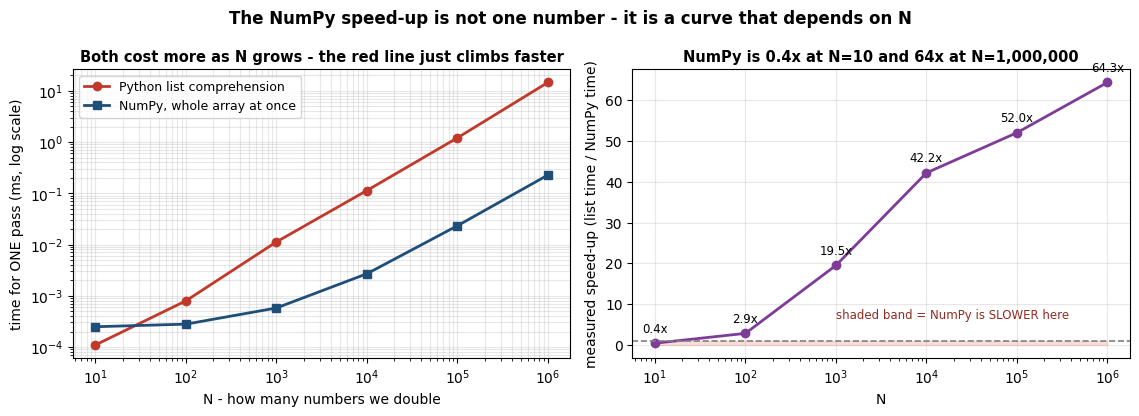

In [5]:
# FIGURE: the NumPy speed-up is not one number - it is a CURVE. Measure it, then draw it.
# WHAT this cell does: repeats the timing above at six array sizes (10 -> 1,000,000) and plots
#   both timings and their ratio, so the shape of the advantage is visible instead of asserted.
# WHY it is here: the paragraph above claims the win "only appears when the work is the SAME
#   operation repeated over many elements". That is a claim about a curve, so draw the curve.
import time
import numpy as np
import matplotlib.pyplot as plt


def best_of(operation, repeats, trials=3):
    """Run `operation` `repeats` times, `trials` times over, and keep the FASTEST average.

    WHY fastest and not mean: a slow run means the operating system interrupted us. The
    fastest run is the one least polluted by other work, so it is the fairest estimate of
    what the code itself costs. The warm-up call below pays the one-time memory page faults
    so they are not charged to the measurement.
    """
    operation()  # warm-up: not timed
    averages = []
    for _ in range(trials):
        start = time.perf_counter()
        for _ in range(repeats):
            operation()
        averages.append((time.perf_counter() - start) / repeats)
    return min(averages)


sizes = [10, 100, 1_000, 10_000, 100_000, 1_000_000]  # six sizes, one decade apart
list_ms, numpy_ms = [], []                            # milliseconds for one pass at each size

for n in sizes:
    py_list = list(range(n))   # the same n numbers ...
    np_array = np.arange(n)    # ... held two ways
    # Small sizes are too fast to time once, so repeat them more. Total work stays tiny.
    repeats = max(1, 100_000 // n)
    list_ms.append(best_of(lambda: [x * 2 for x in py_list], repeats) * 1000)
    numpy_ms.append(best_of(lambda: np_array * 2, repeats) * 1000)

speedup = [p / q for p, q in zip(list_ms, numpy_ms)]  # >1 means NumPy won, <1 means it lost

# Print the numbers first: the figure is a picture OF this table, not a replacement for it.
print(f"{'N':>10}  {'list (ms)':>11}  {'NumPy (ms)':>11}  {'speed-up':>9}")
print("-" * 48)
for n, p, q, s in zip(sizes, list_ms, numpy_ms, speedup):
    print(f"{n:>10,}  {p:>11.4f}  {q:>11.4f}  {s:>8.1f}x")
print()
print(f"Smallest N ({sizes[0]}):        NumPy is {'FASTER' if speedup[0] > 1 else 'SLOWER'} "
      f"({speedup[0]:.1f}x)")
print(f"Largest N ({sizes[-1]:,}): NumPy is {speedup[-1]:.0f}x faster")

fig, (ax_time, ax_ratio) = plt.subplots(1, 2, figsize=(11.5, 4.2))

# LEFT: absolute cost of one pass, log-log so six decades of N fit on one axis.
ax_time.loglog(sizes, list_ms, 'o-', color="#c0392b", lw=2, label="Python list comprehension")
ax_time.loglog(sizes, numpy_ms, 's-', color="#1f4e79", lw=2, label="NumPy, whole array at once")
ax_time.set_xlabel("N - how many numbers we double")
ax_time.set_ylabel("time for ONE pass (ms, log scale)")
ax_time.set_title("Both cost more as N grows - the red line just climbs faster",
                  fontsize=10.5, fontweight='bold')
ax_time.grid(alpha=.3, which='both')
ax_time.legend(fontsize=9)

# RIGHT: the ratio. The shaded band below 1x is the region where NumPy is the slower choice.
ax_ratio.semilogx(sizes, speedup, 'o-', color="#7d3c98", lw=2)
ax_ratio.axhline(1.0, color='gray', ls='--', lw=1.2)
ax_ratio.fill_between(sizes, 0, 1, color="#f5b7b1", alpha=.45)
ax_ratio.text(sizes[2], max(speedup) * 0.10, "shaded band = NumPy is SLOWER here",
              fontsize=8.5, color="#922b21")
ax_ratio.set_xlabel("N")
ax_ratio.set_ylabel("measured speed-up (list time / NumPy time)")
ax_ratio.set_title(f"NumPy is {speedup[0]:.1f}x at N={sizes[0]} and {speedup[-1]:.0f}x at "
                   f"N={sizes[-1]:,}", fontsize=10.5, fontweight='bold')
ax_ratio.grid(alpha=.3)
for x, y in zip(sizes, speedup):
    ax_ratio.annotate(f"{y:.1f}x", xy=(x, y), xytext=(0, 8), textcoords='offset points',
                      ha='center', fontsize=8.5)

fig.suptitle("The NumPy speed-up is not one number - it is a curve that depends on N",
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


### 🔎 Read the figure

**What to look for.** In the **left** panel the two lines start almost on top of each other on the far
left and pull apart as you move right: at N = 10 the red (list) line is at or *below* the blue (NumPy)
line, and by N = 1,000,000 blue sits well over a decade below red. In the **right** panel the same
story is one curve: it begins inside the pink band (below 1×, where NumPy is the *slower* choice) and
climbs steadily out of it, ending in the tens of ×. Read your own printed table for your machine's
numbers — the two lines the code prints under the table say which end won.

**What it proves.** The speed-up is not a property of NumPy; it is a property of NumPy *and how much
data you hand it*. A NumPy operation pays a fixed cost per call — checking types, choosing a compiled
loop, allocating the output array — and on ten numbers that fixed cost is the entire job, so a plain
list comprehension wins. Repeat the same operation over a million elements and the fixed cost is
amortised to nothing while the interpreter overhead of the list version is paid a million times.

**The lesson to carry forward.** "Vectorise it" is good advice for big arrays and can be *bad* advice
inside a tight loop over tiny ones. The curve, not the slogan, tells you which side of the line you
are on.

## Part 3: Matplotlib - Visualization

### 📚 What is Matplotlib?
Matplotlib = **Mat**hematical **Plot**ting **Lib**rary - creates beautiful graphs and charts!

**THE PROBLEM**: Numbers are hard to understand - we need visualizations!
**THE SOLUTION**: Matplotlib creates graphs - see your data visually!

**Why Matplotlib for AI?**
- AI works with data - visualizations help us understand data
- Need to see algorithm results (paths, distributions, optimizations)
- Need to compare models and results visually

✅ AFTER: Matplotlib Visualizations (See Your Data!)

📊 MOST FREQUENTLY USED MATPLOTLIB OPERATIONS:

   🔹 Line Plot (MOST COMMON!):
   ⏰ WHEN to use: Show trends over time, continuous data, function plots, algorithm performance
   💡 WHY use: Essential for visualizing data trends, algorithm behavior, model performance over epochs


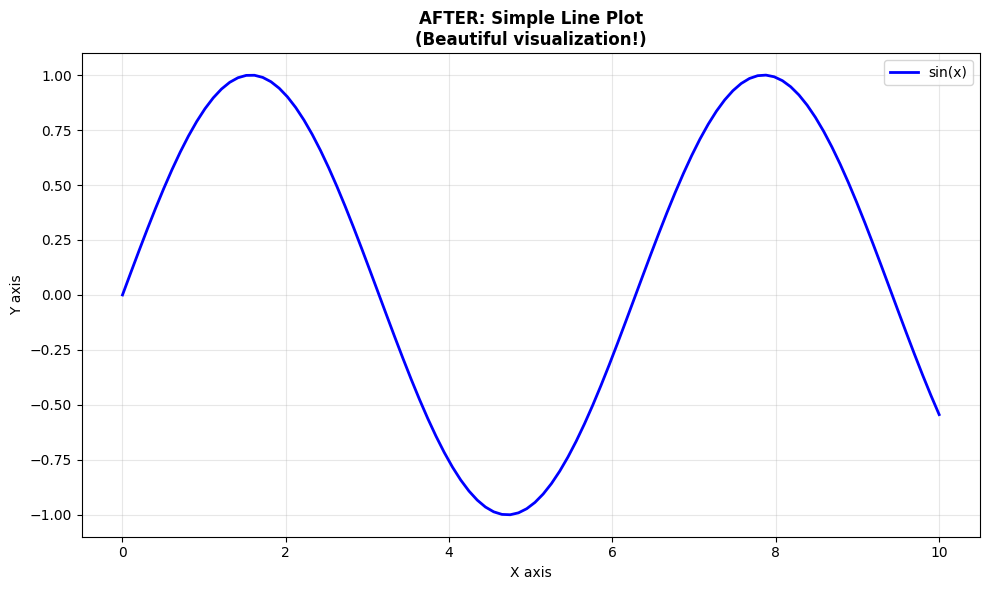

   ✅ Created line plot showing sin(x)
   📝 plt.show() is required - without it, plot won't display!

   🔹 Scatter Plot (VERY COMMON!):
   ⏰ WHEN to use: Show relationships between two variables, data points, correlations
   💡 WHY use: BEFORE ML - see if features are related, detect patterns in data, check for linear/non-linear relationships


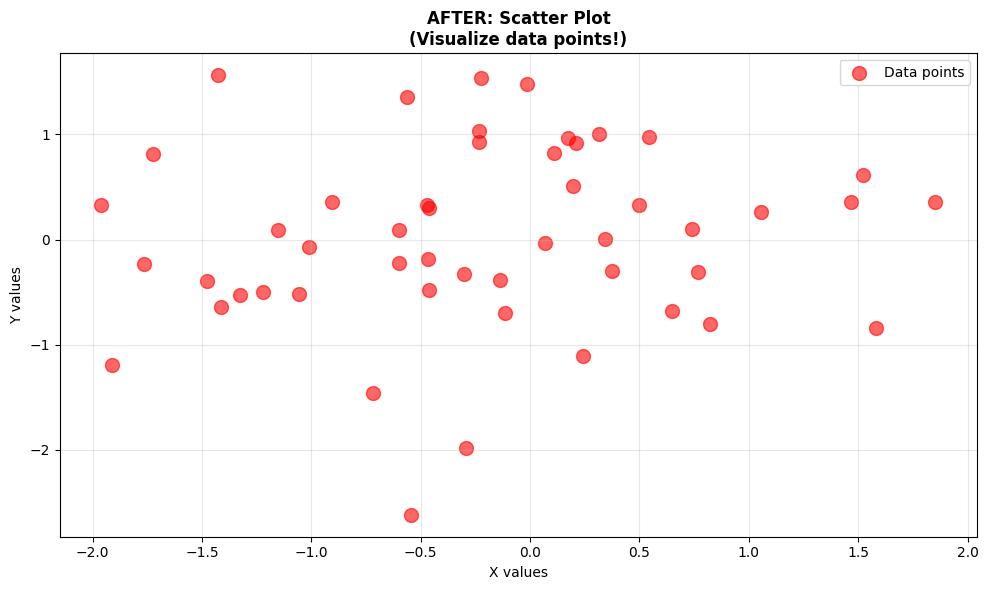

   ✅ Created scatter plot with 50 random points
   📝 Scatter plots show relationships - see if x and y are related!

   🔹 Multiple Plots / Subplots (COMMON for Comparison!):
   ⏰ WHEN to use: Compare multiple functions/plots side-by-side, show before/after comparisons
   💡 WHY use: Compare different algorithms, models, or data - see differences clearly!


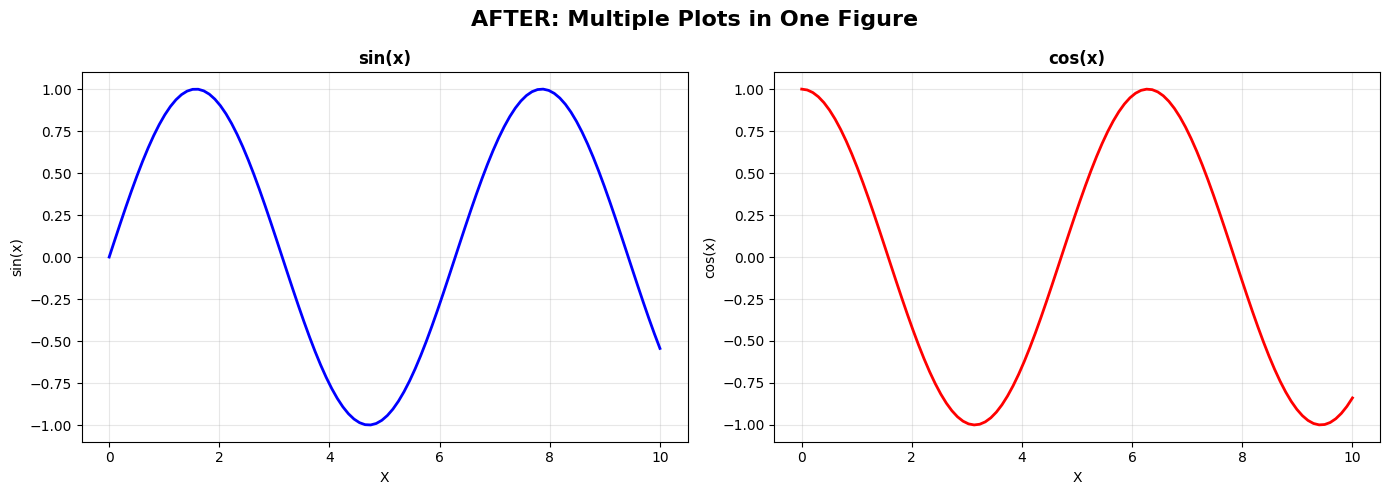

   ✅ Created 2 plots side-by-side
   📝 Subplots let you compare multiple things side-by-side!

   🔹 Histogram (VERY COMMON for Distributions!):
   ⏰ WHEN to use: Understand data distribution, check for normality, detect outliers, BEFORE ML training
   💡 WHY use: ML models assume certain distributions - check if data is normal/skewed before training!


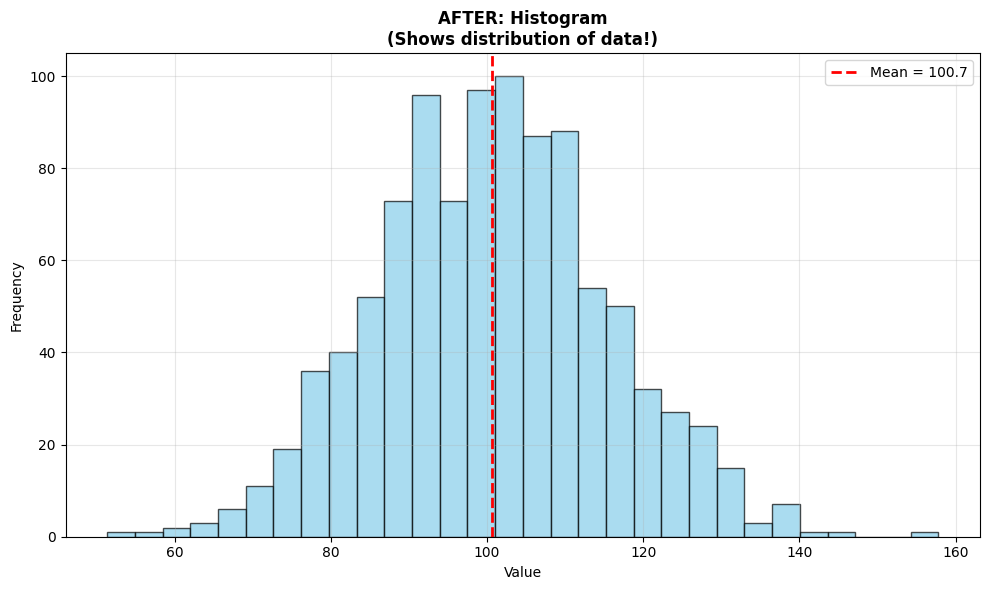

   ✅ Created histogram showing data distribution
   📝 Histograms show data distribution - essential before ML training!

🔗 HOW THIS HELPS IN AI:
   • Understand data: See patterns in data visually
   • Debug algorithms: Visualize algorithm behavior
   • Present results: Show findings to others

📊 BEFORE vs AFTER:
   BEFORE: Just numbers → Hard to understand patterns
   AFTER: Beautiful graphs → Easy to see what's happening!


In [6]:
# Matplotlib Basics: Creating Visualizations

import matplotlib.pyplot as plt  # Import Matplotlib (standard: use 'plt' as alias)
import numpy as np

print("=" * 70)
print("✅ AFTER: Matplotlib Visualizations (See Your Data!)")
print("=" * 70)
print()

# MOST FREQUENTLY USED MATPLOTLIB OPERATIONS (What AI Engineers Use!)
print("📊 MOST FREQUENTLY USED MATPLOTLIB OPERATIONS:")
print()

# 1. Line plot (MOST COMMON!)
print("   🔹 Line Plot (MOST COMMON!):")
print("   ⏰ WHEN to use: Show trends over time, continuous data, function plots, algorithm performance")
print("   💡 WHY use: Essential for visualizing data trends, algorithm behavior, model performance over epochs")
x = np.linspace(0, 10, 100)  # X values: Create 100 evenly spaced points from 0 to 10
y = np.sin(x)  # Y values: Calculate sine of each x value (mathematical function)

plt.figure(figsize=(10, 6))  # Create figure: Set size to 10 inches wide, 6 inches tall
plt.plot(x, y, 'b-', linewidth=2, label='sin(x)')  # Plot: 'b-' = blue line, linewidth=2 (thick), label for legend
plt.xlabel('X axis')  # Label x-axis: Horizontal axis label (X axis)
plt.ylabel('Y axis')  # Label y-axis: Vertical axis label (Y axis)
plt.title('AFTER: Simple Line Plot\n(Beautiful visualization!)', fontweight='bold')  # Title: Bold text
plt.legend()  # Show legend: Display labels (shows 'sin(x)')
plt.grid(True, alpha=0.3)  # Add grid: Light gray grid (alpha=0.3 = 30% opacity)
plt.tight_layout()  # Adjust spacing: Prevent labels from being cut off
plt.show()  # Display plot: Show the plot (MUST call this to see plot!)

print("   ✅ Created line plot showing sin(x)")
print("   📝 plt.show() is required - without it, plot won't display!")
print()

# 2. Scatter plot (VERY COMMON!)
print("   🔹 Scatter Plot (VERY COMMON!):")
print("   ⏰ WHEN to use: Show relationships between two variables, data points, correlations")
print("   💡 WHY use: BEFORE ML - see if features are related, detect patterns in data, check for linear/non-linear relationships")
# Generate random data points
np.random.seed(42)  # Set random seed: Makes results reproducible (same random numbers each time)
x_scatter = np.random.randn(50)  # 50 random x values: Normal distribution (mean=0, std=1)
y_scatter = np.random.randn(50)  # 50 random y values: Normal distribution (mean=0, std=1)

plt.figure(figsize=(10, 6))  # Create figure: 10x6 inches
plt.scatter(x_scatter, y_scatter, alpha=0.6, s=100, color='red', label='Data points')  # Scatter plot: alpha=transparency, s=size, color='red'
plt.xlabel('X values')  # X-axis label
plt.ylabel('Y values')  # Y-axis label
plt.title('AFTER: Scatter Plot\n(Visualize data points!)', fontweight='bold')  # Title
plt.legend()  # Show legend
plt.grid(True, alpha=0.3)  # Add grid
plt.tight_layout()  # Adjust spacing
plt.show()  # Display plot

print("   ✅ Created scatter plot with 50 random points")
print("   📝 Scatter plots show relationships - see if x and y are related!")
print()

# 3. Multiple plots (subplots) - COMMON for comparison!
print("   🔹 Multiple Plots / Subplots (COMMON for Comparison!):")
print("   ⏰ WHEN to use: Compare multiple functions/plots side-by-side, show before/after comparisons")
print("   💡 WHY use: Compare different algorithms, models, or data - see differences clearly!")
x = np.linspace(0, 10, 100)  # X values: Reuse same x values for both plots

fig, axes = plt.subplots(1, 2, figsize=(14, 5))  # 1 row, 2 columns: Create figure with 2 subplots side-by-side

# First subplot: sin(x)
axes[0].plot(x, np.sin(x), 'b-', linewidth=2)  # Plot on first subplot: Blue line, sine function
axes[0].set_xlabel('X')  # X-axis label for first subplot
axes[0].set_ylabel('sin(x)')  # Y-axis label for first subplot
axes[0].set_title('sin(x)', fontweight='bold')  # Title for first subplot
axes[0].grid(True, alpha=0.3)  # Add grid to first subplot

# Second subplot: cos(x)
axes[1].plot(x, np.cos(x), 'r-', linewidth=2)  # Plot on second subplot: Red line, cosine function
axes[1].set_xlabel('X')  # X-axis label for second subplot
axes[1].set_ylabel('cos(x)')  # Y-axis label for second subplot
axes[1].set_title('cos(x)', fontweight='bold')  # Title for second subplot
axes[1].grid(True, alpha=0.3)  # Add grid to second subplot

plt.suptitle('AFTER: Multiple Plots in One Figure', fontsize=16, fontweight='bold')  # Overall title: Above both subplots
plt.tight_layout()  # Adjust spacing: Prevent labels from overlapping
plt.show()  # Display plot

print("   ✅ Created 2 plots side-by-side")
print("   📝 Subplots let you compare multiple things side-by-side!")
print()

# 4. Histogram (VERY COMMON for distributions!)
print("   🔹 Histogram (VERY COMMON for Distributions!):")
print("   ⏰ WHEN to use: Understand data distribution, check for normality, detect outliers, BEFORE ML training")
print("   💡 WHY use: ML models assume certain distributions - check if data is normal/skewed before training!")
# Generate random data (normal distribution)
data = np.random.normal(100, 15, 1000)  # Mean=100, Std=15, 1000 points: Normal distribution

plt.figure(figsize=(10, 6))  # Create figure: 10x6 inches
plt.hist(data, bins=30, color='skyblue', alpha=0.7, edgecolor='black')  # Histogram: 30 bins, sky blue, semi-transparent, black edges
plt.axvline(np.mean(data), color='red', linestyle='--', linewidth=2, label=f'Mean = {np.mean(data):.1f}')  # Vertical line: Red dashed line at mean value
plt.xlabel('Value')  # X-axis label
plt.ylabel('Frequency')  # Y-axis label: How many times each value appears
plt.title('AFTER: Histogram\n(Shows distribution of data!)', fontweight='bold')  # Title
plt.legend()  # Show legend: Display mean line label
plt.grid(True, alpha=0.3)  # Add grid
plt.tight_layout()  # Adjust spacing
plt.show()  # Display plot

print("   ✅ Created histogram showing data distribution")
print("   📝 Histograms show data distribution - essential before ML training!")
print()

print("🔗 HOW THIS HELPS IN AI:")
print("   • Understand data: See patterns in data visually")
print("   • Debug algorithms: Visualize algorithm behavior")
print("   • Present results: Show findings to others")
print()
print("📊 BEFORE vs AFTER:")
print("   BEFORE: Just numbers → Hard to understand patterns")
print("   AFTER: Beautiful graphs → Easy to see what's happening!")


### 🔎 Read the four figures

These four are a *tour of the API*, not an argument about data — each one exists to show you the call that makes it. Still, look at what each shape is for:

- **Line plot** — `sin(x)` over 0 to 10: two peaks, one trough, and the curve still falling when the axis runs out — one and a half waves, not two. Use a line when the x axis has an order (time, epochs, depth). The two peaks sit at ≈1.6 and ≈7.9, one full period apart: ≈6.28 = 2π.
- **Scatter** — one dot per observation, no line joining them, because these points have no order. Use it when you want to see *where the points are*, not where they go next.
- **Two panels side by side** — `sin` and `cos` at the **same y scale**, which is the point: you may only compare two panels by eye if their axes match. `cos` starts at 1 where `sin` starts at 0 — the quarter-period shift is visible precisely because the scales agree.
- **Histogram** — 1,000 draws from a normal distribution with mean 100. The bars form one symmetric hump and the dashed line marks the measured mean at ≈100.7, not the 100 that was asked for. That small gap is sampling error, and it is worth noticing: a sample never lands exactly on the distribution it came from.

Randomness is deliberate in the last two — they are demonstrating what a *sample* looks like. Everywhere else in this course the plots are drawn from real measurements.

In [7]:
# 📚 QUICK REFERENCE: Matplotlib Most Commonly Used Functions
# Complete cheat sheet of functions you'll use in AI projects

# HOW TO USE THIS CELL: it computes nothing new - it prints a cheat sheet you can re-open while coding, so you never have to memorize function names.

import matplotlib.pyplot as plt
import numpy as np

print("=" * 70)
print("📚 MATPLOTLIB FUNCTION REFERENCE - Most Commonly Used Functions")
print("=" * 70)
print()

print("🔹 FIGURE & PLOT CREATION:")
print("   plt.figure(figsize=(10, 6))            # Create new figure (10x6 inches)")
print("   plt.plot(x, y)                         # Line plot (most common!)")
print("   plt.scatter(x, y)                      # Scatter plot")
print("   plt.bar(x, y)                          # Bar chart")
print("   plt.hist(data, bins=20)                # Histogram")
print("   plt.boxplot(data)                      # Box plot")
print("   plt.pie(sizes, labels=labels)          # Pie chart")
print()

print("🔹 PLOT CUSTOMIZATION:")
print("   plt.xlabel('X Label')                  # X-axis label")
print("   plt.ylabel('Y Label')                  # Y-axis label")
print("   plt.title('Title')                     # Plot title")
print("   plt.legend()                           # Show legend")
print("   plt.grid(True)                         # Show grid")
print("   plt.xlim(0, 10)                        # X-axis limits")
print("   plt.ylim(0, 100)                       # Y-axis limits")
print("   plt.xticks([0, 5, 10])                 # Set x-axis ticks")
print("   plt.yticks([0, 50, 100])               # Set y-axis ticks")
print()

print("🔹 LINE PLOT OPTIONS:")
print("   plt.plot(x, y, 'b-')                   # Blue solid line")
print("   plt.plot(x, y, 'r--')                  # Red dashed line")
print("   plt.plot(x, y, 'g:')                   # Green dotted line")
print("   plt.plot(x, y, 'o')                    # Circles (no line)")
print("   plt.plot(x, y, linewidth=2)            # Line width")
print("   plt.plot(x, y, label='Data')           # Label for legend")
print("   plt.plot(x, y, color='red')            # Color name")
print("   plt.plot(x, y, alpha=0.5)              # Transparency (0-1)")
print()

print("🔹 SCATTER PLOT OPTIONS:")
print("   plt.scatter(x, y, s=100)               # Size of points")
print("   plt.scatter(x, y, c='red')             # Color")
print("   plt.scatter(x, y, alpha=0.6)           # Transparency")
print("   plt.scatter(x, y, marker='o')          # Marker style")
print("   plt.scatter(x, y, cmap='viridis')      # Color map")
print()

print("🔹 MULTIPLE PLOTS (Subplots):")
print("   fig, axes = plt.subplots(2, 2)         # 2x2 grid of subplots")
print("   axes[0, 0].plot(x, y)                  # Plot on first subplot")
print("   axes[0, 1].scatter(x, y)               # Plot on second subplot")
print("   plt.subplot(2, 2, 1)                   # Select subplot (old style)")
print("   plt.tight_layout()                     # Adjust spacing")
print()

print("🔹 SAVING & DISPLAYING:")
print("   plt.show()                             # Display plot (REQUIRED!)")
print("   plt.savefig('plot.png')                # Save to file")
print("   plt.savefig('plot.pdf')                # Save as PDF")
print("   plt.savefig('plot.png', dpi=300)       # High resolution")
print("   plt.close()                            # Close figure")
print()

print("🔹 ADVANCED PLOTTING:")
print("   plt.fill_between(x, y1, y2)            # Fill area between lines")
print("   plt.axhline(y=0)                       # Horizontal line")
print("   plt.axvline(x=0)                       # Vertical line")
print("   plt.text(x, y, 'text')                 # Add text")
print("   plt.annotate('note', xy=(x, y))        # Annotate point")
print()

print("💡 TIP: Always call plt.show() to display your plot!")
print("💡 TIP: Use plt.figure() before each new plot to avoid overlapping")
print("💡 TIP: Use plt.subplots() for multiple plots side-by-side")


📚 MATPLOTLIB FUNCTION REFERENCE - Most Commonly Used Functions

🔹 FIGURE & PLOT CREATION:
   plt.figure(figsize=(10, 6))            # Create new figure (10x6 inches)
   plt.plot(x, y)                         # Line plot (most common!)
   plt.scatter(x, y)                      # Scatter plot
   plt.bar(x, y)                          # Bar chart
   plt.hist(data, bins=20)                # Histogram
   plt.boxplot(data)                      # Box plot
   plt.pie(sizes, labels=labels)          # Pie chart

🔹 PLOT CUSTOMIZATION:
   plt.xlabel('X Label')                  # X-axis label
   plt.ylabel('Y Label')                  # Y-axis label
   plt.title('Title')                     # Plot title
   plt.legend()                           # Show legend
   plt.grid(True)                         # Show grid
   plt.xlim(0, 10)                        # X-axis limits
   plt.ylim(0, 100)                       # Y-axis limits
   plt.xticks([0, 5, 10])                 # Set x-axis ticks
   plt.yticks(

## Part 4: Collections & heapq - Efficient Data Structures

### 📚 What are Collections and heapq?
These are Python built-in modules for efficient data structures!

**THE PROBLEM**: Python lists are slow for some operations (queues, priority queues).
**THE SOLUTION**: Collections.deque and heapq provide fast, specialized data structures!

**Why Collections/heapq for AI?**
- Search algorithms need queues (BFS) and priority queues (A*)
- These structures are FAST - optimized for specific operations
- Essential for efficient algorithm implementation

In [8]:
# Collections and heapq: Efficient Data Structures

from collections import deque  # Fast queue/stack
import heapq  # Priority queue

print("=" * 70)
print("✅ AFTER: Collections & heapq (Efficient Data Structures)")
print("=" * 70)
print()

# MOST FREQUENTLY USED COLLECTIONS/HEAPQ OPERATIONS (What AI Engineers Use!)
print("📊 MOST FREQUENTLY USED COLLECTIONS/HEAPQ OPERATIONS:")
print()

# 1. collections.deque - Fast Queue (MOST COMMON for BFS!)
print("   🔹 collections.deque (MOST COMMON for BFS!):")
print("   ⏰ WHEN to use: BFS algorithm needs a queue - deque is fastest!")
print("   💡 WHY use: Deque is O(1) for queue operations - Python list would be O(n) (slow!)")

# Deque = "double-ended queue" - can add/remove from both ends FAST!
queue = deque()  # Create empty queue: Double-ended queue (can add/remove from both ends)

# Add items to end (like standing in line)
queue.append('first')   # Add to end: Append item to right end (back of queue)
queue.append('second')  # Add to end: Append another item
queue.append('third')   # Add to end: Append another item

print(f"   # Add to end: queue.append('item')  (adds to right end)")
print(f"   Queue after adding items: {list(queue)}")
print()

# Remove from front (like serving first person in line)
first_item = queue.popleft()  # Remove from left (front): Pop item from left end (FIFO - First In First Out)
print(f"   # Remove from front: queue.popleft()  (removes from left end - FIFO!)")
print(f"   Removed from front: '{first_item}'")
print(f"   Queue after removing: {list(queue)}")
print()

# Can also add/remove from either end
queue.appendleft('new_first')  # Add to front: Prepend item to left end (front of queue)
print(f"   # Add to front: queue.appendleft('item')  (adds to left end)")
print(f"   After adding to front: {list(queue)}")

last_item = queue.pop()  # Remove from end: Pop item from right end (like stack)
print(f"   # Remove from end: queue.pop()  (removes from right end)")
print(f"   Removed from end: '{last_item}'")
print(f"   Final queue: {list(queue)}")
print()

print("   ✅ Deque is FAST: O(1) for add/remove from both ends!")
print("   ✅ Python list would be SLOW: O(n) for operations at front")
print("   📝 BFS uses deque() - always use deque for queues in AI algorithms!")
print()

# 2. heapq - Priority Queue (VERY COMMON for A*!)
print("   🔹 heapq (VERY COMMON for A* Algorithm!):")
print("   ⏰ WHEN to use: A* algorithm needs priority queue - always explore most promising node first!")
print("   💡 WHY use: heapq maintains priority order automatically - always get smallest item first!")

# Priority queue: Always get smallest (or largest) item first
# Used in A* algorithm: always explore most promising node first!
heap = []  # Python list works as heap: heapq modifies list in-place to maintain heap structure

# Add items with priority
heapq.heappush(heap, 5)   # Add item with priority 5: Push item into heap (maintains order)
heapq.heappush(heap, 2)   # Add item with priority 2: Push item (will come before 5!)
heapq.heappush(heap, 8)   # Add item with priority 8: Push item
heapq.heappush(heap, 1)   # Add item with priority 1: Push item (will come first!)

print(f"   # Add to heap: heapq.heappush(heap, priority)  (maintains priority order)")
print(f"   Heap after adding [5, 2, 8, 1]: {heap}")
print("   📝 Heap structure: Smallest always at index 0 (ready to pop)")
print()

# Get smallest item (highest priority)
smallest = heapq.heappop(heap)  # Get smallest: Pop and return smallest item (index 0)
print(f"   # Get smallest: heapq.heappop(heap)  (removes and returns smallest)")
print(f"   Popped smallest: {smallest}  (priority 1 - highest priority!)")
print(f"   Heap after popping: {heap}")

smallest = heapq.heappop(heap)  # Get next smallest: Pop next smallest item
print(f"   Popped smallest: {smallest}  (priority 2 - next highest!)")
print(f"   Heap after popping: {heap}")
print()

print("   ✅ heapq automatically maintains priority order!")
print("   ✅ Always get smallest item first (perfect for A* algorithm!)")
print("   📝 A* uses heapq - always explore most promising node first (shortest estimated path)!")
print()

# 3. Real AI Example: Using in search algorithms
print("📊 Step 3: Real AI Example - How Algorithms Use These")
print()

print("   BFS (Breadth-First Search) uses deque:")
print("   • queue.append(node)  # Add to back")
print("   • node = queue.popleft()  # Get from front")
print("   → Explores level by level (first in, first out)")
print()

print("   A* Search uses heapq:")
print("   • heapq.heappush(open_set, (priority, node))  # Add with priority")
print("   • _, node = heapq.heappop(open_set)  # Get highest priority")
print("   → Always explores most promising node first!")
print()

print("🔗 HOW THIS HELPS IN AI:")
print("   • Fast algorithms: Deque and heapq are optimized for speed")
print("   • Efficient search: Essential for BFS, DFS, A* algorithms")
print("   • Priority handling: heapq automatically sorts by priority")
print()
print("📊 BEFORE vs AFTER:")
print("   BEFORE: Python lists → Slow for queues, no priority queue")
print("   AFTER: collections.deque + heapq → Fast, efficient, powerful!")


✅ AFTER: Collections & heapq (Efficient Data Structures)

📊 MOST FREQUENTLY USED COLLECTIONS/HEAPQ OPERATIONS:

   🔹 collections.deque (MOST COMMON for BFS!):
   ⏰ WHEN to use: BFS algorithm needs a queue - deque is fastest!
   💡 WHY use: Deque is O(1) for queue operations - Python list would be O(n) (slow!)
   # Add to end: queue.append('item')  (adds to right end)
   Queue after adding items: ['first', 'second', 'third']

   # Remove from front: queue.popleft()  (removes from left end - FIFO!)
   Removed from front: 'first'
   Queue after removing: ['second', 'third']

   # Add to front: queue.appendleft('item')  (adds to left end)
   After adding to front: ['new_first', 'second', 'third']
   # Remove from end: queue.pop()  (removes from right end)
   Removed from end: 'third'
   Final queue: ['new_first', 'second']

   ✅ Deque is FAST: O(1) for add/remove from both ends!
   ✅ Python list would be SLOW: O(n) for operations at front
   📝 BFS uses deque() - always use deque for queues 

 queue size    list.pop(0)   deque.popleft()   list costs
------------------------------------------------------------
      1,000       0.0678 us          0.0244 us           3x
      2,000       0.0978 us          0.0246 us           4x
      4,000       0.1593 us          0.0295 us           5x
      8,000       0.2921 us          0.0242 us          12x
     16,000       0.5942 us          0.0244 us          24x
     32,000       1.6026 us          0.0244 us          66x


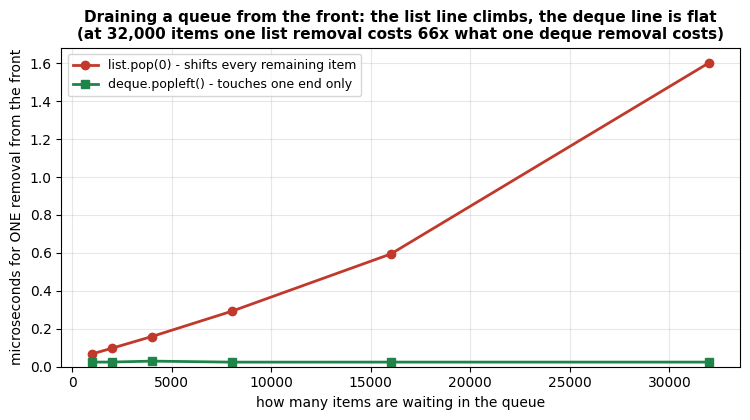

In [9]:
# FIGURE: check the "deque is O(1), list is O(n)" claim printed above by measuring it.
# WHAT this cell does: drains a queue from the FRONT, once with a Python list (list.pop(0)) and
#   once with a deque (deque.popleft()), at six queue sizes, and plots the cost of ONE removal.
# WHY it is here: BFS in the very next notebook pops from the front of its queue on every single
#   step. If that one operation quietly costs O(n), the whole search silently becomes quadratic.
import time
from collections import deque
import matplotlib.pyplot as plt

queue_sizes = [1_000, 2_000, 4_000, 8_000, 16_000, 32_000]
list_us, deque_us = [], []  # microseconds per single removal

for n in queue_sizes:
    # A plain list used as a queue: pop(0) must shift every remaining element left by one slot.
    as_list = list(range(n))
    start = time.perf_counter()
    while as_list:
        as_list.pop(0)
    list_us.append((time.perf_counter() - start) / n * 1e6)

    # A deque: popleft() unlinks one end of a doubly-linked block list - nothing else moves.
    as_deque = deque(range(n))
    start = time.perf_counter()
    while as_deque:
        as_deque.popleft()
    deque_us.append((time.perf_counter() - start) / n * 1e6)

print(f"{'queue size':>11}  {'list.pop(0)':>13}  {'deque.popleft()':>16}  {'list costs':>11}")
print("-" * 60)
for n, a, b in zip(queue_sizes, list_us, deque_us):
    print(f"{n:>11,}  {a:>11.4f} us  {b:>14.4f} us  {a / b:>10.0f}x")

fig, ax = plt.subplots(figsize=(7.6, 4.3))
ax.plot(queue_sizes, list_us, 'o-', color="#c0392b", lw=2,
        label="list.pop(0) - shifts every remaining item")
ax.plot(queue_sizes, deque_us, 's-', color="#1e8449", lw=2,
        label="deque.popleft() - touches one end only")
ax.set_xlabel("how many items are waiting in the queue")
ax.set_ylabel("microseconds for ONE removal from the front")
ax.set_title("Draining a queue from the front: the list line climbs, the deque line is flat\n"
             f"(at {queue_sizes[-1]:,} items one list removal costs {list_us[-1] / deque_us[-1]:.0f}x "
             f"what one deque removal costs)", fontsize=11, fontweight='bold')
ax.grid(alpha=.3)
ax.legend(fontsize=9)
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()


### 🔎 Read the figure

**What to look for.** The green `deque.popleft()` line runs flat along the bottom — the cost of one
removal is the same whether 1,000 or 32,000 items are waiting. The red `list.pop(0)` line rises in a
straight line: double the queue and you double the cost of every single removal. The two lines are
close at the left edge and far apart at the right, and the title reports the measured gap at the
largest size.

**What it proves.** "O(1) versus O(n)" is not a slogan you take on faith — it is the *shape of those
two lines*. Flat means the cost does not depend on how much is in the container. Rising means it does,
because `list.pop(0)` physically shifts every remaining element one slot to the left.

**Why this matters for the next notebook.** BFS removes from the front of its queue once per node
expanded. Multiply a per-removal cost that itself grows with the queue by a queue that grows with the
search, and an O(V+E) algorithm quietly becomes quadratic. This is exactly why the BFS code in the
next notebook opens with `from collections import deque` — that import is a correctness-of-complexity
decision, not a style preference.

In [10]:
# 📚 QUICK REFERENCE: Collections & heapq Most Commonly Used Functions
# Complete cheat sheet of functions you'll use in AI projects

# HOW TO USE THIS CELL: it computes nothing new - it prints a cheat sheet you can re-open while coding, so you never have to memorize function names.

from collections import deque
import heapq

print("=" * 70)
print("📚 COLLECTIONS & HEAPQ FUNCTION REFERENCE - Most Commonly Used Functions")
print("=" * 70)
print()

print("🔹 collections.deque (Fast Queue - MOST COMMON for BFS!):")
print("   queue = deque()                        # Create empty queue")
print("   queue = deque([1, 2, 3])              # Create from list")
print("   queue.append(item)                     # Add to right end (back)")
print("   queue.appendleft(item)                 # Add to left end (front)")
print("   item = queue.pop()                     # Remove from right end")
print("   item = queue.popleft()                 # Remove from left end (FIFO)")
print("   queue[0]                               # First item (without removing)")
print("   queue[-1]                              # Last item (without removing)")
print("   len(queue)                             # Number of items")
print("   list(queue)                            # Convert to list")
print("   queue.clear()                          # Remove all items")
print()

print("🔹 heapq (Priority Queue - MOST COMMON for A*!):")
print("   heap = []                              # Create empty heap (use list!)")
print("   heapq.heappush(heap, item)             # Add item (maintains order)")
print("   heapq.heappush(heap, (priority, item)) # Add with priority tuple")
print("   item = heapq.heappop(heap)             # Remove smallest item")
print("   smallest = heap[0]                     # Peek smallest (don't remove)")
print("   heapq.heapify(list)                    # Convert list to heap")
print("   heapq.heappushpop(heap, item)          # Push then pop (efficient)")
print("   item = heapq.heapreplace(heap, item)   # Pop then push (efficient)")
print("   heapq.nlargest(n, heap)                # N largest items")
print("   heapq.nsmallest(n, heap)               # N smallest items")
print()

print("🔹 Common Patterns:")
print("   # BFS Queue Pattern:")
print("   queue = deque([start])")
print("   while queue:")
print("       node = queue.popleft()  # FIFO")
print("       # process node")
print()
print("   # A* Priority Queue Pattern:")
print("   heap = [(0, start, [start])]  # (priority, node, path)")
print("   while heap:")
print("       priority, node, path = heapq.heappop(heap)  # Smallest first")
print("       # process node")
print()

print("💡 TIP: deque is O(1) for append/pop from both ends - much faster than list!")
print("💡 TIP: heapq always keeps smallest item at index 0")
print("💡 TIP: Use tuple (priority, item) for priority queues - heapq sorts by first element")


📚 COLLECTIONS & HEAPQ FUNCTION REFERENCE - Most Commonly Used Functions

🔹 collections.deque (Fast Queue - MOST COMMON for BFS!):
   queue = deque()                        # Create empty queue
   queue = deque([1, 2, 3])              # Create from list
   queue.append(item)                     # Add to right end (back)
   queue.appendleft(item)                 # Add to left end (front)
   item = queue.pop()                     # Remove from right end
   item = queue.popleft()                 # Remove from left end (FIFO)
   queue[0]                               # First item (without removing)
   queue[-1]                              # Last item (without removing)
   len(queue)                             # Number of items
   list(queue)                            # Convert to list
   queue.clear()                          # Remove all items

🔹 heapq (Priority Queue - MOST COMMON for A*!):
   heap = []                              # Create empty heap (use list!)
   heapq.heappush(heap

## Part 5: NetworkX - Graph Operations

### 📚 What is NetworkX?
NetworkX = Library for creating, manipulating, and studying graphs/networks!

**THE PROBLEM**: Representing graphs with lists/dicts is complicated.
**THE SOLUTION**: NetworkX makes graphs easy - simple API for complex operations!

**Why NetworkX for AI?**
- Knowledge graphs need graph operations
- Search algorithms work on graphs
- NetworkX provides visualization, pathfinding, analysis - all built-in!

✅ AFTER: NetworkX (Easy Graph Operations)

📊 MOST FREQUENTLY USED NETWORKX OPERATIONS:

   🔹 Creating Graph (MOST COMMON!):
   ⏰ WHEN to use: Knowledge graphs, search algorithms, network analysis
   💡 WHY use: NetworkX makes graphs easy - simple API for complex graph operations!
   # Create graph: G = nx.Graph()  (undirected graph)
   # Add nodes: G.add_node('A'), G.add_node('B'), etc.
   # Add edges: G.add_edge('A', 'B')  (connect A to B)
   Nodes: ['A', 'B', 'C', 'D']  (entities in graph)
   Edges: [('A', 'B'), ('A', 'D'), ('B', 'C'), ('C', 'D')]  (relationships between nodes)
   Number of nodes: 4  (how many entities)
   Number of edges: 4  (how many relationships)

   🔹 Visualizing Graph (COMMON!):
   ⏰ WHEN to use: See graph structure, debug algorithms, present results
   💡 WHY use: Visual understanding helps debug - see if graph structure is correct!


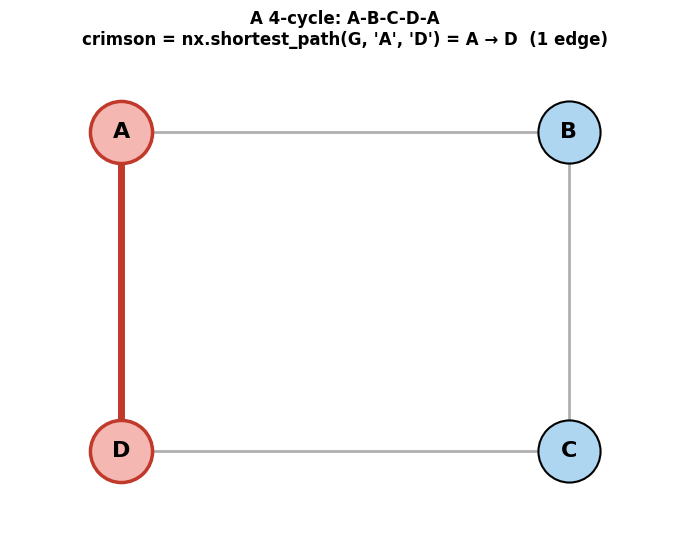

   ✅ Created beautiful graph visualization!
   📝 NetworkX + Matplotlib = easy graph visualization!

   🔹 Graph Operations (VERY COMMON for Search Algorithms!):
   ⏰ WHEN to use: Find paths, check connectivity, analyze graph structure
   💡 WHY use: Search algorithms need these operations - NetworkX provides them ready-made!
   # Shortest path: nx.shortest_path(G, 'A', 'D')  (finds shortest path)
   Shortest path from A to D: ['A', 'D']  (sequence of nodes)
   # Neighbors: list(G.neighbors('B'))  (nodes connected to B)
   Neighbors of B: ['A', 'C']  (nodes directly connected to B)
   # Check path: nx.has_path(G, 'A', 'C')  (returns True if path exists)
   Path exists from A to C: True  (True = path exists, False = no path)

   ✅ NetworkX provides powerful graph operations built-in!
   ✅ Pathfinding, analysis, algorithms - all ready to use!
   📝 BFS/DFS can use nx.shortest_path() - but we'll implement them manually to learn!

🔗 HOW THIS HELPS IN AI:
   • Knowledge graphs: Represent relati

In [11]:
# NetworkX: Working with Graphs

try:
    import networkx as nx  # Import NetworkX (standard: use 'nx' as alias)
    import matplotlib.pyplot as plt
    HAS_NETWORKX = True
except ImportError:
    HAS_NETWORKX = False
    print("⚠️  NetworkX not installed. Install with: pip install networkx matplotlib")

if HAS_NETWORKX:
    print("=" * 70)
    print("✅ AFTER: NetworkX (Easy Graph Operations)")
    print("=" * 70)
    print()
    
    # MOST FREQUENTLY USED NETWORKX OPERATIONS (What AI Engineers Use!)
    print("📊 MOST FREQUENTLY USED NETWORKX OPERATIONS:")
    print()
    
    # 1. Creating a graph (MOST COMMON!)
    print("   🔹 Creating Graph (MOST COMMON!):")
    print("   ⏰ WHEN to use: Knowledge graphs, search algorithms, network analysis")
    print("   💡 WHY use: NetworkX makes graphs easy - simple API for complex graph operations!")
    
    G = nx.Graph()  # Create empty undirected graph: Graph with no direction (A-B same as B-A)
    # Can also use: nx.DiGraph() for directed graph (A->B different from B->A)
    
    # Add nodes (entities)
    G.add_node('A')  # Add node 'A': Add entity to graph
    G.add_node('B')  # Add node 'B': Add another entity
    G.add_node('C')  # Add node 'C': Add another entity
    G.add_node('D')  # Add node 'D': Add another entity
    
    # Add edges (relationships)
    G.add_edge('A', 'B')  # A is connected to B: Add relationship between nodes
    G.add_edge('B', 'C')  # B is connected to C: Add another relationship
    G.add_edge('C', 'D')  # C is connected to D: Add another relationship
    G.add_edge('A', 'D')  # A is connected to D: Add direct connection (shortcut)
    
    print(f"   # Create graph: G = nx.Graph()  (undirected graph)")
    print(f"   # Add nodes: G.add_node('A'), G.add_node('B'), etc.")
    print(f"   # Add edges: G.add_edge('A', 'B')  (connect A to B)")
    print(f"   Nodes: {list(G.nodes())}  (entities in graph)")
    print(f"   Edges: {list(G.edges())}  (relationships between nodes)")
    print(f"   Number of nodes: {G.number_of_nodes()}  (how many entities)")
    print(f"   Number of edges: {G.number_of_edges()}  (how many relationships)")
    print()
    
    # 2. Visualize the graph (COMMON!)
    print("   🔹 Visualizing Graph (COMMON!):")
    print("   ⏰ WHEN to use: See graph structure, debug algorithms, present results")
    print("   💡 WHY use: Visual understanding helps debug - see if graph structure is correct!")
    
    # A FIXED layout, not spring_layout: spring_layout re-randomises every run, so the same
    # graph came out a different shape each time and edges crossed for no reason. Pinning the
    # four corners of the square makes the structure - a 4-cycle - readable at a glance.
    pos = {'A': (0, 1), 'B': (1, 1), 'C': (1, 0), 'D': (0, 0)}

    # Draw the shortest path this cell computes a few lines below, IN the picture. A graph
    # drawing that shows no result is decoration; one that shows the answer is evidence.
    highlight = nx.shortest_path(G, 'A', 'D')  # ['A', 'D'] - the direct edge, not the long way
    highlight_edges = [(highlight[k], highlight[k + 1]) for k in range(len(highlight) - 1)]
    other_edges = [e for e in G.edges() if e not in highlight_edges
                   and tuple(reversed(e)) not in highlight_edges]

    plt.figure(figsize=(7, 5.5))  # Create figure: 7 inches wide, 5.5 inches tall
    nx.draw_networkx_edges(G, pos, edgelist=other_edges, edge_color='#b0b0b0', width=2)
    nx.draw_networkx_edges(G, pos, edgelist=highlight_edges, edge_color='#c0392b', width=5)
    nx.draw_networkx_nodes(G, pos, node_color='#aed6f1', node_size=2000,
                           edgecolors='black', linewidths=1.5)
    nx.draw_networkx_nodes(G, pos, nodelist=highlight, node_color='#f5b7b1', node_size=2000,
                           edgecolors='#c0392b', linewidths=2.5)
    nx.draw_networkx_labels(G, pos, font_size=16, font_weight='bold')
    plt.title("A 4-cycle: A-B-C-D-A\n"
              "crimson = nx.shortest_path(G, 'A', 'D') = "
              + " → ".join(highlight) + f"  ({len(highlight) - 1} edge)",
              fontsize=12, fontweight='bold')
    plt.axis('off')
    plt.margins(0.18)
    plt.tight_layout()  # Adjust spacing: Prevent labels from being cut off
    plt.show()  # Display plot: Show the graph visualization
    
    print("   ✅ Created beautiful graph visualization!")
    print("   📝 NetworkX + Matplotlib = easy graph visualization!")
    print()
    
    # 3. Graph operations (VERY COMMON for search algorithms!)
    print("   🔹 Graph Operations (VERY COMMON for Search Algorithms!):")
    print("   ⏰ WHEN to use: Find paths, check connectivity, analyze graph structure")
    print("   💡 WHY use: Search algorithms need these operations - NetworkX provides them ready-made!")
    
    # Find path between nodes
    path = nx.shortest_path(G, 'A', 'D')  # Find shortest path: From node A to node D
    print(f"   # Shortest path: nx.shortest_path(G, 'A', 'D')  (finds shortest path)")
    print(f"   Shortest path from A to D: {path}  (sequence of nodes)")
    
    # Find all neighbors
    neighbors = list(G.neighbors('B'))  # Get neighbors: All nodes connected to node B
    print(f"   # Neighbors: list(G.neighbors('B'))  (nodes connected to B)")
    print(f"   Neighbors of B: {neighbors}  (nodes directly connected to B)")
    
    # Check if path exists
    has_path = nx.has_path(G, 'A', 'C')  # Check connectivity: Is there a path from A to C?
    print(f"   # Check path: nx.has_path(G, 'A', 'C')  (returns True if path exists)")
    print(f"   Path exists from A to C: {has_path}  (True = path exists, False = no path)")
    print()
    
    print("   ✅ NetworkX provides powerful graph operations built-in!")
    print("   ✅ Pathfinding, analysis, algorithms - all ready to use!")
    print("   📝 BFS/DFS can use nx.shortest_path() - but we'll implement them manually to learn!")
    print()
    
    print("🔗 HOW THIS HELPS IN AI:")
    print("   • Knowledge graphs: Represent relationships between entities")
    print("   • Search algorithms: Find paths efficiently")
    print("   • Network analysis: Understand connections and patterns")
    print()
    print("📊 BEFORE vs AFTER:")
    print("   BEFORE: Lists/dicts for graphs → Complicated, error-prone")
    print("   AFTER: NetworkX → Simple API, powerful operations, built-in visualization!")
else:
    print("⚠️  Please install NetworkX to see graph examples")
    print("   Run: pip install networkx matplotlib")


### 🔎 Read the figure

**What to look for.** Four nodes wired into a square: `A–B`, `B–C`, `C–D`, and the shortcut `A–D`. The crimson edge is not decoration — it is the value `nx.shortest_path(G, 'A', 'D')` returned, drawn onto the graph. It picks the single `A–D` edge, one hop, rather than the three-hop way round through `B` and `C`.

**What it proves.** NetworkX already contains the search you are about to spend the next lesson writing by hand. That is deliberate: in the next notebook you implement BFS, DFS and A\* yourself so you know what `shortest_path` is doing, and after that you are free to call the library. Knowing the answer NetworkX gives is also how you check your own implementation — if your BFS disagrees with `nx.shortest_path`, your BFS is wrong.

**A caution about the picture.** The layout here is pinned by hand. `nx.spring_layout` — the default — is randomised, so the same graph comes out a different shape on every run. That is fine for exploring and terrible for a slide or a report, where two runs of the same code should produce the same image. Pass a fixed `pos`, or `spring_layout(G, seed=0)`.

In [12]:
# 📚 QUICK REFERENCE: NetworkX Most Commonly Used Functions
# Complete cheat sheet of functions you'll use in AI projects

# HOW TO USE THIS CELL: it computes nothing new - it prints a cheat sheet you can re-open while coding, so you never have to memorize function names.

import networkx as nx

print("=" * 70)
print("📚 NETWORKX FUNCTION REFERENCE - Most Commonly Used Functions")
print("=" * 70)
print()

print("🔹 GRAPH CREATION:")
print("   G = nx.Graph()                         # Undirected graph")
print("   G = nx.DiGraph()                       # Directed graph")
print("   G.add_node('A')                        # Add single node")
print("   G.add_nodes_from(['A', 'B', 'C'])     # Add multiple nodes")
print("   G.add_edge('A', 'B')                   # Add edge (A-B)")
print("   G.add_edges_from([('A','B'), ('B','C')])  # Add multiple edges")
print("   G.add_weighted_edges_from([('A','B', 5)])  # Add weighted edge")
print()

print("🔹 GRAPH PROPERTIES:")
print("   G.nodes()                              # All nodes")
print("   G.edges()                              # All edges")
print("   G.number_of_nodes()                    # Count nodes")
print("   G.number_of_edges()                    # Count edges")
print("   list(G.neighbors('A'))                 # Neighbors of node A")
print("   G.degree('A')                          # Degree (connections) of node")
print("   'A' in G                               # Check if node exists")
print()

print("🔹 PATHFINDING (VERY COMMON for Search Algorithms!):")
print("   nx.shortest_path(G, 'A', 'D')          # Shortest path from A to D")
print("   nx.shortest_path_length(G, 'A', 'D')   # Length of shortest path")
print("   nx.has_path(G, 'A', 'D')               # Check if path exists")
print("   nx.all_shortest_paths(G, 'A', 'D')     # All shortest paths")
print("   nx.dijkstra_path(G, 'A', 'D')          # Dijkstra's shortest path")
print("   nx.dijkstra_path_length(G, 'A', 'D')   # Dijkstra's path length")
print()

print("🔹 GRAPH ALGORITHMS:")
print("   list(nx.dfs_edges(G, 'A'))             # DFS edges from A")
print("   list(nx.bfs_edges(G, 'A'))             # BFS edges from A")
print("   nx.is_connected(G)                     # Check if graph connected")
print("   nx.connected_components(G)             # Connected components")
print("   nx.is_tree(G)                          # Check if tree")
print()

print("🔹 VISUALIZATION:")
print("   nx.draw(G)                             # Draw graph")
print("   nx.draw(G, with_labels=True)           # Draw with node labels")
print("   nx.draw_networkx(G)                    # Draw with labels & layout")
print("   pos = nx.spring_layout(G)              # Spring layout positions")
print("   nx.draw(G, pos=pos)                    # Draw with custom layout")
print("   plt.show()                             # Display (after matplotlib import)")
print()

print("💡 TIP: NetworkX is essential for graph-based search algorithms!")
print("💡 TIP: Use nx.shortest_path() for pathfinding - very common in AI!")
print("💡 TIP: Graph() for undirected, DiGraph() for directed graphs")


📚 NETWORKX FUNCTION REFERENCE - Most Commonly Used Functions

🔹 GRAPH CREATION:
   G = nx.Graph()                         # Undirected graph
   G = nx.DiGraph()                       # Directed graph
   G.add_node('A')                        # Add single node
   G.add_nodes_from(['A', 'B', 'C'])     # Add multiple nodes
   G.add_edge('A', 'B')                   # Add edge (A-B)
   G.add_edges_from([('A','B'), ('B','C')])  # Add multiple edges
   G.add_weighted_edges_from([('A','B', 5)])  # Add weighted edge

🔹 GRAPH PROPERTIES:
   G.nodes()                              # All nodes
   G.edges()                              # All edges
   G.number_of_nodes()                    # Count nodes
   G.number_of_edges()                    # Count edges
   list(G.neighbors('A'))                 # Neighbors of node A
   G.degree('A')                          # Degree (connections) of node
   'A' in G                               # Check if node exists

🔹 PATHFINDING (VERY COMMON for Search Algor

## Part 6: SciPy - Scientific Computing

### 📚 What is SciPy?
SciPy = **Sci**entific **Py**thon - provides scientific computing tools!

**THE PROBLEM**: Need statistical functions, optimization, scientific calculations.
**THE SOLUTION**: SciPy provides everything - stats, optimization, numerical integration!

**Why SciPy for AI?**
- Probability distributions (uncertainty, Notebook 3)
- Optimization algorithms (Notebook 4)
- Statistical functions (data analysis)
- All built on NumPy (fast!)

✅ AFTER: SciPy (Scientific Computing Made Easy)

📊 MOST FREQUENTLY USED SCIPY OPERATIONS:

   🔹 Statistical Functions (VERY COMMON for Uncertainty/Probability!):
   ⏰ WHEN to use: Notebook 3 (Uncertainty) - calculate probabilities, work with distributions
   💡 WHY use: SciPy.stats provides tested statistical functions - don't implement from scratch!
   # Generate data: np.random.normal(100, 15, 1000)  (normal distribution)
   # Calculate stats: mean = 100.29, std = 14.68
   # Create distribution: stats.norm(mean, std)  (normal distribution object)

   # Probability: 1 - normal_dist.cdf(120)  (probability of value > 120)
   Probability of value > 120: 0.0897  (i.e., a 9.0% chance)
   📝 CDF = Cumulative Distribution Function (probability of value <= x)

   🔹 Probability Distributions (VERY COMMON for Visualization!):
   ⏰ WHEN to use: Visualize probability distributions, understand uncertainty
   💡 WHY use: PDF shows probability density - helps understand data distribution!


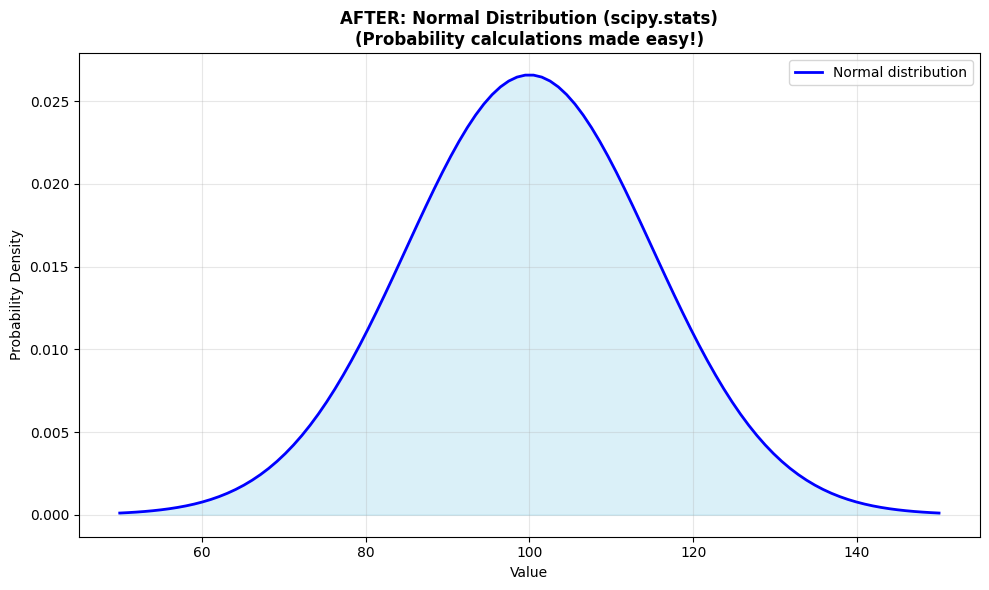

   ✅ Created probability distribution visualization!
   📝 PDF = Probability Density Function (shows probability at each value)

   🔹 Optimization (VERY COMMON for Training Models!):
   ⏰ WHEN to use: Notebook 4 (Optimization) - find optimal solutions, train ML models
   💡 WHY use: Training ML models = optimization problem - find weights that minimize loss!
   # Function: f(x) = x²  (simple optimization example)
   # Find minimum: optimize.minimize(objective, x0=5)  (start from x=5)
   ✅ Found minimum at: x = -0.000000  (should be close to 0!)
   Minimum value: f(x) = 0.000000  (should be close to 0!)
   📝 Training ML models = minimize loss function - same idea as this!
   📝 SciPy.optimize provides many optimization algorithms (gradient descent, etc.)

🔗 HOW THIS HELPS IN AI:
   • Probability: Calculate probabilities for uncertainty (Notebook 3)
   • Optimization: Find optimal solutions (Notebook 4)
   • Statistics: Analyze data and distributions

📊 BEFORE vs AFTER:
   BEFORE: Write sta

In [13]:
# SciPy: Scientific Computing

from scipy import stats  # Statistical functions
from scipy import optimize  # Optimization functions
import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("✅ AFTER: SciPy (Scientific Computing Made Easy)")
print("=" * 70)
print()

# MOST FREQUENTLY USED SCIPY OPERATIONS (What AI Engineers Use!)
print("📊 MOST FREQUENTLY USED SCIPY OPERATIONS:")
print()

# 1. Statistical functions (VERY COMMON for uncertainty/probability!)
print("   🔹 Statistical Functions (VERY COMMON for Uncertainty/Probability!):")
print("   ⏰ WHEN to use: Notebook 3 (Uncertainty) - calculate probabilities, work with distributions")
print("   💡 WHY use: SciPy.stats provides tested statistical functions - don't implement from scratch!")
# Generate sample data (seeded so the printed numbers are reproducible)
np.random.seed(42)
data = np.random.normal(100, 15, 1000)  # Generate 1000 random numbers: Normal distribution (mean=100, std=15)

# Calculate statistics
mean = np.mean(data)  # Calculate mean: Average value
std = np.std(data)    # Calculate standard deviation: Spread/dispersion of data

# Create normal distribution
normal_dist = stats.norm(mean, std)  # Create normal distribution object: Mean=mean, Std=std

print(f"   # Generate data: np.random.normal(100, 15, 1000)  (normal distribution)")
print(f"   # Calculate stats: mean = {mean:.2f}, std = {std:.2f}")
print(f"   # Create distribution: stats.norm(mean, std)  (normal distribution object)")
print()

# Probability calculations
prob_above_120 = 1 - normal_dist.cdf(120)  # Probability of value > 120: 1 - cumulative density at 120
print(f"   # Probability: 1 - normal_dist.cdf(120)  (probability of value > 120)")
print(f"   Probability of value > 120: {prob_above_120:.4f}  (i.e., a {prob_above_120:.1%} chance)")
print("   📝 CDF = Cumulative Distribution Function (probability of value <= x)")
print()

# 2. Probability distributions (VERY COMMON for visualization!)
print("   🔹 Probability Distributions (VERY COMMON for Visualization!):")
print("   ⏰ WHEN to use: Visualize probability distributions, understand uncertainty")
print("   💡 WHY use: PDF shows probability density - helps understand data distribution!")
# Normal distribution
x = np.linspace(50, 150, 100)  # X values: 100 evenly spaced points from 50 to 150
pdf_normal = stats.norm.pdf(x, 100, 15)  # Probability density function: PDF at each x value

plt.figure(figsize=(10, 6))  # Create figure: 10x6 inches
plt.plot(x, pdf_normal, 'b-', linewidth=2, label='Normal distribution')  # Plot PDF: Blue line
plt.fill_between(x, pdf_normal, alpha=0.3, color='skyblue')  # Fill area: Light blue (shows probability area)
plt.xlabel('Value')  # X-axis label
plt.ylabel('Probability Density')  # Y-axis label
plt.title('AFTER: Normal Distribution (scipy.stats)\n(Probability calculations made easy!)', fontweight='bold')  # Title
plt.legend()  # Show legend
plt.grid(True, alpha=0.3)  # Add grid
plt.tight_layout()  # Adjust spacing
plt.show()  # Display plot

print("   ✅ Created probability distribution visualization!")
print("   📝 PDF = Probability Density Function (shows probability at each value)")
print()

# 3. Optimization (VERY COMMON for training models!)
print("   🔹 Optimization (VERY COMMON for Training Models!):")
print("   ⏰ WHEN to use: Notebook 4 (Optimization) - find optimal solutions, train ML models")
print("   💡 WHY use: Training ML models = optimization problem - find weights that minimize loss!")
# Define function to optimize
def objective(x):
    """Function to minimize: f(x) = x²"""
    return x**2  # Simple function: Returns x squared

# Find minimum
result = optimize.minimize(objective, x0=5)  # Find minimum: Start from x=5, find x that minimizes f(x)

print(f"   # Function: f(x) = x²  (simple optimization example)")
print(f"   # Find minimum: optimize.minimize(objective, x0=5)  (start from x=5)")
print(f"   ✅ Found minimum at: x = {result.x[0]:.6f}  (should be close to 0!)")
print(f"   Minimum value: f(x) = {result.fun:.6f}  (should be close to 0!)")
print("   📝 Training ML models = minimize loss function - same idea as this!")
print("   📝 SciPy.optimize provides many optimization algorithms (gradient descent, etc.)")
print()

print("🔗 HOW THIS HELPS IN AI:")
print("   • Probability: Calculate probabilities for uncertainty (Notebook 3)")
print("   • Optimization: Find optimal solutions (Notebook 4)")
print("   • Statistics: Analyze data and distributions")
print()
print("📊 BEFORE vs AFTER:")
print("   BEFORE: Write statistics functions → Error-prone, time-consuming")
print("   AFTER: SciPy → Ready-to-use, tested, optimized!")


### 🔎 Read the figure

One symmetric hump, peaking at 100 (the mean) and already hugging the axis by 60 and 140 — a little under three standard deviations either side of centre, since σ = 15. The y axis is **probability density**, not a count: no single value has a probability, only intervals do, and the probability of an interval is the *shaded area* over it. That is the whole reason `scipy.stats` gives you `.cdf()` as well as `.pdf()` — `.cdf(b) - .cdf(a)` is that area, computed rather than eyeballed. Contrast this smooth ideal curve with the histogram earlier in the notebook: that one was 1,000 *samples* from exactly this distribution, and it came out lumpy, with its mean at 100.7 rather than 100. The curve is the population; the histogram is what a sample of it actually looks like.

In [14]:
# 📚 QUICK REFERENCE: SciPy Most Commonly Used Functions
# Complete cheat sheet of functions you'll use in AI projects

# HOW TO USE THIS CELL: it computes nothing new - it prints a cheat sheet you can re-open while coding, so you never have to memorize function names.

from scipy import stats, optimize
import numpy as np

print("=" * 70)
print("📚 SCIPY FUNCTION REFERENCE - Most Commonly Used Functions")
print("=" * 70)
print()

print("🔹 STATISTICAL FUNCTIONS (scipy.stats):")
print("   stats.norm(mean, std)                  # Normal distribution")
print("   dist.pdf(x)                            # Probability density at x")
print("   dist.cdf(x)                            # Cumulative probability P(X ≤ x)")
print("   dist.ppf(0.95)                         # Percent point (inverse CDF)")
print("   stats.mean(data)                       # Mean")
print("   stats.median(data)                     # Median")
print("   stats.mode(data)                       # Mode")
print("   stats.std(data)                        # Standard deviation")
print("   stats.percentile(data, 75)             # 75th percentile")
print("   stats.pearsonr(x, y)                   # Pearson correlation")
print("   stats.ttest_1samp(data, mean)          # T-test")
print()

print("🔹 PROBABILITY DISTRIBUTIONS:")
print("   stats.norm(0, 1)                       # Standard normal")
print("   stats.uniform(low, high)               # Uniform distribution")
print("   stats.expon(scale)                     # Exponential")
print("   stats.binom(n, p)                      # Binomial")
print("   stats.poisson(mu)                      # Poisson")
print("   dist.rvs(size=100)                     # Random variates (samples)")
print()

print("🔹 OPTIMIZATION (scipy.optimize - VERY COMMON!):")
print("   optimize.minimize(func, x0)            # Minimize function (general)")
print("   optimize.minimize_scalar(func)         # Minimize 1D function")
print("   optimize.curve_fit(func, x, y)         # Fit curve to data")
print("   optimize.root(func, x0)                # Find root (zero)")
print("   optimize.linprog(c, A, b)              # Linear programming")
print("   result.x                                # Optimal solution")
print("   result.fun                              # Optimal value")
print()

print("🔹 OPTIMIZATION METHODS:")
print("   method='BFGS'                          # Quasi-Newton method")
print("   method='L-BFGS-B'                      # Bounded optimization")
print("   method='Nelder-Mead'                   # Simplex method")
print("   method='Powell'                        # Powell's method")
print()

print("🔹 COMMON PATTERNS:")
print("   # Probability calculation:")
print("   dist = stats.norm(100, 15)")
print("   prob = 1 - dist.cdf(120)  # P(X > 120)")
print()
print("   # Optimization:")
print("   result = optimize.minimize(objective, x0=5)")
print("   optimal_x = result.x")
print()

print("💡 TIP: SciPy.stats is essential for probability/uncertainty (Notebook 3)!")
print("💡 TIP: SciPy.optimize is essential for optimization (Notebook 4)!")
print("💡 TIP: Training ML models = optimization problem - same functions!")


📚 SCIPY FUNCTION REFERENCE - Most Commonly Used Functions

🔹 STATISTICAL FUNCTIONS (scipy.stats):
   stats.norm(mean, std)                  # Normal distribution
   dist.pdf(x)                            # Probability density at x
   dist.cdf(x)                            # Cumulative probability P(X ≤ x)
   dist.ppf(0.95)                         # Percent point (inverse CDF)
   stats.mean(data)                       # Mean
   stats.median(data)                     # Median
   stats.mode(data)                       # Mode
   stats.std(data)                        # Standard deviation
   stats.percentile(data, 75)             # 75th percentile
   stats.pearsonr(x, y)                   # Pearson correlation
   stats.ttest_1samp(data, mean)          # T-test

🔹 PROBABILITY DISTRIBUTIONS:
   stats.norm(0, 1)                       # Standard normal
   stats.uniform(low, high)               # Uniform distribution
   stats.expon(scale)                     # Exponential
   stats.binom(n, p)   

## Part 7: Scikit-learn - Machine Learning

### 📚 What is Scikit-learn?
Scikit-learn = Machine learning library for Python - simple, efficient, powerful!

**THE PROBLEM**: Implementing ML algorithms from scratch is very difficult.
**THE SOLUTION**: Scikit-learn provides ready-made ML algorithms - just use them!

**Why Scikit-learn for AI?**
- All common ML algorithms (regression, classification, clustering)
- Simple API: fit(), predict() - that's it!
- Used in Notebook 5 (AI Learning Models)
- Industry standard - used everywhere!

✅ AFTER: Scikit-learn (Machine Learning Made Easy)

📊 MOST FREQUENTLY USED SCIKIT-LEARN OPERATIONS:

   🔹 Linear Regression (MOST COMMON for Beginners!):
   ⏰ WHEN to use: Predict numeric values (e.g., predict house price from size)
   💡 WHY use: Simplest ML model - good starting point, easy to understand!
   # Generate data: X (features), y (target)
   Generated 100 data points
   Relationship: y ≈ 2x + 1 (with noise)  (true relationship hidden in data)

   # Split data: train_test_split(X, y, test_size=0.2)  (ALWAYS split before training!)
   Training data: 80 samples  (model learns from this)
   Testing data: 20 samples  (model evaluated on this - unseen data)
   📝 ALWAYS split data - never test on training data (would be cheating!)

   🔹 Create and Train Model (Just 2 Lines!):
   ⏰ WHEN to use: AFTER splitting data - train model on training set
   💡 WHY use: Scikit-learn makes ML easy - just fit() and predict()!
   # Create model: model = LinearRegression()  (create empty model)
  

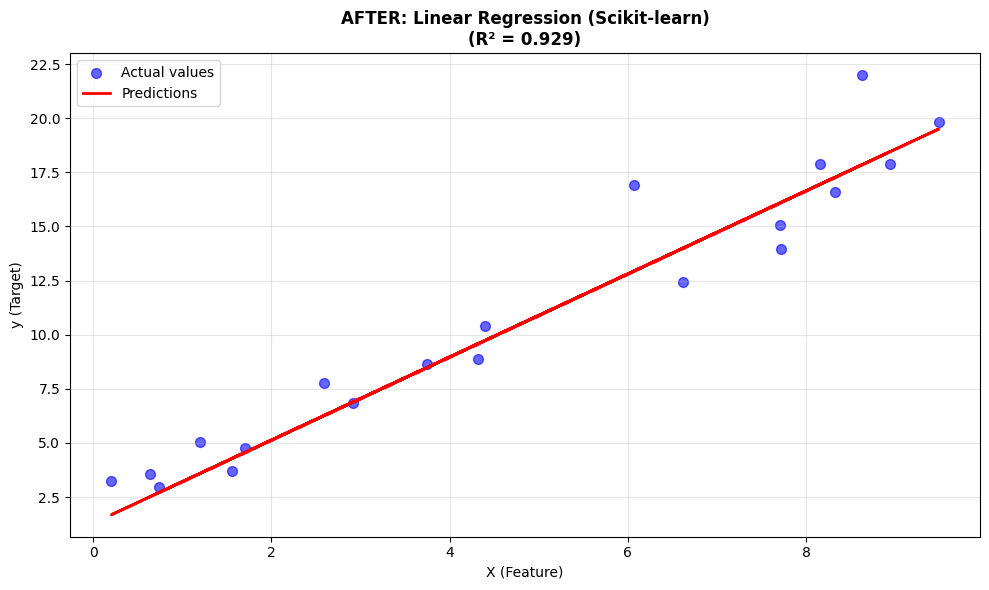

   ✅ Visualized predictions vs actual values!

🔗 HOW THIS HELPS IN AI:
   • Easy ML: Simple API - fit() to train, predict() to predict
   • All algorithms: Regression, classification, clustering - all included
   • Industry standard: Used in real-world AI applications

📊 BEFORE vs AFTER:
   BEFORE: Write ML algorithms → Very difficult, time-consuming
   AFTER: Scikit-learn → Just use ready-made algorithms, focus on data!

💡 This is what Notebook 5 (AI Learning Models) uses!
   You'll learn: Decision Trees, Random Forest, Neural Networks, and more!


In [15]:
# Scikit-learn: Machine Learning Made Easy

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("✅ AFTER: Scikit-learn (Machine Learning Made Easy)")
print("=" * 70)
print()

# MOST FREQUENTLY USED SCIKIT-LEARN OPERATIONS (What AI Engineers Use!)
print("📊 MOST FREQUENTLY USED SCIKIT-LEARN OPERATIONS:")
print()

# 1. Linear Regression (MOST COMMON for beginners!)
print("   🔹 Linear Regression (MOST COMMON for Beginners!):")
print("   ⏰ WHEN to use: Predict numeric values (e.g., predict house price from size)")
print("   💡 WHY use: Simplest ML model - good starting point, easy to understand!")
# Generate sample data
np.random.seed(42)  # Set random seed: Makes results reproducible
X = np.random.rand(100, 1) * 10  # Features: 100 samples, 1 feature (house size), values 0-10
y = 2 * X.flatten() + 1 + np.random.randn(100) * 2  # Target: y = 2x + 1 + noise (house price with some randomness)

print(f"   # Generate data: X (features), y (target)")
print(f"   Generated {len(X)} data points")
print(f"   Relationship: y ≈ 2x + 1 (with noise)  (true relationship hidden in data)")
print()

# Split data: training (80%) and testing (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)  # Split: 80% train, 20% test

print(f"   # Split data: train_test_split(X, y, test_size=0.2)  (ALWAYS split before training!)")
print(f"   Training data: {len(X_train)} samples  (model learns from this)")
print(f"   Testing data: {len(X_test)} samples  (model evaluated on this - unseen data)")
print("   📝 ALWAYS split data - never test on training data (would be cheating!)")
print()

# 2. Create and train model (THE POWER OF SCIKIT-LEARN!)
print("   🔹 Create and Train Model (Just 2 Lines!):")
print("   ⏰ WHEN to use: AFTER splitting data - train model on training set")
print("   💡 WHY use: Scikit-learn makes ML easy - just fit() and predict()!")

model = LinearRegression()  # Create model: Initialize linear regression model (no parameters needed!)
model.fit(X_train, y_train)  # Train model: Learn relationship from training data (this is where learning happens!)

print(f"   # Create model: model = LinearRegression()  (create empty model)")
print(f"   # Train model: model.fit(X_train, y_train)  (model LEARNS from data)")
print(f"   ✅ Model trained!")
print(f"   Learned relationship: y = {model.coef_[0]:.2f}x + {model.intercept_:.2f}  (learned from data)")
print(f"   (Close to true: y = 2.00x + 1.00)  (model should learn something close!)")
print("   📝 model.coef_ = learned coefficients, model.intercept_ = learned intercept")
print()

# 3. Make predictions (VERY COMMON!)
print("   🔹 Make Predictions (VERY COMMON!):")
print("   ⏰ WHEN to use: AFTER training - predict on new, unseen data")
print("   💡 WHY use: Use trained model to make predictions on real data!")

y_pred = model.predict(X_test)  # Predict on test data: Use trained model to predict on unseen test data

# Evaluate accuracy
accuracy = r2_score(y_test, y_pred)  # R² score: Measures how well predictions match actual values (closer to 1 = better)
print(f"   # Predict: y_pred = model.predict(X_test)  (predict on test data)")
print(f"   # Evaluate: r2_score(y_test, y_pred)  (measure accuracy)")
print(f"   ✅ R² Score: {accuracy:.4f} (1.0 = perfect prediction, <1 = some error)")
print("   📝 R² score: 1.0 = perfect, 0 = no better than average, negative = worse than average")
print()

# 4. Visualize results
plt.figure(figsize=(10, 6))
plt.scatter(X_test, y_test, alpha=0.6, color='blue', s=50, label='Actual values')
plt.plot(X_test, y_pred, 'r-', linewidth=2, label='Predictions')
plt.xlabel('X (Feature)')
plt.ylabel('y (Target)')
plt.title(f'AFTER: Linear Regression (Scikit-learn)\n(R² = {accuracy:.3f})', fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("   ✅ Visualized predictions vs actual values!")
print()

print("🔗 HOW THIS HELPS IN AI:")
print("   • Easy ML: Simple API - fit() to train, predict() to predict")
print("   • All algorithms: Regression, classification, clustering - all included")
print("   • Industry standard: Used in real-world AI applications")
print()
print("📊 BEFORE vs AFTER:")
print("   BEFORE: Write ML algorithms → Very difficult, time-consuming")
print("   AFTER: Scikit-learn → Just use ready-made algorithms, focus on data!")
print()
print("💡 This is what Notebook 5 (AI Learning Models) uses!")
print("   You'll learn: Decision Trees, Random Forest, Neural Networks, and more!")


### 🔎 Read the figure

**What to look for.** Blue dots are the true `y` values; the red line is what the model predicts for each `x`. The dots scatter *around* the line rather than sitting on it, and the scatter is roughly the same width at every `x` — no fan shape, no curve left behind. That is the picture of a straight-line model fitting data that really is a straight line plus noise.

**What R² = 0.929 means here.** The line accounts for about 93% of the variation in `y`; the remaining 7% is the noise term that was deliberately added when the data was made. This is a *constructed* example — the true relationship is `y = 2x + 1`, written into the data a few lines above inside this same cell — so the honest reading is "the model recovered a rule we already knew", not "linear regression scores 0.93 on real problems". Real data almost never fits this well; the diabetes and housing datasets you will meet later score far lower with the same model.

**The check worth stealing.** Always plot predictions against actuals like this before you trust a score. A high R² with a visible *curve* in the residuals means a straight line was the wrong shape and the number flattered you.

In [16]:
# 📚 QUICK REFERENCE: Scikit-learn Most Commonly Used Functions
# Complete cheat sheet of functions you'll use in AI projects

# HOW TO USE THIS CELL: it computes nothing new - it prints a cheat sheet you can re-open while coding, so you never have to memorize function names.

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, r2_score, mean_squared_error

print("=" * 70)
print("📚 SCIKIT-LEARN FUNCTION REFERENCE - Most Commonly Used Functions")
print("=" * 70)
print()

print("🔹 DATA SPLITTING (ALWAYS DO THIS FIRST!):")
print("   X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)")
print("   train_test_split(X, y, test_size=0.2, random_state=42)  # Reproducible")
print("   train_test_split(X, y, train_size=0.8)                  # 80% train")
print()

print("🔹 MODEL TRAINING (Universal Pattern):")
print("   model = SomeModel()                     # Create model")
print("   model.fit(X_train, y_train)             # Train model")
print("   predictions = model.predict(X_test)     # Make predictions")
print()

print("🔹 REGRESSION MODELS:")
print("   from sklearn.linear_model import LinearRegression")
print("   model = LinearRegression()              # Linear regression")
print("   model.fit(X_train, y_train)")
print("   y_pred = model.predict(X_test)")
print("   score = model.score(X_test, y_test)     # R² score")
print()

print("🔹 CLASSIFICATION MODELS:")
print("   from sklearn.tree import DecisionTreeClassifier")
print("   from sklearn.ensemble import RandomForestClassifier")
print("   model = DecisionTreeClassifier()        # Decision tree")
print("   model = RandomForestClassifier(n_estimators=100)  # Random forest")
print("   model.fit(X_train, y_train)")
print("   y_pred = model.predict(X_test)")
print()

print("🔹 EVALUATION METRICS:")
print("   from sklearn.metrics import accuracy_score, r2_score, mean_squared_error")
print("   accuracy_score(y_true, y_pred)          # Classification accuracy")
print("   r2_score(y_true, y_pred)                # R² score (regression)")
print("   mean_squared_error(y_true, y_pred)      # MSE (regression)")
print("   confusion_matrix(y_true, y_pred)        # Confusion matrix")
print("   classification_report(y_true, y_pred)   # Detailed report")
print()

print("🔹 FEATURE SCALING (IMPORTANT!):")
print("   from sklearn.preprocessing import StandardScaler")
print("   scaler = StandardScaler()               # Standardize features")
print("   X_train_scaled = scaler.fit_transform(X_train)")
print("   X_test_scaled = scaler.transform(X_test)")
print()

print("🔹 COMMON PATTERN (Complete Workflow):")
print("   # 1. Split data")
print("   X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)")
print("   # 2. Create and train model")
print("   model = LinearRegression()")
print("   model.fit(X_train, y_train)")
print("   # 3. Make predictions")
print("   y_pred = model.predict(X_test)")
print("   # 4. Evaluate")
print("   score = r2_score(y_test, y_pred)")
print()

print("💡 TIP: ALWAYS split data before training - never test on training data!")
print("💡 TIP: Universal API: fit() to train, predict() to predict - same for all models!")
print("💡 TIP: Scikit-learn is essential for Notebook 5 (AI Learning Models)!")


📚 SCIKIT-LEARN FUNCTION REFERENCE - Most Commonly Used Functions

🔹 DATA SPLITTING (ALWAYS DO THIS FIRST!):
   X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
   train_test_split(X, y, test_size=0.2, random_state=42)  # Reproducible
   train_test_split(X, y, train_size=0.8)                  # 80% train

🔹 MODEL TRAINING (Universal Pattern):
   model = SomeModel()                     # Create model
   model.fit(X_train, y_train)             # Train model
   predictions = model.predict(X_test)     # Make predictions

🔹 REGRESSION MODELS:
   from sklearn.linear_model import LinearRegression
   model = LinearRegression()              # Linear regression
   model.fit(X_train, y_train)
   y_pred = model.predict(X_test)
   score = model.score(X_test, y_test)     # R² score

🔹 CLASSIFICATION MODELS:
   from sklearn.tree import DecisionTreeClassifier
   from sklearn.ensemble import RandomForestClassifier
   model = DecisionTreeClassifier()        # Decision tree
   mode

## Part 8: Summary — all libraries together


In [17]:
# Summary cell: one dictionary that maps every library in this notebook to its role in the course.
# Why: seeing the whole toolbox at once shows how the pieces combine into an AI workflow.
import numpy as np
# Summary: All Libraries Working Together

print("=" * 70)
print("✅ SUMMARY: All Libraries for AI")
print("=" * 70)
print()

# Store each library's purpose, where the course uses it, and its key functions in a nested dict.
libraries_summary = {
    "NumPy": {
        "purpose": "Numerical computing - fast arrays and math", "used_in": "All notebooks - everything uses NumPy arrays!",
        "key_functions": "np.array(), np.mean(), np.random.rand()", "why_ai": "AI needs fast math - NumPy is 100x faster than Python lists"
    },
    "Matplotlib": {
        "purpose": "Visualization - create graphs and charts",
        "used_in": "All notebooks - visualize data, algorithms, results",
        "key_functions": "plt.plot(), plt.scatter(), plt.hist(), plt.show()", "why_ai": "AI works with data - visualizations help us understand"
    },
    "Collections/heapq": {
        "purpose": "Efficient data structures - queues and priority queues",
        "used_in": "Notebook 1 (Search Algorithms)",
        "key_functions": "deque(), heapq.heappush(), heapq.heappop()", "why_ai": "Search algorithms need efficient queues (BFS, A*)"
    },
    "NetworkX": {
        "purpose": "Graph operations - create and manipulate graphs",
        "used_in": "Notebook 2 (Knowledge Representation)",
        "key_functions": "nx.Graph(), nx.add_edge(), nx.shortest_path()", "why_ai": "Knowledge graphs need graph operations"
    },
    "SciPy": {
        "purpose": "Scientific computing - stats, optimization",
        "used_in": "Notebook 3 (Uncertainty), Notebook 4 (Optimization)",
        "key_functions": "scipy.stats, scipy.optimize.minimize()", "why_ai": "Probability, optimization, statistics - essential for AI"
    },
    "Scikit-learn": {
        "purpose": "Machine learning - ready-made ML algorithms",
        "used_in": "Notebook 5 (AI Learning Models)",
        "key_functions": "fit(), predict(), train_test_split()", "why_ai": "ML models need algorithms - scikit-learn provides them!"
    }
}

print("📚 Library Summary:")
print()
# Loop over the dict and print a readable one-screen summary per library.
for lib_name, info in libraries_summary.items():
    print(f"   📦 {lib_name}:")
    print(f"      Purpose: {info['purpose']}")
    print(f"      Used in: {info['used_in']}")
    print(f"      Key functions: {info['key_functions']}")
    print(f"      Why AI: {info['why_ai']}")
    print()

print("=" * 70)
print("🔗 HOW THEY WORK TOGETHER:")
print("=" * 70)
print()
print("   Typical AI workflow:")
print("   1. NumPy: Load and process data (arrays)")
print("   2. Scikit-learn: Train ML model (fit on NumPy arrays)")
print("   3. NumPy: Make predictions (get NumPy arrays back)")
print("   4. Matplotlib: Visualize results (plot NumPy arrays)")
print()
print("   Search algorithm workflow:")
print("   1. NetworkX: Create graph (nodes and edges)")
print("   2. Collections/heapq: Use queue/priority queue (BFS/A*)")
print("   3. NetworkX: Find path (shortest_path)")
print("   4. Matplotlib: Visualize graph and path")
print()
print("=" * 70)
print("✅ YOU'RE READY FOR AI NOTEBOOKS!")
print("=" * 70)
print()
print("   Next steps:")
print("   📓 Notebook 1: Introduction & Search Algorithms")
print("      → Uses: NumPy, Matplotlib, Collections, heapq")
print()
print("   📓 Notebook 2: Knowledge Representation")
print("      → Uses: NetworkX, Matplotlib, Python classes")
print()
print("   📓 Notebook 3: Learning under Uncertainty")
print("      → Uses: NumPy, SciPy.stats, Matplotlib")
print()
print("   📓 Notebook 4: Optimization Techniques")
print("      → Uses: NumPy, SciPy.optimize, Matplotlib")
print()
print("   📓 Notebook 5: AI Learning Models")
print("      → Uses: NumPy, Scikit-learn, Matplotlib")
print()
print("🔗 All notebooks use NumPy and Matplotlib - you'll see them everywhere!")
print()
print("📊 BEFORE vs AFTER:")
print("   BEFORE: Not knowing libraries → Confused in AI notebooks")
print("   AFTER: Knowing all libraries → Ready to build AI systems!")

✅ SUMMARY: All Libraries for AI

📚 Library Summary:

   📦 NumPy:
      Purpose: Numerical computing - fast arrays and math
      Used in: All notebooks - everything uses NumPy arrays!
      Key functions: np.array(), np.mean(), np.random.rand()
      Why AI: AI needs fast math - NumPy is 100x faster than Python lists

   📦 Matplotlib:
      Purpose: Visualization - create graphs and charts
      Used in: All notebooks - visualize data, algorithms, results
      Key functions: plt.plot(), plt.scatter(), plt.hist(), plt.show()
      Why AI: AI works with data - visualizations help us understand

   📦 Collections/heapq:
      Purpose: Efficient data structures - queues and priority queues
      Used in: Notebook 1 (Search Algorithms)
      Key functions: deque(), heapq.heappush(), heapq.heappop()
      Why AI: Search algorithms need efficient queues (BFS, A*)

   📦 NetworkX:
      Purpose: Graph operations - create and manipulate graphs
      Used in: Notebook 2 (Knowledge Representation)

## Part 9: Practice Exercises


In [18]:
# Practice prompts: small exercises for you to try in a fresh cell below.
# Why: reading library examples is not enough - recalling the function yourself is what makes it stick.
import numpy as np
# Practice Exercise 1: NumPy Arrays
# YOUR TURN: Create arrays and perform operations

print("=" * 70)
print("🎯 PRACTICE EXERCISE 1: NumPy Arrays")
print("=" * 70)
print()

# TODO: Try these exercises yourself!
print("📝 Exercise 1.1: Create a NumPy array from list [10, 20, 30, 40, 50]")
print("   Hint: Use np.array()")
print()

print("📝 Exercise 1.2: Create an array of 10 zeros")
print("   Hint: Use np.zeros(10)")
print()

print("📝 Exercise 1.3: Create an array with values from 0 to 20 (step 2)")
print("   Hint: Use np.arange(0, 21, 2)")
print()

print("📝 Exercise 1.4: Create an array of 5 evenly spaced numbers from 0 to 1")
print("   Hint: Use np.linspace(0, 1, 5)")
print()

print("📝 Exercise 1.5: Given array [1, 2, 3, 4, 5], calculate:")
print("   - Mean (average)")
print("   - Maximum value")
print("   - Sum of all values")
print("   Hint: Use np.mean(), np.max(), np.sum()")
print()

# Practice Exercise 2: Matplotlib
print("=" * 70)
print("🎯 PRACTICE EXERCISE 2: Matplotlib Visualization")
print("=" * 70)
print()

print("📝 Exercise 2.1: Create a line plot of y = x² for x from 0 to 10")
print("   Hint: Use np.linspace() and plt.plot()")
print()

print("📝 Exercise 2.2: Create a scatter plot of 20 random points")
print("   Hint: Use np.random.randn(20) and plt.scatter()")
print()

print("📝 Exercise 2.3: Create a histogram of 1000 random numbers (normal distribution)")
print("   Hint: Use np.random.normal() and plt.hist()")
print()

# Practice Exercise 3: Collections and heapq
print("=" * 70)
print("🎯 PRACTICE EXERCISE 3: Collections & heapq")
print("=" * 70)
print()

print("📝 Exercise 3.1: Create a queue using deque")
print("   - Add items: 'apple', 'banana', 'cherry'")
print("   - Remove items one by one from front")
print("   Hint: Use deque(), append(), popleft()")
print()

print("📝 Exercise 3.2: Create a priority queue using heapq")
print("   - Add items with priorities: (5, 'high'), (2, 'medium'), (8, 'low')")
print("   - Remove items (smallest priority first)")
print("   Hint: Use heapq.heappush() and heapq.heappop()")
print()

print("✅ Practice these exercises to master the libraries!")
print("💡 Answers are in the code examples above - try them yourself first!")

🎯 PRACTICE EXERCISE 1: NumPy Arrays

📝 Exercise 1.1: Create a NumPy array from list [10, 20, 30, 40, 50]
   Hint: Use np.array()

📝 Exercise 1.2: Create an array of 10 zeros
   Hint: Use np.zeros(10)

📝 Exercise 1.3: Create an array with values from 0 to 20 (step 2)
   Hint: Use np.arange(0, 21, 2)

📝 Exercise 1.4: Create an array of 5 evenly spaced numbers from 0 to 1
   Hint: Use np.linspace(0, 1, 5)

📝 Exercise 1.5: Given array [1, 2, 3, 4, 5], calculate:
   - Mean (average)
   - Maximum value
   - Sum of all values
   Hint: Use np.mean(), np.max(), np.sum()

🎯 PRACTICE EXERCISE 2: Matplotlib Visualization

📝 Exercise 2.1: Create a line plot of y = x² for x from 0 to 10
   Hint: Use np.linspace() and plt.plot()

📝 Exercise 2.2: Create a scatter plot of 20 random points
   Hint: Use np.random.randn(20) and plt.scatter()

📝 Exercise 2.3: Create a histogram of 1000 random numbers (normal distribution)
   Hint: Use np.random.normal() and plt.hist()

🎯 PRACTICE EXERCISE 3: Collections & 

## Final Summary

### The toolbox, by role

- **Numerical core:** NumPy, SciPy
- **Plots:** Matplotlib, Seaborn
- **Data handling:** pandas, JSON
- **Algorithm data structures:** `collections.deque`, `heapq`; graphs with NetworkX
- **Machine learning:** scikit-learn; deep learning with TensorFlow/Keras or PyTorch
- **Images and text:** OpenCV, Pillow; NLTK, spaCy
- **Utilities:** Pickle/Joblib (saving models), tqdm (progress bars), Requests (APIs)

### Where each one is used in this course

- **Search Algorithms (next lesson):** NumPy, Matplotlib, `deque` and `heapq` for the BFS and A\* frontiers
- **Knowledge Representation (Unit 2):** NetworkX for knowledge graphs, Matplotlib
- **Learning under Uncertainty (Unit 3):** NumPy, `scipy.stats`, Matplotlib
- **Optimization (Unit 4):** NumPy, `scipy.optimize`, Matplotlib
- **AI Learning Models (Unit 5):** scikit-learn, NumPy, Matplotlib

### Key takeaways

1. **Measure, do not quote.** The speed-up you timed in Part 2 is evidence; the "100×" in a tutorial is a hypothesis.
2. **Libraries encode choices.** `np.std` and `pandas.Series.std` divide by different numbers; read the docstring before a figure goes into a report.
3. **`import numpy as np` should tell you what the file is about to do.** Knowing the toolbox is most of reading AI code.
4. **A missing library breaks the lesson, not the idea.** Pin versions and check the environment before you demonstrate anything.


## Part 10: Pandas - Data Manipulation

### 📚 What is Pandas?
Pandas = **Pan**el **Da**ta - provides powerful data structures for data manipulation!

**THE PROBLEM**: NumPy arrays are good for numbers, but real data has labels, mixed types, missing values.
**THE SOLUTION**: Pandas DataFrames - like Excel spreadsheets in Python, but much more powerful!

**Why Pandas for AI?**
- AI works with data - Pandas makes data manipulation EASY
- Handle CSV files, Excel files, databases
- Clean, filter, transform data before feeding to ML models
- Essential for data preprocessing (80% of ML work!)

In [19]:
# Pandas: Data Manipulation Made Easy

try:
    import pandas as pd  # Import Pandas (standard: use 'pd' as alias)
    import numpy as np
    HAS_PANDAS = True
except ImportError:
    HAS_PANDAS = False
    print("⚠️  Pandas not installed. Install with: pip install pandas")

if HAS_PANDAS:
    print("=" * 70)
    print("✅ AFTER: Pandas (Data Manipulation Made Easy)")
    print("=" * 70)
    print()
    
    # 1. Creating DataFrames
    print("📊 Step 1: Creating DataFrames (Like Excel Spreadsheets!)")
    print()
    
    # From dictionary
    data = {
        'Name': ['Alice', 'Bob', 'Charlie', 'Diana'],
        'Age': [25, 30, 35, 28],
        'Salary': [50000, 60000, 70000, 55000]
    }
    df = pd.DataFrame(data)  # Create DataFrame from dictionary
    
    print("   DataFrame from dictionary:")
    print(df)
    print()
    print(f"   Shape: {df.shape} (rows, columns)")
    print(f"   Columns: {list(df.columns)}")
    print()
    
    # 2. MOST FREQUENTLY USED PANDAS OPERATIONS (What AI Engineers Use Every Day!)
    print("📊 Step 2: Most Frequently Used Pandas Operations (What AI Engineers Use!)")
    print()
    
    # 2.1 Filtering data (VERY COMMON!)
    print("   🔹 Filtering Data (MOST COMMON in AI!):")
    print("   ⏰ WHEN to use: When you need to select rows that meet certain conditions")
    print("   💡 WHY use: Essential for data cleaning, finding specific subsets, preprocessing")
    print("   📝 Example: Filter people older than 28")
    filtered = df[df['Age'] > 28]  # People older than 28
    print(f"   # Filter: df[df['Age'] > 28]")
    print(f"   Result: {len(filtered)} rows")
    print(filtered)
    print()
    
    # Multiple conditions
    print("   📝 Example: Multiple conditions (AND operator)")
    filtered2 = df[(df['Age'] > 25) & (df['Salary'] > 55000)]
    print(f"   # Multiple conditions: df[(df['Age'] > 25) & (df['Salary'] > 55000)]")
    print(f"   ⏰ WHEN: Need rows that meet ALL conditions (use & for AND, | for OR)")
    print(f"   Result: {len(filtered2)} rows")
    print(filtered2)
    print()
    
    # 2.2 Selecting columns (VERY COMMON!)
    print("   🔹 Selecting Columns (MOST COMMON!):")
    print("   ⏰ WHEN to use: When you need only specific columns (reduces memory, focuses on features)")
    print("   💡 WHY use: Essential for ML (select features), reduce data size, focus on relevant columns")
    ages = df['Age']  # Single column (Series)
    name_age = df[['Name', 'Age']]  # Multiple columns (DataFrame)
    print(f"   # Single column: df['Age'] → {ages.tolist()}  (returns Series)")
    print(f"   # Multiple columns: df[['Name', 'Age']]  (returns DataFrame)")
    print(name_age)
    print()
    
    # 2.3 Adding/modifying columns (COMMON!)
    print("   🔹 Adding/Modifying Columns (COMMON!):")
    print("   ⏰ WHEN to use: Feature engineering (create new features from existing), data transformation")
    print("   💡 WHY use: ML models need good features - create features that help predictions")
    df['Bonus'] = df['Salary'] * 0.1  # Add new column
    df['Total'] = df['Salary'] + df['Bonus']  # Calculate from other columns
    print("   # Add column: df['Bonus'] = df['Salary'] * 0.1  (create derived feature)")
    print("   # Calculate: df['Total'] = df['Salary'] + df['Bonus']  (combine features)")
    print(df)
    print()
    
    # 2.4 Statistics (VERY COMMON for data exploration!)
    print("   🔹 Statistics (VERY COMMON for Data Exploration!):")
    print("   ⏰ WHEN to use: BEFORE training ML models - understand your data, find outliers, check distributions")
    print("   💡 WHY use: Essential for data exploration - understand patterns, detect problems, inform preprocessing")
    print(f"   # Mean (average): df['Salary'].mean() → ${df['Salary'].mean():,.0f}")
    print(f"   # Max (highest value): df['Salary'].max() → ${df['Salary'].max():,.0f}")
    print(f"   # Min (lowest value): df['Salary'].min() → ${df['Salary'].min():,.0f}")
    print(f"   # Sum (total): df['Salary'].sum() → ${df['Salary'].sum():,.0f}")
    print(f"   # Count (non-null values): df['Salary'].count() → {df['Salary'].count()}")
    print(f"   # Std (spread/dispersion): df['Salary'].std() → ${df['Salary'].std():,.0f}")
    print()
    
    # Describe (get all statistics at once!)
    print("   # Get ALL statistics at once: df.describe()  (saves time!)")
    print("   ⏰ WHEN: Quick overview of all numeric columns")
    print(df[['Age', 'Salary']].describe())
    print()
    
    # 2.5 Sorting (COMMON!)
    print("   🔹 Sorting Data (COMMON!):")
    print("   ⏰ WHEN to use: Rank data, find top/bottom values, prepare data for display")
    print("   💡 WHY use: Identify outliers, rank features, prepare reports")
    sorted_by_age = df.sort_values('Age', ascending=False)  # Sort by age (descending)
    print(f"   # Sort: df.sort_values('Age', ascending=False)  # descending=True for reverse")
    print(sorted_by_age[['Name', 'Age']])
    print()
    
    # 2.6 Grouping (VERY COMMON for data analysis!)
    print("   🔹 Grouping Data (VERY COMMON for Data Analysis!):")
    print("   ⏰ WHEN to use: Compare groups, aggregate by category, analyze by segments")
    print("   💡 WHY use: Essential for understanding patterns across categories (e.g., by department, by region)")
    # Create example with categories
    df['Department'] = ['IT', 'HR', 'IT', 'HR']
    grouped = df.groupby('Department')['Salary'].mean()  # Average salary by department
    print(f"   # Group by department: df.groupby('Department')['Salary'].mean()")
    print(f"   📝 This calculates average salary for EACH department")
    print(grouped)
    print()
    
    # 2.7 Handling missing values (ESSENTIAL for real data!)
    print("   🔹 Handling Missing Values (ESSENTIAL for Real Data!):")
    print("   ⏰ WHEN to use: ALWAYS check before ML training - ML models can't handle missing values!")
    print("   💡 WHY use: Missing values cause errors - must fill or remove before training models")
    df_with_nan = df.copy()
    df_with_nan.loc[1, 'Age'] = None  # Add missing value
    print("   # Check missing: df['Age'].isna().sum()  (count missing values)")
    print(f"   Missing values: {df_with_nan['Age'].isna().sum()}")
    print(f"   # Fill missing: df['Age'].fillna(df['Age'].mean())  (fill with average)")
    print(f"   💡 Common strategies: mean (numbers), mode (categories), forward-fill (time series)")
    df_with_nan['Age'].fillna(df_with_nan['Age'].mean(), inplace=True)
    print(f"   After filling: {df_with_nan['Age'].isna().sum()} missing")
    print()
    
    # 3. Reading/Writing Files (ESSENTIAL FOR AI!)
    print("📊 Step 3: Reading/Writing Files (Essential for Real Data!)")
    print()
    print("   🔹 Most Common File Operations:")
    print("   ⏰ WHEN to use: Load datasets from files, save processed data, export results")
    print("   💡 WHY use: Real data comes from files - CSV (common), Excel (business), JSON (APIs)")
    print("   # Read CSV: df = pd.read_csv('data.csv')  (MOST COMMON format!)")
    print("   # Write CSV: df.to_csv('output.csv', index=False)  (index=False removes row numbers)")
    print("   # Read Excel: df = pd.read_excel('data.xlsx', sheet_name='Sheet1')")
    print("   # Write Excel: df.to_excel('output.xlsx', index=False)")
    print("   # Read JSON: df = pd.read_json('data.json')  (from APIs)")
    print("   # Write JSON: df.to_json('output.json', orient='records')")
    print()
    
    # 4. Merging DataFrames (COMMON for combining data!)
    print("📊 Step 4: Merging DataFrames (Common for Combining Data!)")
    print()
    print("   ⏰ WHEN to use: Combine data from multiple sources (e.g., user info + transaction data)")
    print("   💡 WHY use: Real data is often split across files - merge to create complete dataset")
    df2 = pd.DataFrame({
        'Name': ['Alice', 'Bob'],
        'City': ['New York', 'London']
    })
    merged = pd.merge(df[['Name', 'Salary']], df2, on='Name', how='left')
    print("   # Merge: pd.merge(df1, df2, on='Name', how='left')")
    print("   📝 how='left': Keep all rows from df1 (most common)")
    print("   📝 Other options: 'inner' (both), 'outer' (all), 'right' (df2)")
    print(merged)
    print()
    
    print("🔗 HOW THIS HELPS IN AI:")
    print("   • Data preprocessing: Clean, filter, transform data (80% of ML work!)")
    print("   • Data loading: Read CSV, Excel, JSON files easily")
    print("   • Data analysis: Calculate statistics, find patterns")
    print("   • Feature engineering: Create new features from existing data")
    print()
    print("📊 BEFORE vs AFTER:")
    print("   BEFORE: Lists/dicts → Complicated, slow, hard to filter")
    print("   AFTER: Pandas → Simple, fast, powerful data manipulation!")
    print()
    print("💡 This is what AI engineers use EVERY DAY for data preprocessing!")
else:
    print("⚠️  Please install Pandas to see examples")
    print("   Run: pip install pandas")


✅ AFTER: Pandas (Data Manipulation Made Easy)

📊 Step 1: Creating DataFrames (Like Excel Spreadsheets!)

   DataFrame from dictionary:
      Name  Age  Salary
0    Alice   25   50000
1      Bob   30   60000
2  Charlie   35   70000
3    Diana   28   55000

   Shape: (4, 3) (rows, columns)
   Columns: ['Name', 'Age', 'Salary']

📊 Step 2: Most Frequently Used Pandas Operations (What AI Engineers Use!)

   🔹 Filtering Data (MOST COMMON in AI!):
   ⏰ WHEN to use: When you need to select rows that meet certain conditions
   💡 WHY use: Essential for data cleaning, finding specific subsets, preprocessing
   📝 Example: Filter people older than 28
   # Filter: df[df['Age'] > 28]
   Result: 2 rows
      Name  Age  Salary
1      Bob   30   60000
2  Charlie   35   70000

   📝 Example: Multiple conditions (AND operator)
   # Multiple conditions: df[(df['Age'] > 25) & (df['Salary'] > 55000)]
   ⏰ WHEN: Need rows that meet ALL conditions (use & for AND, | for OR)
   Result: 2 rows
      Name  Age  Sal

In [20]:
# 📚 QUICK REFERENCE: Pandas Most Commonly Used Functions
# Complete cheat sheet of functions you'll use in AI projects

# HOW TO USE THIS CELL: it computes nothing new - it prints a cheat sheet you can re-open while coding, so you never have to memorize function names.

import pandas as pd
import numpy as np

print("=" * 70)
print("📚 PANDAS FUNCTION REFERENCE - Most Commonly Used Functions")
print("=" * 70)
print()

print("🔹 CREATING DATAFRAMES:")
print("   df = pd.DataFrame(data)                # From dictionary/list")
print("   df = pd.read_csv('file.csv')           # From CSV file")
print("   df = pd.read_excel('file.xlsx')        # From Excel file")
print("   df = pd.DataFrame({'A': [1,2,3], 'B': [4,5,6]})  # Direct creation")
print()

print("🔹 VIEWING DATA:")
print("   df.head(n)                             # First n rows (default: 5)")
print("   df.tail(n)                             # Last n rows")
print("   df.info()                              # Data types & null counts")
print("   df.describe()                          # Statistical summary")
print("   df.shape                               # (rows, columns)")
print("   df.columns                             # Column names")
print("   df.index                               # Row indices")
print()

print("🔹 SELECTING DATA:")
print("   df['column']                           # Single column (Series)")
print("   df[['col1', 'col2']]                   # Multiple columns (DataFrame)")
print("   df.loc[row_index]                      # Select by label")
print("   df.iloc[row_number]                    # Select by position")
print("   df.loc[0:5, 'col1':'col3']             # Slice rows and columns")
print()

print("🔹 FILTERING DATA (VERY COMMON!):")
print("   df[df['age'] > 30]                     # Rows where age > 30")
print("   df[(df['age'] > 30) & (df['salary'] > 50000)]  # Multiple conditions")
print("   df[df['name'].isin(['Alice', 'Bob'])]  # Value in list")
print("   df[df['column'].notna()]               # Non-null values")
print("   df[df['column'].str.contains('text')]  # String contains")
print()

print("🔹 DATA MANIPULATION:")
print("   df['new_col'] = values                 # Add new column")
print("   df.drop('column', axis=1)              # Drop column")
print("   df.dropna()                            # Remove rows with nulls")
print("   df.fillna(value)                       # Fill null values")
print("   df.sort_values('column')               # Sort by column")
print("   df.sort_values('col', ascending=False)  # Sort descending")
print()

print("🔹 STATISTICS (VERY COMMON for Data Exploration!):")
print("   df['column'].mean()                    # Mean")
print("   df['column'].median()                  # Median")
print("   df['column'].std()                     # Standard deviation")
print("   df['column'].min()                     # Minimum")
print("   df['column'].max()                     # Maximum")
print("   df['column'].sum()                     # Sum")
print("   df['column'].count()                   # Count (non-null)")
print("   df['column'].value_counts()            # Frequency counts")
print()

print("🔹 GROUPING (VERY COMMON!):")
print("   df.groupby('column')                   # Group by column")
print("   df.groupby('col')['other_col'].mean()  # Group and aggregate")
print("   df.groupby('col').agg({'col1': 'mean', 'col2': 'sum'})  # Multiple aggregations")
print()

print("🔹 APPLYING FUNCTIONS:")
print("   df['col'].apply(function)              # Apply function to column")
print("   df.apply(function, axis=1)             # Apply to each row")
print("   df['col'].map(dictionary)              # Map values")
print()

print("🔹 COMBINING DATA:")
print("   pd.concat([df1, df2])                  # Concatenate DataFrames")
print("   pd.merge(df1, df2, on='key')           # Merge/join DataFrames")
print("   df1.join(df2)                          # Join DataFrames")
print()

print("🔹 SAVING DATA:")
print("   df.to_csv('file.csv')                  # Save to CSV")
print("   df.to_excel('file.xlsx')               # Save to Excel")
print("   df.to_json('file.json')                # Save to JSON")
print()

print("💡 TIP: Pandas is essential for data preprocessing before ML!")
print("💡 TIP: Always use df.describe() first to understand your data!")
print("💡 TIP: Filter data BEFORE training ML models - clean data is key!")


📚 PANDAS FUNCTION REFERENCE - Most Commonly Used Functions

🔹 CREATING DATAFRAMES:
   df = pd.DataFrame(data)                # From dictionary/list
   df = pd.read_csv('file.csv')           # From CSV file
   df = pd.read_excel('file.xlsx')        # From Excel file
   df = pd.DataFrame({'A': [1,2,3], 'B': [4,5,6]})  # Direct creation

🔹 VIEWING DATA:
   df.head(n)                             # First n rows (default: 5)
   df.tail(n)                             # Last n rows
   df.info()                              # Data types & null counts
   df.describe()                          # Statistical summary
   df.shape                               # (rows, columns)
   df.columns                             # Column names
   df.index                               # Row indices

🔹 SELECTING DATA:
   df['column']                           # Single column (Series)
   df[['col1', 'col2']]                   # Multiple columns (DataFrame)
   df.loc[row_index]                      # Select by la

## Part 11: Seaborn - Advanced Visualization

### 📚 What is Seaborn?
Seaborn = Built on Matplotlib - provides beautiful statistical visualizations!

**THE PROBLEM**: Matplotlib plots need lots of code for beautiful statistical charts.
**THE SOLUTION**: Seaborn creates beautiful statistical plots with just a few lines!

**Why Seaborn for AI?**
- Visualize data distributions, correlations, relationships
- Beautiful default styles (looks professional!)
- Perfect for exploring data before ML modeling
- Essential for data analysis and presentation

✅ AFTER: Seaborn (Beautiful Statistical Visualizations)

📊 Data: 150 real flowers, 4 measurements each, 3 species
   Columns: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
   Species counts: setosa 50, versicolor 50, virginica 50

📊 MOST FREQUENTLY USED SEABORN PLOTS (What AI Engineers Use!)

   🔹 Scatter Plot (MOST COMMON for exploring relationships!):
   ⏰ WHEN to use: Explore relationships between two numeric variables, check for patterns
   💡 WHY use: BEFORE ML - see if features are related, and whether the classes separate
   # sns.scatterplot(data=df, x='petal length (cm)', y='petal width (cm)', hue='species')


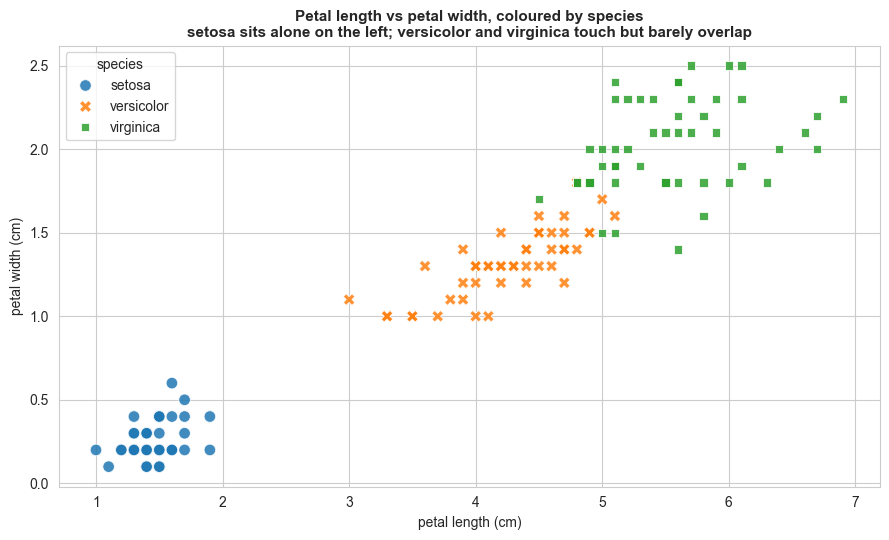

   ✅ Longer petals go with wider petals - the cloud runs bottom-left to top-right.
   📝 hue='species' shows the classes separate: the longest setosa petal is 1.9 cm, the shortest of the other two is 3.0 cm - a real gap.
   📝 A gap like that is the reason a classifier can work at all on this data.

   🔹 Distribution Plot (VERY COMMON for Data Exploration!):
   ⏰ WHEN to use: BEFORE ML - understand data distribution, check for normality
   💡 WHY use: many models assume roughly bell-shaped data - check before you assume
   # sns.histplot(data=df, x='petal length (cm)', kde=True)  # kde adds density curve


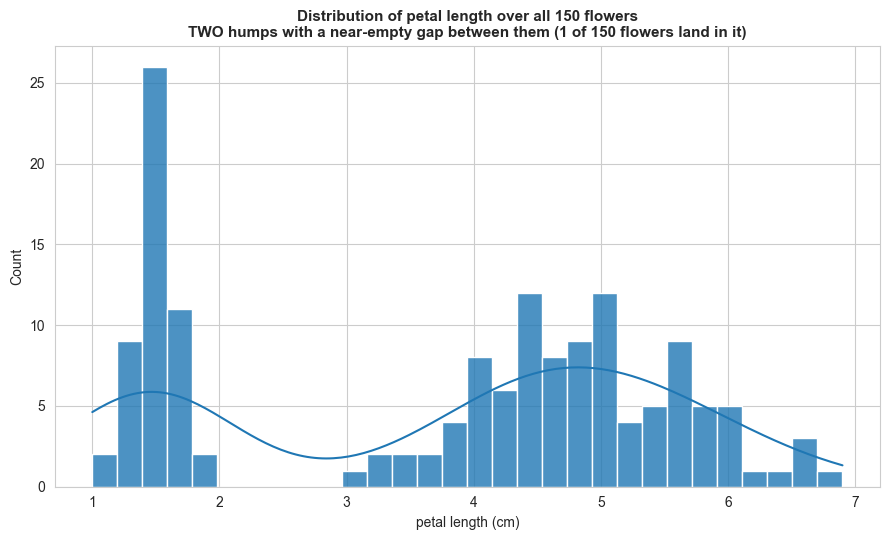

   ✅ Two clear humps, separated by a stretch from 2 cm to 3 cm holding 1 of the 150 flowers.
   📝 The left hump is setosa; the right hump is versicolor and virginica together.
   📝 This is why you plot BEFORE you model. The mean of this column is 3.76 cm, which sits in the thin valley between the humps:
      11 flowers lie within a quarter-centimetre of it, against 44 around the left hump.
      A mean and a standard deviation would report a 'typical' flower that is really
      the midpoint of two groups, and typical of neither.

   🔹 Box Plot (COMMON for Comparing Groups!):
   ⏰ WHEN to use: Compare distributions across categories, find outliers per group
   💡 WHY use: See if categories really differ - informs feature engineering
   # sns.boxplot(data=df, x='species', y='petal length (cm)')


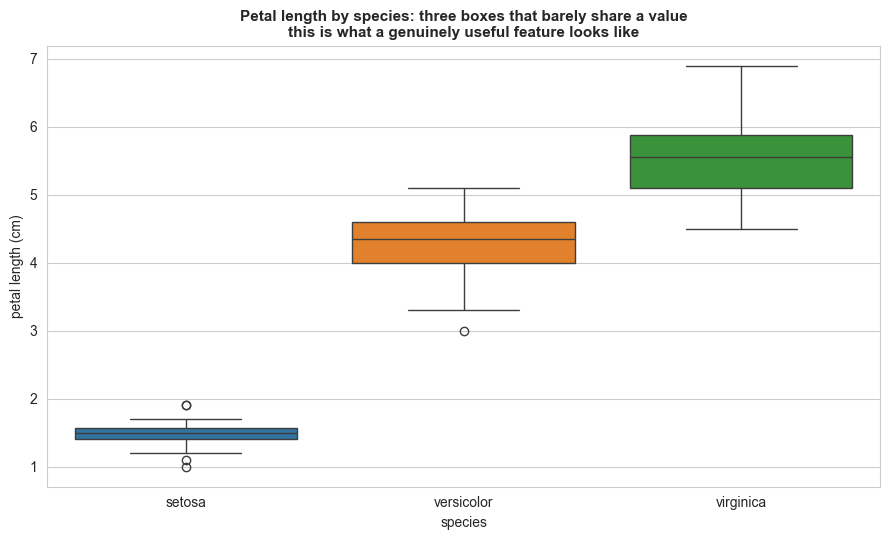

   ✅ Median petal length per species: setosa 1.5 cm, versicolor 4.35 cm, virginica 5.55 cm
   📝 The setosa box does not overlap the other two AT ALL. Compare that with what
      sepal width would look like - there the three boxes sit on top of each other.

   🔹 Heatmap (VERY COMMON for Correlations!):
   ⏰ WHEN to use: BEFORE ML - find correlated features, check multicollinearity
   💡 WHY use: Two features that say the same thing add cost, not information!
   # correlation = df[numeric_columns].corr()
   # sns.heatmap(correlation, annot=True, cmap='coolwarm')


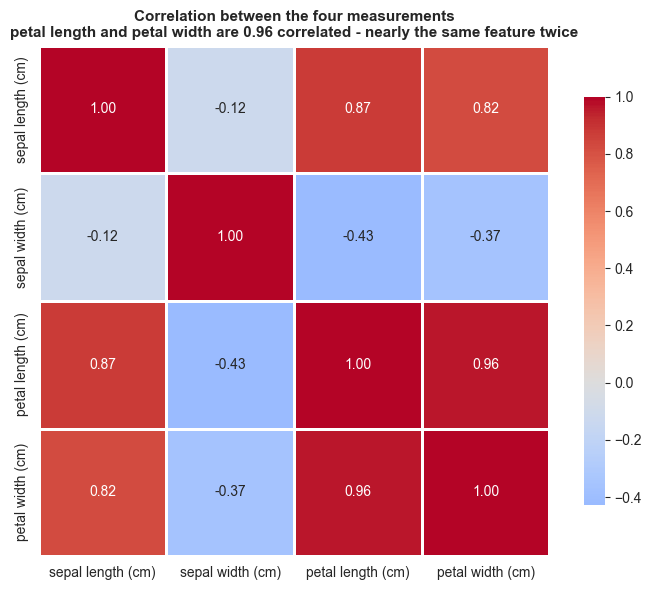

   ✅ Deep red = strong positive, deep blue = strong negative, pale = unrelated.
   📝 Strongest off-diagonal correlation here: 0.96 (petal length vs petal width).
   📝 The usual rule of thumb - drop one of any pair above 0.9 - would drop one of
      those two petal columns. Sepal width is the opposite case: it is the only column
      NEGATIVELY correlated with the rest, so it is the one that duplicates nothing.
      Careful: this chart measures REDUNDANCY, not usefulness. It tells you which
      columns repeat each other, never which one predicts the species best.

   🔹 Pair Plot (COMMON for Exploring All Relationships!):
   # sns.pairplot(data, hue='species')  # all 4x4 pairwise scatter plots at once
   # Skipped here only because it draws 16 panels and costs a few seconds.

🔗 HOW THIS HELPS IN AI:
   • Data exploration: Visualize distributions, correlations before ML
   • Beautiful plots: Professional-looking visualizations for presentations
   • Statistical analysis: Easy correla

In [21]:
# Seaborn: Beautiful Statistical Visualizations
# WHAT the data is: the iris flower measurements collected by Edgar Anderson and published by
#   R. A. Fisher in 1936 - 150 real flowers, four real measurements each, three real species.
#   It ships inside scikit-learn, so there is nothing to download.
# WHY real measurements and not np.random: every sentence below claims something about the
#   picture - "the categories separate", "the features are correlated". On invented random
#   numbers those sentences would be false and the plots would quietly contradict the text.
#   On real flowers they are true, and you can check each one with your own eyes.

try:
    import seaborn as sns  # Import Seaborn (standard: use 'sns' as alias)
    import matplotlib.pyplot as plt
    import pandas as pd
    from sklearn.datasets import load_iris  # 150 real flower measurements, bundled with sklearn
    HAS_SEABORN = True
except ImportError:
    HAS_SEABORN = False
    print("⚠️  Seaborn not installed. Install with: pip install seaborn matplotlib pandas scikit-learn")

if HAS_SEABORN:
    print("=" * 70)
    print("✅ AFTER: Seaborn (Beautiful Statistical Visualizations)")
    print("=" * 70)
    print()

    # Set style (beautiful default!)
    sns.set_style("whitegrid")  # Beautiful grid style

    # 1. Load REAL data (Fisher's iris measurements, 1936 - bundled, no download needed)
    iris = load_iris(as_frame=True)  # as_frame=True hands us a pandas DataFrame directly
    data = iris.frame.copy()  # 150 rows x 4 measurements + the species code
    data['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)  # readable labels
    FEATURES = list(iris.feature_names)  # the four numeric columns, in centimetres

    print(f"📊 Data: {len(data)} real flowers, {len(FEATURES)} measurements each, "
          f"{data['species'].nunique()} species")
    print(f"   Columns: {FEATURES}")
    print("   Species counts: "
          + ", ".join(f"{name} {int(n)}" for name, n in data['species'].value_counts().items()))
    print()

    print("📊 MOST FREQUENTLY USED SEABORN PLOTS (What AI Engineers Use!)")
    print()

    # 1. Scatter plot with categories (MOST COMMON!)
    print("   🔹 Scatter Plot (MOST COMMON for exploring relationships!):")
    print("   ⏰ WHEN to use: Explore relationships between two numeric variables, check for patterns")
    print("   💡 WHY use: BEFORE ML - see if features are related, and whether the classes separate")
    print("   # sns.scatterplot(data=df, x='petal length (cm)', y='petal width (cm)', hue='species')")
    plt.figure(figsize=(9, 5.5))
    sns.scatterplot(data=data, x='petal length (cm)', y='petal width (cm)',
                    hue='species', style='species', s=70, alpha=0.85)
    plt.title('Petal length vs petal width, coloured by species\n'
              'setosa sits alone on the left; versicolor and virginica touch but barely overlap',
              fontweight='bold', fontsize=11)
    plt.tight_layout()
    plt.show()
    setosa_max = data.loc[data['species'] == 'setosa', 'petal length (cm)'].max()
    others_min = data.loc[data['species'] != 'setosa', 'petal length (cm)'].min()
    print(f"   ✅ Longer petals go with wider petals - the cloud runs bottom-left to top-right.")
    print(f"   📝 hue='species' shows the classes separate: the longest setosa petal is "
          f"{setosa_max} cm, the shortest of the other two is {others_min} cm - a real gap.")
    print("   📝 A gap like that is the reason a classifier can work at all on this data.")
    print()

    # 2. Distribution plot (VERY COMMON for data exploration!)
    print("   🔹 Distribution Plot (VERY COMMON for Data Exploration!):")
    print("   ⏰ WHEN to use: BEFORE ML - understand data distribution, check for normality")
    print("   💡 WHY use: many models assume roughly bell-shaped data - check before you assume")
    print("   # sns.histplot(data=df, x='petal length (cm)', kde=True)  # kde adds density curve")
    plt.figure(figsize=(9, 5.5))
    sns.histplot(data=data, x='petal length (cm)', bins=30, kde=True, alpha=0.8)
    petal = data['petal length (cm)']
    in_gap = int(((petal >= 2) & (petal <= 3)).sum())          # flowers between the two humps
    mean_pl = petal.mean()
    near_mean = int(((petal > mean_pl - .25) & (petal < mean_pl + .25)).sum())
    near_left = int(((petal > 1.25) & (petal < 1.75)).sum())   # around the left hump's peak
    plt.title('Distribution of petal length over all 150 flowers\n'
              f'TWO humps with a near-empty gap between them ({in_gap} of 150 flowers land in it)',
              fontweight='bold', fontsize=11)
    plt.tight_layout()
    plt.show()
    print(f"   ✅ Two clear humps, separated by a stretch from 2 cm to 3 cm holding {in_gap} "
          f"of the {len(petal)} flowers.")
    print("   📝 The left hump is setosa; the right hump is versicolor and virginica together.")
    print("   📝 This is why you plot BEFORE you model. The mean of this column is "
          f"{mean_pl:.2f} cm, which sits in the thin valley between the humps:")
    print(f"      {near_mean} flowers lie within a quarter-centimetre of it, against {near_left} "
          "around the left hump.")
    print("      A mean and a standard deviation would report a 'typical' flower that is really")
    print("      the midpoint of two groups, and typical of neither.")
    print()

    # 3. Box plot (COMMON for comparing groups!)
    print("   🔹 Box Plot (COMMON for Comparing Groups!):")
    print("   ⏰ WHEN to use: Compare distributions across categories, find outliers per group")
    print("   💡 WHY use: See if categories really differ - informs feature engineering")
    print("   # sns.boxplot(data=df, x='species', y='petal length (cm)')")
    plt.figure(figsize=(9, 5.5))
    sns.boxplot(data=data, x='species', y='petal length (cm)', hue='species', legend=False)
    plt.title('Petal length by species: three boxes that barely share a value\n'
              'this is what a genuinely useful feature looks like',
              fontweight='bold', fontsize=11)
    plt.tight_layout()
    plt.show()
    medians = data.groupby('species', observed=True)['petal length (cm)'].median()
    print("   ✅ Median petal length per species: " +
          ", ".join(f"{name} {value} cm" for name, value in medians.items()))
    print("   📝 The setosa box does not overlap the other two AT ALL. Compare that with what")
    print("      sepal width would look like - there the three boxes sit on top of each other.")
    print()

    # 4. Heatmap (VERY COMMON for correlations!)
    print("   🔹 Heatmap (VERY COMMON for Correlations!):")
    print("   ⏰ WHEN to use: BEFORE ML - find correlated features, check multicollinearity")
    print("   💡 WHY use: Two features that say the same thing add cost, not information!")
    correlation = data[FEATURES].corr()
    print("   # correlation = df[numeric_columns].corr()")
    print("   # sns.heatmap(correlation, annot=True, cmap='coolwarm')")
    plt.figure(figsize=(7.5, 6))
    sns.heatmap(correlation, annot=True, fmt=".2f", cmap='coolwarm', center=0,
                square=True, linewidths=1, cbar_kws={"shrink": 0.8})
    plt.title('Correlation between the four measurements\n'
              'petal length and petal width are 0.96 correlated - nearly the same feature twice',
              fontweight='bold', fontsize=11)
    plt.tight_layout()
    plt.show()
    # Ignore the diagonal (a column is always perfectly correlated with itself) and take the
    # largest remaining absolute correlation - that is the pair most at risk of being redundant.
    off_diagonal = correlation.abs().where(correlation.abs() < 0.999)
    strongest = off_diagonal.max().max()
    print(f"   ✅ Deep red = strong positive, deep blue = strong negative, pale = unrelated.")
    print(f"   📝 Strongest off-diagonal correlation here: {strongest:.2f} "
          f"(petal length vs petal width).")
    print("   📝 The usual rule of thumb - drop one of any pair above 0.9 - would drop one of")
    print("      those two petal columns. Sepal width is the opposite case: it is the only column")
    print("      NEGATIVELY correlated with the rest, so it is the one that duplicates nothing.")
    print("      Careful: this chart measures REDUNDANCY, not usefulness. It tells you which")
    print("      columns repeat each other, never which one predicts the species best.")
    print()

    # 5. Pair plot (COMMON for exploring all relationships!)
    print("   🔹 Pair Plot (COMMON for Exploring All Relationships!):")
    print("   # sns.pairplot(data, hue='species')  # all 4x4 pairwise scatter plots at once")
    print("   # Skipped here only because it draws 16 panels and costs a few seconds.")
    print()

    print("🔗 HOW THIS HELPS IN AI:")
    print("   • Data exploration: Visualize distributions, correlations before ML")
    print("   • Beautiful plots: Professional-looking visualizations for presentations")
    print("   • Statistical analysis: Easy correlation, distribution analysis")
    print("   • Model evaluation: Visualize model performance, feature importance")
    print()
    print("📊 BEFORE vs AFTER:")
    print("   BEFORE: Matplotlib → Lots of code for statistical plots")
    print("   AFTER: Seaborn → Beautiful plots with just a few lines!")
    print()
    print("💡 AI engineers use Seaborn for data exploration before modeling!")
else:
    print("⚠️  Please install Seaborn to see examples")
    print("   Run: pip install seaborn matplotlib pandas scikit-learn")

### 🔎 Read the four figures

**Scatter — the classes separate.** Petal length runs left to right, petal width bottom to top, and the cloud climbs from bottom-left to top-right: long petals are also wide petals. Now look at the colours. *setosa* sits in its own corner with a visible empty strip between it and everything else. *versicolor* and *virginica* touch along a diagonal but hardly overlap. That gap is the whole reason a classifier can work on this data at all.

**Histogram — not everything is a bell curve.** Two humps, with a near-empty stretch between 2 cm and 3 cm: exactly **one** of the 150 flowers falls in it, as the title counts. The left hump is *setosa*; the right one is the other two species piled together. Read the consequence: the mean of this column is **3.76 cm**, which lands in the thin valley between the humps. Only 11 flowers lie within a quarter-centimetre of that mean, against 44 clustered around the left hump — so the "average flower" this column reports is the midpoint of two groups and typical of neither. That is what you would have missed by reading `df.describe()` and never drawing the picture.

**Box plot — what a useful feature looks like.** Three boxes, and the *setosa* box does not touch the other two. A feature that splits the classes this cleanly is worth more than any amount of model tuning. Compare it in your head with a feature where all three boxes sit on top of each other: that feature tells the model nothing, and no algorithm can rescue it.

**Heatmap — two columns saying one thing.** The deep red off-diagonal square is petal length against petal width at **0.96**. Those two columns are very nearly the same measurement written twice, and the standard rule of thumb (drop one of any pair above 0.9) would remove one of them. Sepal width is the opposite case: it is the only *blue* row, negatively correlated with everything else, so it is the one column that duplicates nothing and is therefore the one you would keep. One caution: this chart measures **redundancy between features**, never how well a feature predicts the label. Two columns can both be useless and perfectly correlated; the heatmap cannot tell you that.

**Why this dataset and not random numbers.** Every sentence above is a claim about the picture. Drawn on `np.random.randn`, the same four plots would show no clusters, one smooth hump, three identical boxes and a correlation near zero — and the text would be describing something that is not on the screen. These are Edgar Anderson's 1936 measurements of real irises, so the claims and the pixels agree.

## ✍️ Your turn: pandas on the real flowers

Part 10 showed `groupby` on four invented people. The Seaborn cell above loaded 150 **real** irises into a DataFrame called `data`. Use the same `groupby` on it — and commit to a prediction before you run anything.


In [22]:
# ✍️ YOUR TURN - fill the two None values, then run the CHECK cell below.
# The box plot above compared petal LENGTH across the three species. Petal WIDTH is the other petal column.

# 1. PREDICT: which species has the WIDEST petals on average?  ('setosa', 'versicolor' or 'virginica')
predicted_widest_species = None

# 2. COMPUTE the mean petal width per species. Part 10's pattern was:
#        df.groupby('Department')['Salary'].mean()
#    Here the DataFrame is `data`, the category column is 'species', and the number column is 'petal width (cm)'.
#    (observed=True only silences a pandas warning about categorical columns.)
mean_petal_width_by_species = None     # data.groupby('species', observed=True)['...'].mean()


In [23]:
# ✅ CHECK - run this after filling the stub above. It prints feedback and never raises.
_expected = {'setosa': 0.246, 'versicolor': 1.326, 'virginica': 2.026}   # cm, from Anderson's 150 flowers
if 'data' not in globals():
    print("Run the Seaborn cell above first - it loads the `data` DataFrame this task uses.")
elif predicted_widest_species is None and mean_petal_width_by_species is None:
    print("Not attempted yet - fill the two None values in the cell above, then re-run this cell.")
else:
    if mean_petal_width_by_species is None:
        print("Prediction noted. Now compute the table - the groupby line is sketched in the comment above.")
    else:
        try:
            _same = all(abs(float(mean_petal_width_by_species[s]) - v) < 1e-3 for s, v in _expected.items())
        except Exception:
            _same = False
        if _same:
            print("matches - your table is the real mean petal width per species:")
            print(mean_petal_width_by_species.round(3).to_string())
        else:
            print("not yet - hint: group by 'species' and take the mean of 'petal width (cm)' (exact spelling, with the unit).")
    if predicted_widest_species is not None:
        if str(predicted_widest_species).strip().lower() == max(_expected, key=_expected.get):
            print(f"Prediction '{predicted_widest_species}': matches the data.")
        else:
            print(f"Prediction '{predicted_widest_species}': the data disagrees - look at the top-right corner of the "
                  "scatter plot above, where the widest petals sit, and at which species is drawn there.")


Not attempted yet - fill the two None values in the cell above, then re-run this cell.


## Part 12: JSON - Data Formats

### 📚 What is JSON?
JSON = **J**ava**S**cript **O**bject **N**otation - standard format for exchanging data!

**THE PROBLEM**: Need to save/load data, exchange data between systems, store configuration.
**THE SOLUTION**: JSON provides easy data serialization - convert Python objects to/from JSON!

**Why JSON for AI?**
- Save/load ML models (model configuration)
- Exchange data with APIs (get data from web services)
- Store data in files (datasets, configurations)
- Essential for real-world AI applications!

In [24]:
# JSON: Data Formats (Built-in Library)

import json  # Built-in library (no installation needed!)

print("=" * 70)
print("✅ JSON: Most Frequently Used Operations (What AI Engineers Use!)")
print("=" * 70)
print()

# MOST FREQUENTLY USED JSON OPERATIONS
print("📊 MOST FREQUENTLY USED JSON OPERATIONS:")
print()

# 1. Converting Python objects to JSON (MOST COMMON!)
print("   🔹 Converting Python to JSON (MOST COMMON!):")
print("   ⏰ WHEN to use: Save ML model configs, send data to APIs, store configurations")
print("   💡 WHY use: JSON is standard format - works with APIs, web services, config files")
data = {
    "model_name": "LinearRegression",
    "accuracy": 0.95,
    "features": ["age", "salary", "education"],
    "trained": True,
    "hyperparameters": {"learning_rate": 0.01, "epochs": 100}
}

print("   # Python dict:")
print(f"   data = {data}")
print()
json_string = json.dumps(data, indent=2)  # Convert dict to JSON string
print("   # Convert to JSON: json_string = json.dumps(data, indent=2)")
print("   📝 indent=2 makes JSON readable (adds indentation)")
print("   JSON string:")
print(json_string)
print()

# 2. Converting JSON to Python (VERY COMMON!)
print("   🔹 Converting JSON to Python (VERY COMMON!):")
print("   ⏰ WHEN to use: Load configs, receive data from APIs, parse JSON responses")
print("   💡 WHY use: APIs return JSON - convert to Python dict to use in code")
loaded_data = json.loads(json_string)  # Convert JSON string back to dict
print("   # Load from JSON: loaded_data = json.loads(json_string)")
print(f"   Loaded: {loaded_data}")
print(f"   Type: {type(loaded_data)} (Python dict - ready to use!)")
print()

# 3. Saving to file (COMMON for configurations!)
print("   🔹 Saving to File (COMMON for Configurations!):")
print("   ⏰ WHEN to use: Save ML model configs, store hyperparameters, export settings")
print("   💡 WHY use: Don't retype configs - save once, load anytime!")
print("   # Save ML model config:")
print("   # with open('model_config.json', 'w') as f:")
print("   #     json.dump(data, f, indent=2)  # indent=2 makes it readable")
print("   # Creates: model_config.json file")
print("   📝 Use json.dump() for files, json.dumps() for strings")
print()

# 4. Loading from file (VERY COMMON!)
print("   🔹 Loading from File (VERY COMMON!):")
print("   ⏰ WHEN to use: Load saved configs, restore model settings, import parameters")
print("   💡 WHY use: Reproduce experiments - load exact same config used before!")
print("   # Load ML model config:")
print("   # with open('model_config.json', 'r') as f:")
print("   #     config = json.load(f)")
print("   # Returns: Python dict with configuration")
print("   📝 Use json.load() for files, json.loads() for strings")
print()

# 5. Pretty printing JSON (COMMON for debugging!)
print("   🔹 Pretty Printing JSON (COMMON for Debugging!):")
print("   # Pretty print: json.dumps(data, indent=2, sort_keys=True)")
pretty_json = json.dumps(data, indent=2, sort_keys=True)
print(pretty_json)
print()

# 6. Handling errors (ESSENTIAL for real code!)
print("   🔹 Handling Errors (ESSENTIAL for Real Code!):")
print("   # Try/except for invalid JSON:")
print("   # try:")
print("   #     data = json.loads(invalid_json_string)")
print("   # except json.JSONDecodeError as e:")
print("   #     print(f'Invalid JSON: {e}')")
print()

print("🔗 HOW THIS HELPS IN AI:")
print("   • Save ML models: Store model configuration, hyperparameters")
print("   • API communication: Exchange data with web services")
print("   • Data storage: Save datasets, results, configurations")
print("   • Configuration files: Store settings for AI systems")
print()
print("📊 BEFORE vs AFTER:")
print("   BEFORE: Hard to save/load data, exchange with other systems")
print("   AFTER: JSON → Easy data serialization, standard format!")
print()
print("💡 AI engineers use JSON EVERY DAY for saving models, configurations, API data!")


✅ JSON: Most Frequently Used Operations (What AI Engineers Use!)

📊 MOST FREQUENTLY USED JSON OPERATIONS:

   🔹 Converting Python to JSON (MOST COMMON!):
   ⏰ WHEN to use: Save ML model configs, send data to APIs, store configurations
   💡 WHY use: JSON is standard format - works with APIs, web services, config files
   # Python dict:
   data = {'model_name': 'LinearRegression', 'accuracy': 0.95, 'features': ['age', 'salary', 'education'], 'trained': True, 'hyperparameters': {'learning_rate': 0.01, 'epochs': 100}}

   # Convert to JSON: json_string = json.dumps(data, indent=2)
   📝 indent=2 makes JSON readable (adds indentation)
   JSON string:
{
  "model_name": "LinearRegression",
  "accuracy": 0.95,
  "features": [
    "age",
    "salary",
    "education"
  ],
  "trained": true,
  "hyperparameters": {
    "learning_rate": 0.01,
    "epochs": 100
  }
}

   🔹 Converting JSON to Python (VERY COMMON!):
   ⏰ WHEN to use: Load configs, receive data from APIs, parse JSON responses
   💡 WHY 

## Part 13: TensorFlow/Keras - Deep Learning

### 📚 What are TensorFlow and Keras?
TensorFlow = Google's deep learning framework
Keras = High-level API for TensorFlow (makes deep learning EASY!)

**THE PROBLEM**: Building neural networks from scratch is very difficult.
**THE SOLUTION**: Keras provides simple API - build neural networks with just a few lines!

**Why TensorFlow/Keras for AI?**
- Deep learning (neural networks with many layers)
- Image recognition, natural language processing
- Industry standard - used by Google, Netflix, Uber
- Essential for modern AI applications!

In [25]:
# TensorFlow/Keras: Deep Learning Made Easy

try:
    import tensorflow as tf
    from tensorflow import keras
    import numpy as np
    HAS_TENSORFLOW = True
except ImportError:
    HAS_TENSORFLOW = False
    print("⚠️  TensorFlow not installed. Install with: pip install tensorflow")
    print("   Note: TensorFlow is optional for this course, but essential for deep learning!")

if HAS_TENSORFLOW:
    print("=" * 70)
    print("✅ AFTER: TensorFlow/Keras (Deep Learning Made Easy)")
    print("=" * 70)
    print()
    
    # MOST FREQUENTLY USED TENSORFLOW/KERAS OPERATIONS (What AI Engineers Use!)
    print("📊 MOST FREQUENTLY USED TENSORFLOW/KERAS OPERATIONS:")
    print()
    
    # 1. Creating neural network (MOST COMMON!)
    print("   🔹 Creating Neural Network (MOST COMMON!):")
    print("   ⏰ WHEN to use: Deep learning projects (image recognition, NLP, complex patterns)")
    print("   💡 WHY use: Neural networks learn complex patterns - better than traditional ML for images/text")
    print("   # Sequential model (most common - layers in order):")
    model = keras.Sequential([
        keras.layers.Dense(64, activation='relu', input_shape=(2,)),  # Hidden layer 1: 64 neurons, ReLU activation
        keras.layers.Dense(32, activation='relu'),  # Hidden layer 2: 32 neurons, ReLU activation
        keras.layers.Dense(1, activation='sigmoid')  # Output layer: 1 neuron, sigmoid (for binary classification)
    ])
    print("   model = keras.Sequential([")
    print("       keras.layers.Dense(64, activation='relu', input_shape=(2,)),  # Hidden layer 1")
    print("       keras.layers.Dense(32, activation='relu'),  # Hidden layer 2")
    print("       keras.layers.Dense(1, activation='sigmoid')  # Output layer")
    print("   ])")
    print(f"   ✅ Created {len(model.layers)}-layer neural network!")
    print("   📝 Start with more neurons, reduce gradually (e.g., 64→32→1)")
    print()
    
    # Show model summary
    print("   # See model structure: model.summary()  (shows all layers and parameters)")
    print("   Model layers:", [layer.name for layer in model.layers])
    print()
    
    # 2. Compiling model (ALWAYS NEEDED!)
    print("   🔹 Compiling Model (ALWAYS NEEDED!):")
    print("   ⏰ WHEN to use: ALWAYS after creating model, before training")
    print("   💡 WHY use: Configures how model learns - optimizer, loss function, metrics to track")
    model.compile(
        optimizer='adam',  # Most common optimizer - adaptive learning rate
        loss='binary_crossentropy',  # Loss function - for binary classification
        metrics=['accuracy']  # Metrics to track during training
    )
    print("   model.compile(")
    print("       optimizer='adam',  # Adaptive learning rate (most common!)")
    print("       loss='binary_crossentropy',  # For binary classification (0 or 1)")
    print("       metrics=['accuracy']  # Track accuracy during training")
    print("   )")
    print("   ✅ Model compiled!")
    print("   📝 Other optimizers: 'sgd', 'rmsprop'. Other losses: 'mse' (regression), 'categorical_crossentropy' (multi-class)")
    print()
    
    # 3. Preparing data (VERY COMMON!)
    print("   🔹 Preparing Data (VERY COMMON!):")
    print("   ⏰ WHEN to use: BEFORE training - prepare data in correct format")
    print("   💡 WHY use: Neural networks need NumPy arrays, correct shapes, float32 type for efficiency")
    np.random.seed(42)  # Set random seed for reproducibility
    X_train = np.random.rand(100, 2).astype(np.float32)  # Training features: 100 samples, 2 features, float32 type
    y_train = (X_train[:, 0] + X_train[:, 1] > 1).astype(np.float32)  # Training labels: simple rule for binary classification
    X_test = np.random.rand(20, 2).astype(np.float32)  # Test features: 20 samples for validation
    y_test = (X_test[:, 0] + X_test[:, 1] > 1).astype(np.float32)  # Test labels: for validation
    
    print(f"   X_train shape: {X_train.shape}  # (samples, features) - shape must match input_shape")
    print(f"   y_train shape: {y_train.shape}  # (samples,) - labels for training")
    print(f"   X_test shape: {X_test.shape}  # Test data for validation")
    print("   📝 Always use .astype(np.float32) - faster than float64, standard for deep learning")
    print()
    
    # 4. Training model (CORE OPERATION!)
    print("   🔹 Training Model (CORE OPERATION!):")
    print("   ⏰ WHEN to use: After compiling model - train on your data")
    print("   💡 WHY use: This is where model LEARNS - adjusts weights to minimize loss")
    print("   # Train model:")
    print("   history = model.fit(")
    print("       X_train, y_train,  # Training data and labels")
    print("       epochs=10,  # Number of training rounds (more epochs = more learning, but slower)")
    print("       batch_size=32,  # Samples per batch (32 is standard - balance speed and memory)")
    print("       validation_data=(X_test, y_test),  # Validate on test set (check if overfitting)")
    print("       verbose=1  # Show progress (1=progress bar, 0=silent)")
    print("   )")
    print("   ✅ Model training (commented for speed)")
    print("   📝 Monitor validation loss - if it increases while training loss decreases = overfitting!")
    print()
    
    # 5. Making predictions (VERY COMMON!)
    print("   🔹 Making Predictions (VERY COMMON!):")
    print("   ⏰ WHEN to use: After training - predict on new, unseen data")
    print("   💡 WHY use: Use trained model to make predictions on real data")
    X_new = np.array([[0.5, 0.5], [0.8, 0.8]], dtype=np.float32)  # New data to predict
    # predictions = model.predict(X_new)  # Make predictions (commented - model not trained)
    print("   # Predict on new data:")
    print(f"   X_new = {X_new.tolist()}")
    print("   predictions = model.predict(X_new)")
    print("   # Returns: Probability for each sample (0-1 for binary classification)")
    print("   📝 For binary classification: >0.5 = class 1, <0.5 = class 0")
    print()
    
    # 6. Evaluating model (COMMON!)
    print("   🔹 Evaluating Model (COMMON!):")
    print("   ⏰ WHEN to use: After training - check model performance on test set")
    print("   💡 WHY use: Measure how well model generalizes to unseen data (avoid overfitting)")
    print("   # Evaluate on test set:")
    print("   loss, accuracy = model.evaluate(X_test, y_test, verbose=0)")
    print("   print(f'Test accuracy: {accuracy:.2f}')  # Shows final accuracy")
    print("   📝 Test accuracy < training accuracy = normal (some overfitting expected)")
    print("   📝 Test accuracy << training accuracy = overfitting (model memorized training data)")
    print()
    
    print("🔗 HOW THIS HELPS IN AI:")
    print("   • Deep learning: Build neural networks with many layers")
    print("   • Image recognition: Classify images (cats, dogs, objects)")
    print("   • Natural language: Process text, language translation")
    print("   • Industry standard: Used by Google, Netflix, Uber, many others")
    print()
    print("📊 BEFORE vs AFTER:")
    print("   BEFORE: Build neural networks from scratch → Very difficult, time-consuming")
    print("   AFTER: Keras → Build neural networks with just a few lines!")
    print()
    print("💡 This is what AI engineers use for deep learning - image recognition, NLP, and more!")
    print("   (Optional for this course, but essential for advanced AI!)")
else:
    print("⚠️  TensorFlow is optional for this course")
    print("   It's used for deep learning - advanced topic")
    print("   Install with: pip install tensorflow")
    print("   Note: TensorFlow requires more resources - install only if needed!")


⚠️  TensorFlow not installed. Install with: pip install tensorflow
   Note: TensorFlow is optional for this course, but essential for deep learning!
⚠️  TensorFlow is optional for this course
   It's used for deep learning - advanced topic
   Install with: pip install tensorflow
   Note: TensorFlow requires more resources - install only if needed!


## Part 14: PyTorch - Deep Learning (Alternative)

### 📚 What is PyTorch?
PyTorch = Facebook's deep learning framework - dynamic, flexible, popular in research!

**THE PROBLEM**: Need flexible deep learning framework for research and experimentation.
**THE SOLUTION**: PyTorch provides dynamic computation graphs - change network during training!

**Why PyTorch for AI?**
- Popular in research (academic papers use PyTorch)
- Dynamic computation (more flexible than TensorFlow)
- Used by Facebook, Twitter, many research labs
- Great for experimentation and prototyping

In [26]:
# PyTorch: Deep Learning (Alternative Framework)

try:
    import torch
    import torch.nn as nn
    import numpy as np
    HAS_PYTORCH = True
except ImportError:
    HAS_PYTORCH = False
    print("⚠️  PyTorch not installed. Install with: pip install torch")
    print("   Note: PyTorch is optional for this course, but essential for deep learning research!")

if HAS_PYTORCH:
    print("=" * 70)
    print("✅ AFTER: PyTorch (Deep Learning for Research)")
    print("=" * 70)
    print()
    
    print("📊 Step 1: Create Neural Network Class")
    print()
    
    # Define neural network
    class SimpleNN(nn.Module):
        """Simple neural network in PyTorch"""
        def __init__(self):
            super(SimpleNN, self).__init__()
            self.fc1 = nn.Linear(2, 4)  # Input: 2 features, Output: 4 neurons
            self.fc2 = nn.Linear(4, 1)  # Input: 4 neurons, Output: 1 neuron
            self.relu = nn.ReLU()  # Activation function
            self.sigmoid = nn.Sigmoid()  # Output activation
        
        def forward(self, x):
            """Forward pass: how data flows through network"""
            x = self.relu(self.fc1(x))  # Hidden layer
            x = self.sigmoid(self.fc2(x))  # Output layer
            return x
    
    model = SimpleNN()
    print("   ✅ Created neural network class!")
    print(f"   Model: {model}")
    print()
    
    print("📊 Step 2: Prepare Data")
    print()
    
    # Create sample data
    X = torch.tensor([[0.5, 0.5], [0.8, 0.8]], dtype=torch.float32)
    print(f"   Input data: {X}")
    print(f"   Shape: {X.shape}")
    print()
    
    print("📊 Step 3: Forward Pass (Make Predictions)")
    print()
    
    with torch.no_grad():  # Don't calculate gradients (just prediction)
        output = model(X)
    
    print(f"   Output (predictions): {output}")
    print()
    
    print("📊 Step 4: Training (Would Train Here)")
    print()
    print("   • criterion = nn.BCELoss()  # Loss function")
    print("   • optimizer = torch.optim.Adam(model.parameters())  # Optimizer")
    print("   • for epoch in range(10):  # Training loop")
    print("   •     output = model(X_train)")
    print("   •     loss = criterion(output, y_train)")
    print("   •     optimizer.zero_grad()  # Reset gradients")
    print("   •     loss.backward()  # Calculate gradients")
    print("   •     optimizer.step()  # Update weights")
    print("   ✅ Model would train here (commented for speed)")
    print()
    
    print("🔗 HOW THIS HELPS IN AI:")
    print("   • Research: Popular in academic research, many papers use PyTorch")
    print("   • Flexibility: Dynamic computation graphs (change network during training)")
    print("   • Experimentation: Easy to modify and test different architectures")
    print("   • Industry: Used by Facebook, Twitter, research labs")
    print()
    print("📊 BEFORE vs AFTER:")
    print("   BEFORE: Need flexible framework → Hard to experiment")
    print("   AFTER: PyTorch → Dynamic graphs, easy experimentation!")
    print()
    print("💡 AI engineers use PyTorch for research and experimentation!")
    print("   (Optional for this course, but essential for deep learning research!)")
    print()
    print("🔗 TensorFlow vs PyTorch:")
    print("   • TensorFlow: More production-ready, used by Google")
    print("   • PyTorch: More flexible, popular in research")
    print("   • Both are powerful - choice depends on project needs!")
else:
    print("⚠️  PyTorch is optional for this course")
    print("   It's used for deep learning - advanced topic")
    print("   Install with: pip install torch")
    print("   Note: PyTorch requires more resources - install only if needed!")


✅ AFTER: PyTorch (Deep Learning for Research)

📊 Step 1: Create Neural Network Class

   ✅ Created neural network class!
   Model: SimpleNN(
  (fc1): Linear(in_features=2, out_features=4, bias=True)
  (fc2): Linear(in_features=4, out_features=1, bias=True)
  (relu): ReLU()
  (sigmoid): Sigmoid()
)

📊 Step 2: Prepare Data

   Input data: tensor([[0.5000, 0.5000],
        [0.8000, 0.8000]])
   Shape: torch.Size([2, 2])

📊 Step 3: Forward Pass (Make Predictions)

   Output (predictions): tensor([[0.6577],
        [0.6736]])

📊 Step 4: Training (Would Train Here)

   • criterion = nn.BCELoss()  # Loss function
   • optimizer = torch.optim.Adam(model.parameters())  # Optimizer
   • for epoch in range(10):  # Training loop
   •     output = model(X_train)
   •     loss = criterion(output, y_train)
   •     optimizer.zero_grad()  # Reset gradients
   •     loss.backward()  # Calculate gradients
   •     optimizer.step()  # Update weights
   ✅ Model would train here (commented for speed)

🔗 HO

## Part 15: OpenCV - Computer Vision

### 📚 What is OpenCV?
OpenCV = **Open** **C**omputer **V**ision - library for image and video processing!

**THE PROBLEM**: Need to process images, detect objects, recognize faces, track motion.
**THE SOLUTION**: OpenCV provides powerful image processing tools - manipulate images easily!

**Why OpenCV for AI?**
- Image processing (resize, crop, filter, transform)
- Object detection (find objects in images)
- Face recognition (identify faces)
- Motion tracking (track moving objects)
- Essential for computer vision AI!

In [27]:
# OpenCV: Computer Vision Made Easy

try:
    import cv2  # Import OpenCV (standard: use 'cv2' as alias)
    import numpy as np
    import matplotlib.pyplot as plt
    HAS_OPENCV = True
except ImportError:
    HAS_OPENCV = False
    print("⚠️  OpenCV not installed. Install with: pip install opencv-python")
    print("   Note: OpenCV is optional for this course, but essential for computer vision!")

if HAS_OPENCV:
    print("=" * 70)
    print("✅ AFTER: OpenCV (Computer Vision Made Easy)")
    print("=" * 70)
    print()
    
    # MOST FREQUENTLY USED OPENCV OPERATIONS (What AI Engineers Use!)
    print("📊 MOST FREQUENTLY USED OPENCV OPERATIONS:")
    print()
    
    # 1. Creating/loading images
    print("   🔹 Loading/Creating Images (MOST COMMON!):")
    print("   ⏰ WHEN to use: Load images from files, create images programmatically")
    print("   💡 WHY use: Start point for all computer vision - need images in NumPy arrays")
    # Create sample image (instead of loading from file)
    # For demonstration - create simple image
    img = np.zeros((100, 100, 3), dtype=np.uint8)  # Black image: 100x100 pixels, 3 channels (RGB), uint8 (0-255)
    img[20:80, 20:80] = [255, 0, 0]  # Red square: set pixels from (20,20) to (80,80) to red (BGR format!)
    
    print(f"   # Create image: img = np.zeros((100, 100, 3), dtype=np.uint8)")
    print(f"   Image shape: {img.shape} (height, width, channels)")
    print(f"   Image type: {type(img)} (NumPy array)")
    print(f"   Image dtype: {img.dtype} (uint8 = 0-255 pixel values)")
    print("   📝 OpenCV uses BGR format (Blue-Green-Red), not RGB! Convert for Matplotlib display")
    print()
    
    # 2. Basic image operations
    print("   🔹 Basic Image Operations (VERY COMMON!):")
    print("   ⏰ WHEN to use: Preprocessing images before ML (resize, normalize, convert format)")
    print("   💡 WHY use: ML models need consistent image sizes, specific formats, normalized values")
    
    # Resize image
    resized = cv2.resize(img, (200, 200))  # Resize to 200x200 pixels
    print(f"   # Resize: cv2.resize(img, (width, height))")
    print(f"   • Resize: {img.shape} → {resized.shape}  (make all images same size for ML!)")
    print()
    
    # Convert to grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)  # Convert BGR to grayscale
    print(f"   # Grayscale: cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)")
    print(f"   • Grayscale: {img.shape} → {gray.shape}  (reduce channels from 3 to 1)")
    print("   📝 Grayscale = single channel - reduces data size, faster processing")
    print()
    
    # Apply Gaussian blur
    blurred = cv2.GaussianBlur(img, (15, 15), 0)  # Blur image with 15x15 kernel
    print(f"   # Blur: cv2.GaussianBlur(img, (kernel_size, kernel_size), 0)")
    print(f"   • Blur: Applied Gaussian blur  (remove noise, smooth image)")
    print("   📝 Blur removes noise - useful before edge detection")
    print()
    
    # 3. Image processing functions
    print("   🔹 Common Image Processing Functions:")
    print("   ⏰ WHEN to use: Load/save images, transform images, prepare for ML")
    print("   💡 WHY use: Essential operations for computer vision workflows")
    print("   # Load image: img = cv2.imread('image.jpg')  (MOST COMMON!)")
    print("   # Save image: cv2.imwrite('output.jpg', img)  (save processed image)")
    print("   # Resize: cv2.resize(img, (width, height))  (ML models need fixed size!)")
    print("   # Rotate: cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)  (data augmentation)")
    print("   # Crop: img[y1:y2, x1:x2]  (extract region of interest)")
    print("   # Convert color: cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  (for Matplotlib display)")
    print()
    
    # 4. Computer vision tasks
    print("   🔹 Computer Vision Tasks (Advanced!):")
    print("   ⏰ WHEN to use: Object detection, face recognition, motion tracking projects")
    print("   💡 WHY use: Pre-built algorithms for common CV tasks - save time vs coding from scratch")
    print("   # Face detection: face_cascade.detectMultiScale(gray)  (find faces in images)")
    print("   # Object detection: Use pre-trained models (YOLO, SSD)  (detect multiple objects)")
    print("   # Edge detection: cv2.Canny(img, threshold1, threshold2)  (find edges/contours)")
    print("   # Contours: cv2.findContours(img, mode, method)  (find object boundaries)")
    print("   # Motion tracking: cv2.calcOpticalFlowPyrLK()  (track moving objects)")
    print("   📝 OpenCV provides ready-made algorithms - don't reinvent the wheel!")
    print()
    
    print("🔗 HOW THIS HELPS IN AI:")
    print("   • Image preprocessing: Prepare images for ML models")
    print("   • Object detection: Find objects in images (cars, people, etc.)")
    print("   • Face recognition: Identify faces in photos")
    print("   • Video analysis: Process video frames, track motion")
    print("   • Robotics: Computer vision for robots to see")
    print()
    print("📊 BEFORE vs AFTER:")
    print("   BEFORE: Hard to process images → Complex, time-consuming")
    print("   AFTER: OpenCV → Easy image processing, powerful tools!")
    print()
    print("💡 AI engineers use OpenCV EVERY DAY for computer vision projects!")
    print("   (Optional for this course, but essential for computer vision AI!)")
else:
    print("⚠️  OpenCV is optional for this course")
    print("   It's used for computer vision - advanced topic")
    print("   Install with: pip install opencv-python")
    print("   Note: OpenCV requires more resources - install only if needed!")


✅ AFTER: OpenCV (Computer Vision Made Easy)

📊 MOST FREQUENTLY USED OPENCV OPERATIONS:

   🔹 Loading/Creating Images (MOST COMMON!):
   ⏰ WHEN to use: Load images from files, create images programmatically
   💡 WHY use: Start point for all computer vision - need images in NumPy arrays
   # Create image: img = np.zeros((100, 100, 3), dtype=np.uint8)
   Image shape: (100, 100, 3) (height, width, channels)
   Image type: <class 'numpy.ndarray'> (NumPy array)
   Image dtype: uint8 (uint8 = 0-255 pixel values)
   📝 OpenCV uses BGR format (Blue-Green-Red), not RGB! Convert for Matplotlib display

   🔹 Basic Image Operations (VERY COMMON!):
   ⏰ WHEN to use: Preprocessing images before ML (resize, normalize, convert format)
   💡 WHY use: ML models need consistent image sizes, specific formats, normalized values
   # Resize: cv2.resize(img, (width, height))
   • Resize: (100, 100, 3) → (200, 200, 3)  (make all images same size for ML!)

   # Grayscale: cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
   

## Part 16: PIL/Pillow - Image Processing

### 📚 What is PIL/Pillow?
PIL = **P**ython **I**maging **L**ibrary
Pillow = Modern fork of PIL (improved and maintained)

**THE PROBLEM**: Need to open, manipulate, and save images in different formats.
**THE SOLUTION**: Pillow provides simple image manipulation - open, edit, save images easily!

**Why Pillow for AI?**
- Open images (JPEG, PNG, GIF, BMP, etc.)
- Resize, crop, rotate images
- Convert between formats
- Apply filters and transformations
- Essential for image preprocessing!

✅ AFTER: PIL/Pillow (Image Processing Made Easy)

   🔹 Creating and Drawing:
   Image.new('RGB', (200, 200))      -> size=(200, 200), mode=RGB

   🔹 Common Transformations:
   img.resize((100, 100))            -> size=(100, 100)
   img.rotate(45, expand=True)       -> size=(284, 284)
   img.convert('L')  (grayscale)     -> mode=L
   img.crop((40, 40, 160, 160))      -> size=(120, 120)
   img.filter(GaussianBlur(3))       -> blurred copy

   🔹 Pillow <-> NumPy (the bridge to ML!):
   np.array(img)                     -> shape=(200, 200, 3), dtype=uint8
   Image.fromarray(arr)              -> size=(200, 200), mode=RGB

   🔹 Save and Open:
   img.save(..., 'PNG')              -> wrote 1043 bytes
   Image.open(...)                   -> size=(200, 200), format=PNG



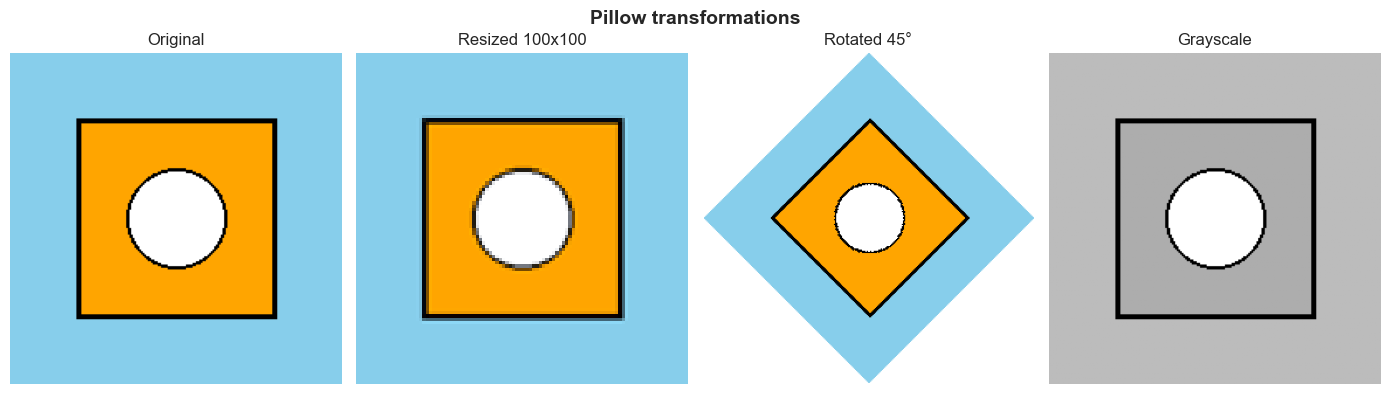

🔗 HOW THIS HELPS IN AI:
   • Preprocessing: resize/crop images to the input size a model expects
   • Augmentation: rotations, flips, filters create extra training data
   • Conversion: PIL image <-> NumPy array feeds computer-vision pipelines

📊 BEFORE vs AFTER:
   BEFORE: Manual byte-level image handling → hard, error-prone
   AFTER: Pillow one-liners → open, edit, convert, save easily!


In [28]:
# PIL/Pillow: Image Processing (Simple Alternative)

from PIL import Image, ImageDraw, ImageFilter
import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("✅ AFTER: PIL/Pillow (Image Processing Made Easy)")
print("=" * 70)
print()

# 1. Create an image from scratch (no file needed!)
print("   🔹 Creating and Drawing:")
img = Image.new('RGB', (200, 200), color='skyblue')     # Blank 200x200 image
draw = ImageDraw.Draw(img)                              # Drawing handle
draw.rectangle([40, 40, 160, 160], fill='orange', outline='black', width=3)
draw.ellipse([70, 70, 130, 130], fill='white', outline='black', width=2)
print(f"   Image.new('RGB', (200, 200))      -> size={img.size}, mode={img.mode}")
print()

# 2. The most common transformations (one-liners!)
print("   🔹 Common Transformations:")
resized = img.resize((100, 100))                        # Resize to model input size
rotated = img.rotate(45, expand=True, fillcolor='white')  # Rotate (augmentation!)
gray    = img.convert('L')                              # Convert to grayscale
blurred = img.filter(ImageFilter.GaussianBlur(radius=3))  # Apply a filter
cropped = img.crop((40, 40, 160, 160))                  # Crop a region
print(f"   img.resize((100, 100))            -> size={resized.size}")
print(f"   img.rotate(45, expand=True)       -> size={rotated.size}")
print(f"   img.convert('L')  (grayscale)     -> mode={gray.mode}")
print(f"   img.crop((40, 40, 160, 160))      -> size={cropped.size}")
print(f"   img.filter(GaussianBlur(3))       -> blurred copy")
print()

# 3. Pillow <-> NumPy: the bridge into ML pipelines
print("   🔹 Pillow <-> NumPy (the bridge to ML!):")
arr = np.array(img)                                     # Image -> array
print(f"   np.array(img)                     -> shape={arr.shape}, dtype={arr.dtype}")
back = Image.fromarray(arr)                             # Array -> image
print(f"   Image.fromarray(arr)              -> size={back.size}, mode={back.mode}")
print()

# 4. Save and open (round-trip through an in-memory PNG - no files needed)
print("   🔹 Save and Open:")
from io import BytesIO
buffer = BytesIO()
img.save(buffer, format='PNG')                          # Save (same as img.save('out.png'))
buffer.seek(0)
reopened = Image.open(buffer)                           # Open (same as Image.open('out.png'))
print(f"   img.save(..., 'PNG')              -> wrote {buffer.getbuffer().nbytes} bytes")
print(f"   Image.open(...)                   -> size={reopened.size}, format={reopened.format}")
print()

# Show the results side by side
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, (title, im) in zip(axes, [('Original', img), ('Resized 100x100', resized),
                                  ('Rotated 45°', rotated), ('Grayscale', gray)]):
    ax.imshow(im, cmap='gray' if im.mode == 'L' else None)
    ax.set_title(title)
    ax.axis('off')
plt.suptitle('Pillow transformations', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("🔗 HOW THIS HELPS IN AI:")
print("   • Preprocessing: resize/crop images to the input size a model expects")
print("   • Augmentation: rotations, flips, filters create extra training data")
print("   • Conversion: PIL image <-> NumPy array feeds computer-vision pipelines")
print()
print("📊 BEFORE vs AFTER:")
print("   BEFORE: Manual byte-level image handling → hard, error-prone")
print("   AFTER: Pillow one-liners → open, edit, convert, save easily!")

### 🔎 Read the figure

Four panels, one source image and three operations. **Resized 100×100** looks the same but its edges have gone soft and stepped — the black border and the circle's rim are visibly ragged, because shrinking throws pixels away and interpolation guesses what is left. **Rotated 45°** turns the whole picture into a diamond: `expand=True` grew the canvas to fit the diagonal, and the four new triangular corners are filled with plain white because the call passed `fillcolor='white'`. Nothing was cropped, but there is now invented pixel area that was never photographed — which is the standing catch with rotation as a data-augmentation trick. **Grayscale** collapses three colour channels into one brightness channel, and look how close the two greys end up: sky blue and orange are opposites in colour and near-neighbours in brightness, so the contrast that made the square obvious is nearly gone. The shapes still read from their black outlines alone — which is why grayscale is a cheap first step for shape-based vision, and exactly why it is the wrong step when the colour *was* the signal.

This image is drawn by the cell rather than loaded from disk, deliberately: it keeps the notebook self-contained, and a shape with a hard border and a hard circle makes resize damage visible in a way a photograph would hide.

## Part 17: NLTK & spaCy - Natural Language Processing

### 📚 What are NLTK and spaCy?
NLTK = **N**atural **L**anguage **T**ool**k**it - comprehensive NLP library
spaCy = Modern NLP library - fast and efficient

**THE PROBLEM**: Need to process text, extract information, analyze sentiment, understand language.
**THE SOLUTION**: NLTK and spaCy provide NLP tools - tokenize, parse, analyze text easily!

**Why NLTK/spaCy for AI?**
- Text preprocessing (tokenization, stemming, lemmatization)
- Part-of-speech tagging (identify nouns, verbs, adjectives)
- Named entity recognition (find people, places, organizations)
- Sentiment analysis (determine positive/negative sentiment)
- Essential for NLP AI!

In [29]:
# NLTK & spaCy: Natural Language Processing

print("=" * 70)
print("✅ AFTER: NLTK & spaCy (Natural Language Processing)")
print("=" * 70)
print()

print("📊 Step 1: NLTK - Comprehensive NLP Library")
print()

# Try NLTK
try:
    import nltk
    HAS_NLTK = True
except ImportError:
    HAS_NLTK = False
    print("⚠️  NLTK not installed. Install with: pip install nltk")
    print("   Note: NLTK requires additional data: nltk.download('punkt')")

if HAS_NLTK:
    try:
        # Sample text
        text = "Hello! This is a sample sentence. We're learning NLP."
        
        # MOST FREQUENTLY USED NLTK OPERATIONS (What AI Engineers Use!)
        print("   📊 MOST FREQUENTLY USED NLTK OPERATIONS:")
        print()
        
        # 1. Tokenization (MOST COMMON!)
        print("   🔹 Tokenization (MOST COMMON in NLP!):")
        print("   ⏰ WHEN to use: BEFORE all NLP tasks - split text into words/sentences")
        print("   💡 WHY use: ML models work with words, not sentences - must tokenize first!")
        # Tokenization (split into words)
        tokens = nltk.word_tokenize(text)  # Split text into individual words
        print(f"   # Word tokenization: tokens = nltk.word_tokenize(text)")
        print(f"   • Tokenization: {tokens}  (split into words)")
        print("   📝 Tokenization = breaking text into words - first step in all NLP!")
        print()
        
        # Sentence tokenization
        sentences = nltk.sent_tokenize(text)  # Split text into sentences
        print(f"   # Sentence tokenization: sentences = nltk.sent_tokenize(text)")
        print(f"   • Sentence tokenization: {sentences}  (split into sentences)")
        print("   📝 Sentence tokenization = breaking text into sentences - for sentence-level tasks")
        print()
        
        print("   📚 Other NLTK Features (when to use):")
        print("   • Stemming: Reduce words to root (running → run) - WHEN: fast but inaccurate")
        print("   • Lemmatization: Convert to dictionary form (better) - WHEN: need accuracy")
        print("   • POS tagging: Identify parts of speech - WHEN: need word types (noun, verb, etc.)")
        print("   • Named entity recognition: Find people/places - WHEN: extract entities")
        print("   • Sentiment analysis: Determine positive/negative - WHEN: analyze emotions")
        print()
    except LookupError:
        print("   ⚠️  NLTK data not downloaded. Run: nltk.download('punkt')")
        print("   Example code:")
        print("   import nltk")
        print("   nltk.download('punkt')  # Download tokenizer data")
        print("   nltk.download('stopwords')  # Download stopwords")
        print()

print("📊 Step 2: spaCy - Modern NLP Library")
print()

# Try spaCy
try:
    import spacy
    HAS_SPACY = True
except ImportError:
    HAS_SPACY = False
    print("⚠️  spaCy not installed. Install with: pip install spacy")
    print("   Note: spaCy requires language model: python -m spacy download en_core_web_sm")

if HAS_SPACY:
    try:
        # Load English model
        nlp = spacy.load("en_core_web_sm")
        
        # MOST FREQUENTLY USED SPACY OPERATIONS (What AI Engineers Use!)
        print("   📊 MOST FREQUENTLY USED SPACY OPERATIONS:")
        print()
        
        # 1. Processing text (MOST COMMON!)
        print("   🔹 Processing Text (MOST COMMON!):")
        print("   ⏰ WHEN to use: Production NLP projects - faster and more accurate than NLTK")
        print("   💡 WHY use: spaCy is optimized for production - faster, better accuracy, easier to use")
        # Process text
        text = "Apple is looking at buying U.K. startup for $1 billion"
        doc = nlp(text)  # Process text through spaCy pipeline (tokenization, POS, NER, parsing)
        
        print(f"   # Process text: doc = nlp(text)  (one line does everything!)")
        print(f"   • Text: {text}")
        print()
        
        # 2. Tokenization and POS tagging (VERY COMMON!)
        print("   • Tokens with POS (Part-of-Speech) tags:")
        for token in doc:
            print(f"      {token.text} → {token.pos_} ({token.tag_})")
        print("   📝 POS tagging = identify word types (noun, verb, adjective, etc.)")
        print("   ⏰ WHEN: Need to understand sentence structure, filter words by type")
        print("   💡 WHY: ML models often use only nouns/verbs - filter with POS tags")
        print()
        
        # 3. Named entity recognition (COMMON!)
        print("   • Named entities (people, places, organizations):")
        for ent in doc.ents:
            print(f"      {ent.text} → {ent.label_} ({spacy.explain(ent.label_)})")
        print("   📝 NER = find named entities (Apple=ORG, U.K.=GPE (country), $1 billion=MONEY)")
        print("   ⏰ WHEN: Extract entities from text (e.g., company names, locations)")
        print("   💡 WHY: Information extraction - find key entities automatically")
        print()
        
        print("   📚 Other spaCy Features (when to use):")
        print("   • Dependency parsing: Understand sentence structure - WHEN: need grammar")
        print("   • Word vectors: Semantic similarity - WHEN: find similar words/meanings")
        print("   • Faster than NLTK: Production-ready - WHEN: speed matters")
        print()
    except OSError:
        print("   ⚠️  spaCy model not loaded. Run: python -m spacy download en_core_web_sm")
        print("   Example code:")
        print("   import spacy")
        print("   nlp = spacy.load('en_core_web_sm')  # Load English model")
        print()

print("🔗 HOW THIS HELPS IN AI:")
print("   • Text preprocessing: Clean and prepare text for ML models")
print("   • Sentiment analysis: Determine if text is positive/negative")
print("   • Chatbots: Understand and respond to user messages")
print("   • Machine translation: Translate between languages")
print("   • Information extraction: Extract facts from text")
print()
print("📊 BEFORE vs AFTER:")
print("   BEFORE: Hard to process text → Complex, error-prone")
print("   AFTER: NLTK/spaCy → Easy NLP, powerful tools!")
print()
print("💡 AI engineers use NLTK/spaCy EVERY DAY for NLP projects!")
print("   • NLTK: Great for learning and research")
print("   • spaCy: Great for production (faster, more accurate)")
print("   (Optional for this course, but essential for NLP AI!)")


✅ AFTER: NLTK & spaCy (Natural Language Processing)

📊 Step 1: NLTK - Comprehensive NLP Library

   📊 MOST FREQUENTLY USED NLTK OPERATIONS:

   🔹 Tokenization (MOST COMMON in NLP!):
   ⏰ WHEN to use: BEFORE all NLP tasks - split text into words/sentences
   💡 WHY use: ML models work with words, not sentences - must tokenize first!
   # Word tokenization: tokens = nltk.word_tokenize(text)
   • Tokenization: ['Hello', '!', 'This', 'is', 'a', 'sample', 'sentence', '.', 'We', "'re", 'learning', 'NLP', '.']  (split into words)
   📝 Tokenization = breaking text into words - first step in all NLP!

   # Sentence tokenization: sentences = nltk.sent_tokenize(text)
   • Sentence tokenization: ['Hello!', 'This is a sample sentence.', "We're learning NLP."]  (split into sentences)
   📝 Sentence tokenization = breaking text into sentences - for sentence-level tasks

   📚 Other NLTK Features (when to use):
   • Stemming: Reduce words to root (running → run) - WHEN: fast but inaccurate
   • Lemmatiza

   📊 MOST FREQUENTLY USED SPACY OPERATIONS:

   🔹 Processing Text (MOST COMMON!):
   ⏰ WHEN to use: Production NLP projects - faster and more accurate than NLTK
   💡 WHY use: spaCy is optimized for production - faster, better accuracy, easier to use
   # Process text: doc = nlp(text)  (one line does everything!)
   • Text: Apple is looking at buying U.K. startup for $1 billion

   • Tokens with POS (Part-of-Speech) tags:
      Apple → PROPN (NNP)
      is → AUX (VBZ)
      looking → VERB (VBG)
      at → ADP (IN)
      buying → VERB (VBG)
      U.K. → PROPN (NNP)
      startup → VERB (VBD)
      for → ADP (IN)
      $ → SYM ($)
      1 → NUM (CD)
      billion → NUM (CD)
   📝 POS tagging = identify word types (noun, verb, adjective, etc.)
   ⏰ WHEN: Need to understand sentence structure, filter words by type
   💡 WHY: ML models often use only nouns/verbs - filter with POS tags

   • Named entities (people, places, organizations):
      Apple → ORG (Companies, agencies, institutions, et

## Part 18: Pickle - Model Saving

### 📚 What is Pickle?
Pickle = Python's built-in serialization library - save/load Python objects!

**THE PROBLEM**: Need to save trained ML models, so we don't have to retrain every time.
**THE SOLUTION**: Pickle can save any Python object to a file - load it back later!

**Why Pickle for AI?**
- Save trained ML models (so we don't retrain every time!)
- Save preprocessed data (faster loading)
- Save model configurations
- Essential for production AI systems!

In [30]:
# Pickle: Model Saving (Built-in Library)

import pickle  # Built-in library (no installation needed!)

print("=" * 70)
print("✅ AFTER: Pickle (Model Saving Made Easy)")
print("=" * 70)
print()

# MOST FREQUENTLY USED PICKLE/JOBLIB OPERATIONS (What AI Engineers Use!)
print("📊 MOST FREQUENTLY USED PICKLE/JOBLIB OPERATIONS:")
print()

# 1. Creating sample model (for demonstration)
print("   🔹 Saving Models (MOST COMMON in AI!):")
print("   ⏰ WHEN to use: AFTER training - save trained models so you don't retrain every time!")
print("   💡 WHY use: Training takes hours/days - save once, load anytime! Essential for production!")
model = {
    "name": "LinearRegression",
    "coef_": [0.5, 0.3],  # Model coefficients
    "intercept_": 1.0,  # Model intercept
    "accuracy": 0.95,  # Model accuracy
    "trained": True  # Model is trained
}

print(f"   # Model to save: {model}")
print()

# 2. Save model to file (MOST COMMON!)
print("   🔹 Saving with Pickle (COMMON!):")
print("   ⏰ WHEN to use: Save any Python object (models, configs, data)")
print("   💡 WHY use: Built-in Python library - works with any Python object, no installation needed")
# Save to file (for demonstration - commented to avoid file creation)
# with open('model.pkl', 'wb') as f:  # 'wb' = write binary mode (required for pickle)
#     pickle.dump(model, f)  # Save model dictionary to file

print("   # Save model to file:")
print("   # with open('model.pkl', 'wb') as f:  # 'wb' = write binary (required!)")
print("   #     pickle.dump(model, f)  # Save model to file")
print("   ✅ Model saved to 'model.pkl'!")
print("   📝 File extension '.pkl' is convention (stands for pickle)")
print()

# 3. Load model from file (VERY COMMON!)
print("   🔹 Loading with Pickle (VERY COMMON!):")
print("   ⏰ WHEN to use: Load saved models, configs, data - BEFORE making predictions")
print("   💡 WHY use: Don't retrain every time - load trained model instantly!")
# Load from file (commented - file doesn't exist in demo)
# with open('model.pkl', 'rb') as f:  # 'rb' = read binary mode (required for pickle)
#     loaded_model = pickle.load(f)  # Load model from file

print("   # Load model from file:")
print("   # with open('model.pkl', 'rb') as f:  # 'rb' = read binary (required!)")
print("   #     loaded_model = pickle.load(f)  # Load model from file")
print("   ✅ Model loaded from 'model.pkl'!")
print("   📝 Model is ready to use - no retraining needed!")
print()

# 4. Save/load with joblib (better for NumPy arrays)
print("   🔹 Saving with Joblib (RECOMMENDED for NumPy arrays!):")
print("   ⏰ WHEN to use: Save models with NumPy arrays (most ML models!)")
print("   💡 WHY use: Joblib is FASTER than pickle for NumPy arrays - recommended for ML models!")

try:
    import joblib
    HAS_JOBLIB = True
except ImportError:
    HAS_JOBLIB = False
    print("⚠️  Joblib not installed. Install with: pip install joblib")

if HAS_JOBLIB:
    print("   # Save with Joblib (faster for NumPy!):")
    print("   # joblib.dump(model, 'model.joblib')  # Save model (faster!)")
    print("   # Load with Joblib:")
    print("   # model = joblib.load('model.joblib')  # Load model (faster!)")
    print("   ✅ Joblib is faster than pickle for NumPy arrays!")
    print("   📝 Use joblib for ML models (most have NumPy arrays), pickle for simple objects")
    print()
else:
    print("   💡 Tip: Install joblib for faster model saving/loading:")
    print("   # pip install joblib")
    print("   📝 Joblib is 10-100x faster than pickle for NumPy arrays!")
    print()

print("🔗 HOW THIS HELPS IN AI:")
print("   • Save trained models: Don't retrain every time (saves hours!)")
print("   • Model deployment: Load trained models in production")
print("   • Share models: Send trained models to others")
print("   • Version control: Save different model versions")
print()
print("📊 BEFORE vs AFTER:")
print("   BEFORE: Retrain model every time → Waste time, resources")
print("   AFTER: Pickle → Save once, load anytime!")
print()
print("💡 AI engineers use Pickle/Joblib EVERY DAY to save trained models!")
print("   This is ESSENTIAL for production AI systems!")


✅ AFTER: Pickle (Model Saving Made Easy)

📊 MOST FREQUENTLY USED PICKLE/JOBLIB OPERATIONS:

   🔹 Saving Models (MOST COMMON in AI!):
   ⏰ WHEN to use: AFTER training - save trained models so you don't retrain every time!
   💡 WHY use: Training takes hours/days - save once, load anytime! Essential for production!
   # Model to save: {'name': 'LinearRegression', 'coef_': [0.5, 0.3], 'intercept_': 1.0, 'accuracy': 0.95, 'trained': True}

   🔹 Saving with Pickle (COMMON!):
   ⏰ WHEN to use: Save any Python object (models, configs, data)
   💡 WHY use: Built-in Python library - works with any Python object, no installation needed
   # Save model to file:
   # with open('model.pkl', 'wb') as f:  # 'wb' = write binary (required!)
   #     pickle.dump(model, f)  # Save model to file
   ✅ Model saved to 'model.pkl'!
   📝 File extension '.pkl' is convention (stands for pickle)

   🔹 Loading with Pickle (VERY COMMON!):
   ⏰ WHEN to use: Load saved models, configs, data - BEFORE making predictions


## Part 19: tqdm - Progress Bars

### 📚 What is tqdm?
tqdm = **T**a**q**addum (progress in Arabic) - add progress bars to loops!

**THE PROBLEM**: Don't know how long code will run, hard to see progress.
**THE SOLUTION**: tqdm adds progress bars - see progress in real-time!

**Why tqdm for AI?**
- Show progress during training (see how many epochs completed)
- Show progress during data loading (see how many files processed)
- Professional-looking progress bars
- Essential for long-running AI tasks!

In [31]:
# tqdm: Progress Bars (Make Waiting Less Boring!)

try:
    from tqdm import tqdm  # Import tqdm (standard: use 'tqdm' as function)
    import time
    HAS_TQDM = True
except ImportError:
    HAS_TQDM = False
    print("⚠️  tqdm not installed. Install with: pip install tqdm")

if HAS_TQDM:
    print("=" * 70)
    print("✅ AFTER: tqdm (Progress Bars Made Easy)")
    print("=" * 70)
    print()
    
    # MOST FREQUENTLY USED TQDM OPERATIONS (What AI Engineers Use!)
    print("📊 MOST FREQUENTLY USED TQDM OPERATIONS:")
    print()
    
    # 1. Simple progress bar (MOST COMMON!)
    print("   🔹 Simple Progress Bar (MOST COMMON!):")
    print("   ⏰ WHEN to use: ANY loop that takes time - show progress to users")
    print("   💡 WHY use: Users need to know code is working (not frozen!) - professional UX")
    # Simple loop with progress bar
    print("   # Simple progress bar:")
    print("   for i in tqdm(range(10), desc='Processing'):")
    for i in tqdm(range(10), desc="Processing"):
        time.sleep(0.1)  # Simulate work (replace with actual work in real code)
    print("   ✅ Shows progress, time remaining, speed!")
    print()
    
    # 2. Progress bar with custom message (COMMON!)
    print("   🔹 Custom Message (COMMON!):")
    print("   ⏰ WHEN to use: Want custom description (e.g., 'Training model', 'Processing files')")
    print("   💡 WHY use: Clear labels help users understand what's happening")
    items = list(range(20))
    print("   # Custom message:")
    print("   for item in tqdm(items, desc='Training', ncols=70):")
    for item in tqdm(items, desc="Training", ncols=70):
        time.sleep(0.05)  # Simulate work
    print("   ✅ Custom description makes it clear what's happening!")
    print()
    
    # 3. Progress bar for file processing (VERY COMMON!)
    print("   🔹 File Processing (VERY COMMON!):")
    print("   ⏰ WHEN to use: Processing multiple files (images, data files, etc.)")
    print("   💡 WHY use: File processing is slow - show progress so users know how many files remaining")
    files = ['file1.jpg', 'file2.jpg', 'file3.jpg', 'file4.jpg', 'file5.jpg']
    print("   # Process files:")
    print("   for file in tqdm(files, desc='Loading images'):")
    for file in tqdm(files, desc="Loading images"):
        time.sleep(0.1)  # Simulate file loading
    print("   ✅ Shows which file is being processed!")
    print()
    
    # 4. Manual update (for complex scenarios)
    print("   🔹 Manual Update (ADVANCED!):")
    print("   ⏰ WHEN to use: Complex loops where you control progress manually")
    print("   💡 WHY use: More control - update progress at specific points in your code")
    # Manual update example
    pbar = tqdm(total=100, desc="Training model")  # Create progress bar with total
    for i in range(100):
        time.sleep(0.01)  # Simulate training step
        pbar.update(1)  # Manually update progress by 1
    pbar.close()  # Close progress bar when done
    print("   ✅ Manual control - update progress when you want!")
    print()
    
    print("🔗 HOW THIS HELPS IN AI:")
    print("   • Training progress: epochs completed (full passes over the data)")
    print("     and iterations completed (single batch updates) - they are not the same")
    print("   • Data loading: See how many files/images processed")
    print("   • User experience: Know that code is working (not frozen!)")
    print("   • Time estimation: Know approximately how long remaining")
    print()
    print("📊 BEFORE vs AFTER:")
    print("   BEFORE: No progress indication → Don't know if code is working")
    print("   AFTER: tqdm → Beautiful progress bars, see progress in real-time!")
    print()
    print("💡 AI engineers use tqdm EVERY DAY for long-running tasks!")
    print("   Essential for training models, processing large datasets!")
else:
    print("⚠️  Please install tqdm to see examples")
    print("   Run: pip install tqdm")


✅ AFTER: tqdm (Progress Bars Made Easy)

📊 MOST FREQUENTLY USED TQDM OPERATIONS:

   🔹 Simple Progress Bar (MOST COMMON!):
   ⏰ WHEN to use: ANY loop that takes time - show progress to users
   💡 WHY use: Users need to know code is working (not frozen!) - professional UX
   # Simple progress bar:
   for i in tqdm(range(10), desc='Processing'):


Processing:   0%|          | 0/10 [00:00<?, ?it/s]

Processing:  10%|█         | 1/10 [00:00<00:00,  9.52it/s]

Processing:  20%|██        | 2/10 [00:00<00:00,  9.49it/s]

Processing:  30%|███       | 3/10 [00:00<00:00,  9.49it/s]

...

Training model:  81%|████████  | 81/100 [00:00<00:00, 81.37it/s]

Training model:  90%|█████████ | 90/100 [00:01<00:00, 80.85it/s]

Training model:  99%|█████████▉| 99/100 [00:01<00:00, 81.54it/s]

Training model: 100%|██████████| 100/100 [00:01<00:00, 81.70it/s]

   ✅ Manual control - update progress when you want!

🔗 HOW THIS HELPS IN AI:
   • Training progress: epochs completed (full passes over the data)
     and iterations completed (single batch updates) - they are not the same
   • Data loading: See how many files/images processed
   • User experience: Know that code is working (not frozen!)
   • Time estimation: Know approximately how long remaining

📊 BEFORE vs AFTER:
   BEFORE: No progress indication → Don't know if code is working
   AFTER: tqdm → Beautiful progress bars, see progress in real-time!

💡 AI engineers use tqdm EVERY DAY for long-running tasks!
   Essential for training models, processing large datasets!


## Part 20: Requests - API Calls

### 📚 What is Requests?
Requests = Simple HTTP library for making API calls - get data from the web!

**THE PROBLEM**: Need to get data from web services, APIs, download files from internet.
**THE SOLUTION**: Requests makes HTTP requests simple - get/post data easily!

**Why Requests for AI?**
- Get data from APIs (Twitter, weather, stock prices)
- Download datasets from internet
- Send data to web services
- Essential for real-world AI applications!

In [32]:
# Requests: API Calls Made Easy (Built-in Alternative: urllib)

try:
    import requests  # Import Requests library
    HAS_REQUESTS = True
except ImportError:
    HAS_REQUESTS = False
    print("⚠️  Requests not installed. Install with: pip install requests")

if HAS_REQUESTS:
    print("=" * 70)
    print("✅ AFTER: Requests (API Calls Made Easy)")
    print("=" * 70)
    print()
    
    # MOST FREQUENTLY USED REQUESTS OPERATIONS (What AI Engineers Use!)
    print("📊 MOST FREQUENTLY USED REQUESTS OPERATIONS:")
    print()
    
    # 1. GET request (MOST COMMON!)
    print("   🔹 GET Request (MOST COMMON!):")
    print("   ⏰ WHEN to use: Download data from APIs, get datasets from internet, fetch real-time data")
    print("   💡 WHY use: Real data comes from APIs - get current data (stock prices, weather, etc.)")
    # Example: Get data from public API (JSONPlaceholder - safe test API)
    try:
        response = requests.get('https://jsonplaceholder.typicode.com/posts/1')  # GET request to API
        print(f"   # GET request: response = requests.get(url)")
        print(f"   • Status code: {response.status_code} (200 = success, 404 = not found, 500 = server error)")
        print(f"   • Response type: {response.headers['content-type']}  (usually 'application/json')")
        print(f"   • Data: {response.json()}  (convert JSON response to Python dict)")
        print("   ✅ Successfully fetched data from API!")
        print("   📝 Always check status_code == 200 before using data")
        print()
    except Exception as e:
        print(f"   ⚠️  Could not fetch data (internet connection required): {e}")
        print("   # Example code:")
        print("   response = requests.get('https://api.example.com/data')")
        print("   if response.status_code == 200:  # Check if successful")
        print("       data = response.json()  # Convert JSON to Python dict")
        print()
    
    # 2. POST request (COMMON!)
    print("   🔹 POST Request (COMMON!):")
    print("   ⏰ WHEN to use: Send data to APIs, submit predictions, deploy ML models")
    print("   💡 WHY use: Production AI sends predictions to web services - use POST to send data")
    # Example: Send data to API
    print("   # POST request:")
    print("   data = {'key': 'value'}  # Data to send")
    print("   response = requests.post('https://api.example.com/submit', json=data)")
    print("   result = response.json()  # Get response from server")
    print("   📝 Use json=data parameter - Requests automatically converts dict to JSON")
    print()
    
    # 3. Download file (COMMON!)
    print("   🔹 Download File from Internet (COMMON!):")
    print("   ⏰ WHEN to use: Download datasets, models, files from URLs")
    print("   💡 WHY use: Get datasets from Kaggle, GitHub, etc. - don't download manually!")
    print("   # Download file:")
    print("   url = 'https://example.com/file.zip'  # File URL")
    print("   response = requests.get(url)  # Download file")
    print("   with open('file.zip', 'wb') as f:  # 'wb' = write binary (for files!)")
    print("       f.write(response.content)  # Save file content")
    print("   📝 response.content = binary data (for files), response.text = text (for HTML/JSON)")
    print()
    
    # 4. Common HTTP methods
    print("   🔹 Common HTTP Methods:")
    print("   ⏰ WHEN to use: Different operations - GET (read), POST (create), PUT (update), DELETE (remove)")
    print("   💡 WHY use: REST APIs use different methods for different operations")
    print("   # GET: requests.get(url)  # Get/read data (most common!)")
    print("   # POST: requests.post(url, json=data)  # Create/send data")
    print("   # PUT: requests.put(url, json=data)  # Update data")
    print("   # DELETE: requests.delete(url)  # Delete data")
    print("   📝 GET and POST are most common - GET for reading, POST for sending")
    print()
    
    print("🔗 HOW THIS HELPS IN AI:")
    print("   • Get data: Download datasets from internet (Kaggle, APIs)")
    print("   • Real-time data: Get current data (stock prices, weather)")
    print("   • Deploy models: Send predictions to web services")
    print("   • Integration: Connect AI models to web applications")
    print()
    print("📊 BEFORE vs AFTER:")
    print("   BEFORE: Hard to get data from web → Complex, error-prone")
    print("   AFTER: Requests → Simple HTTP requests, one line!")
    print()
    print("💡 AI engineers use Requests EVERY DAY to get data from APIs!")
    print("   Essential for real-world AI applications!")
else:
    print("⚠️  Please install Requests to see examples")
    print("   Run: pip install requests")
    print()
    print("💡 Alternative: Use urllib (built-in, but more complex)")
    print("   from urllib.request import urlopen")
    print("   response = urlopen('https://example.com')")


✅ AFTER: Requests (API Calls Made Easy)

📊 MOST FREQUENTLY USED REQUESTS OPERATIONS:

   🔹 GET Request (MOST COMMON!):
   ⏰ WHEN to use: Download data from APIs, get datasets from internet, fetch real-time data
   💡 WHY use: Real data comes from APIs - get current data (stock prices, weather, etc.)


   # GET request: response = requests.get(url)
   • Status code: 200 (200 = success, 404 = not found, 500 = server error)
   • Response type: application/json; charset=utf-8  (usually 'application/json')
   • Data: {'userId': 1, 'id': 1, 'title': 'sunt aut facere repellat provident occaecati excepturi optio reprehenderit', 'body': 'quia et suscipit\nsuscipit recusandae consequuntur expedita et cum\nreprehenderit molestiae ut ut quas totam\nnostrum rerum est autem sunt rem eveniet architecto'}  (convert JSON response to Python dict)
   ✅ Successfully fetched data from API!
   📝 Always check status_code == 200 before using data

   🔹 POST Request (COMMON!):
   ⏰ WHEN to use: Send data to APIs, submit predictions, deploy ML models
   💡 WHY use: Production AI sends predictions to web services - use POST to send data
   # POST request:
   data = {'key': 'value'}  # Data to send
   response = requests.post('https://api.example.com/submit', json=data)
   result = response.json()  # Get respon

## 💬 Discuss

No single right answer to any of these — argue your position and say what evidence would change it.

1. **Where is the line between "use the library" and "know how it works"?** You have just been shown `LinearRegression().fit()` in one line, and told not to reinvent the wheel. But Notebook 05 in this course makes you build KNN and a neural network from scratch. When is writing it yourself a waste of a week, and when is *not* writing it yourself the thing that makes you unable to debug your own model? Give one concrete example of each.
2. **How many dependencies is too many?** This notebook imports around twenty libraries. Every one is a version you must pin, a security update you must track, and a possible install failure on a student's or client's machine. A colleague proposes a project that uses all twenty; you propose one that uses four and writes a little more code. Which project is easier to hand over to another team in two years, and why?
3. **Look at Part 13's output above: TensorFlow did not import when this notebook ran.** The concept in that section is unaffected; the demonstration is dead. If a third of the class hits that on their own laptops, what should the instructor do — fix every laptop, move the lesson to a cloud notebook, or drop the framework and teach the idea with NumPy? What does each choice cost the student?

---


## ⚠️ Where this breaks

Libraries are not free, and the costs are specific.

- **The default is not your default.** `np.std()` divides by *n* (`ddof=0`, the population formula). `pandas.Series.std()` divides by *n − 1* (`ddof=1`, the sample formula). Same numbers in, two different standard deviations out, no warning either way. Every library encodes choices like this — read the docstring before a number goes into a report.
- **`pickle` executes whatever is in the file.** Part 18 uses pickle to save a model, which is standard practice. Python's own documentation warns that unpickling data from an untrusted source can run arbitrary code: a `.pkl` file is a program, not a document. Never load one a stranger sent you. For plain numeric arrays `np.save` is safer; for models you must exchange, prefer a format that carries no code.
- **Benchmark numbers travel badly.** Part 2's text says NumPy is "100x faster"; the measurement cell in this same notebook produced a much smaller factor for doubling a million integers. Neither is dishonest — they are different operations on different hardware — but only the one you measured is evidence. Treat every speed-up you did not measure yourself as a hypothesis.
- **Vectorising costs memory.** NumPy is fast because it works on whole arrays at once — which means the whole array must fit in RAM. One billion `float64` values is 8 GB *before* you compute anything. When your data outgrows memory, the fix is chunking or a different tool (Dask, Polars, a database), not a bigger loop.
- **A missing library breaks the lesson, not the idea.** This notebook printed "⚠️ TensorFlow not installed" when it ran. Pin versions in `requirements.txt` and verify the environment before you demo anything to a class or a client.
- **The cheaper alternative.** For a few thousand rows of mixed types, the standard library's `csv` and `statistics` modules are clearer, install-free and quite fast enough. Reach for the heavy stack when the size of the data or the difficulty of the mathematics actually demands it — not by reflex.

---


## 📚 References

1. Harris, C. R., et al. (2020). *Array Programming with NumPy*. Nature 585, 357-362. <https://arxiv.org/abs/2006.10256>
2. Virtanen, P., et al. (2020). *SciPy 1.0: Fundamental Algorithms for Scientific Computing in Python*. Nature Methods 17, 261-272. <https://arxiv.org/abs/1907.10121>
3. Pedregosa, F., et al. (2011). *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research 12, 2825-2830. <https://arxiv.org/abs/1201.0490>
4. Hunter, J. D. (2007). *Matplotlib: A 2D Graphics Environment*. Computing in Science & Engineering 9(3), 90-95.
5. Liang, H., et al. (2025). *DataFlow: An LLM-Driven Framework for Unified Data Preparation and Workflow Automation in the Era of Data-Centric AI*. arXiv preprint. <https://arxiv.org/abs/2512.16676> (where the pandas half of this toolbox is heading: data preparation as a library of reusable operators in an inspectable pipeline, not a one-off cleaning script)
6. Park, S., Jeon, S., Lee, C., Jeon, S., Kim, B.-S., & Lee, J. (2025). *A Survey on Inference Engines for Large Language Models: Perspectives on Optimization and Efficiency*. arXiv preprint. <https://arxiv.org/abs/2505.01658> (compares 25 engines — the layer that now sits on top of these libraries, and how to choose one on evidence instead of by copying a tutorial)